In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from mordred import Calculator, descriptors
import padelpy
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, QED, GraphDescriptors, Lipinski
import os

from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer

from sklearn.model_selection import GridSearchCV, LeaveOneOut, train_test_split, cross_validate, KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.neural_network import MLPRegressor
import scipy.stats as stats
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
import json
import scipy.stats as stats
from scipy.stats import linregress
import shap
from pprint import pprint
import optuna
from optuna.integration import OptunaSearchCV
from optuna.distributions import IntDistribution, FloatDistribution
import itertools

import tensorflow as tf
layers, TFModels, optimizers, ImageDataGenerator, regularizers = tf.keras.layers, tf.keras.models, tf.keras.optimizers, tf.keras.preprocessing.image.ImageDataGenerator, tf.keras.regularizers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from keras.models import load_model
from tensorflow import device


pd.options.display.max_rows = 100
pd.options.display.max_columns = 100
pd.options.display.max_colwidth = 200
pd.options.display.max_info_columns = 3000


In [2]:
df = pd.read_excel(r"E:\My Articles\02 Ongoing\Data PK.xlsx")
df

,No.,Compound,Dose (mg/kg),Ref,Drug Name,Rout of administration,Type (Radioactive/Simple),Dossage form,Animal / Human,unit of Dose,Sex,Strain,Fast / Not Fast,MW,T max (hr),C max,unit of Cmax,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,unit AUC,T 1/2 (hr),Canonical SMILES Ref,Canonical SMILES,Distribution data,Comment
0,1.0,ABILIFY,3.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,fast,NaN,1.0,7.90,ng/ml,12.00,2.0,NaN,ng.hr/ml,NaN,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,mice
1,1.0,ABILIFY,10.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,fast,NaN,2.0,86.00,ng/ml,249.00,6.0,30.0,ng.hr/ml,2.2,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN
2,1.0,ABILIFY,30.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,fast,NaN,4.0,442.00,ng/ml,3044.00,12.0,3135.0,ng.hr/ml,1.9,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN
3,1.0,ABILIFY,30.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,nonfast,NaN,2.0,374.00,ng/ml,2948.00,12.0,3138.0,ng.hr/ml,2.6,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN
4,1.0,ABILIFY,10.0,p2 42,Aripiprazole,oral,simple,NaN,rat,mg/kg,female,NaN,fast,NaN,3.0,158.00,ng/ml,616.00,8.0,645.0,ng.hr/ml,1,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,34.0,EGATEN,10.0,r1 45,triclabendazole,oral,rad,NaN,rat,mg/kg,male,NaN,fast,359.665,8.0,20.00,umol/l,NaN,NaN,413.0,umol.h/l,NaN,https://pubchem.ncbi.nlm.nih.gov/compound/Triclabendazole,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,NaN,NaN
210,34.0,EGATEN,80.0,r1 45,triclabendazole,oral,rad,NaN,rat,mg/kg,male,NaN,fast,359.665,8.0,81.50,umol/l,NaN,NaN,2104.0,umol.h/l,NaN,https://pubchem.ncbi.nlm.nih.gov/compound/Triclabendazole,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,NaN,NaN
211,34.0,EGATEN,750.0,r1 225,triclabendazole,oral,simple,NaN,human,mg,NaN,NaN,nonfast,359.665,2.0,1.68,umol/l,8.08,72.0,NaN,umol.h/l,7.4,https://pubchem.ncbi.nlm.nih.gov/compound/Triclabendazole,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,NaN,NaN
212,35.0,ELIQUIS,2.0,p1 28,apixaban,oral,simple,NaN,rat,mg/kg,NaN,NaN,NaN,NaN,0.5,1.10,ug/ml,2.70,24.0,NaN,ug.hr/ml,3.5,https://pubchem.ncbi.nlm.nih.gov/compound/Apixaban,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,NaN,NaN


# Just oral

In [3]:
df = df[df['Rout of administration']=='oral']

# Make all units the same

In [4]:
df['unit of Cmax'].value_counts()

unit of Cmax
ng/ml     136
ug/ml      55
umol/l     15
Name: count, dtype: int64

## convert molecular concentration by MW

In [5]:
mask = df['unit of Cmax'].str.contains('mol', na=False)
df.loc[mask, ['C max', 'AUC 0-t (ng.hr/ml)', 'AUC 0-inf']] = \
    df.loc[mask, ['C max', 'AUC 0-t (ng.hr/ml)', 'AUC 0-inf']].multiply(df.loc[mask, 'MW'], axis=0) / 1000 # because of ml

df.loc[mask, ['unit of Cmax', 'unit AUC']] = \
    df.loc[mask, ['unit of Cmax', 'unit AUC']].replace('mol', 'g', regex=True)

df.loc[mask, ['unit of Cmax', 'unit AUC']] = \
    df.loc[mask, ['unit of Cmax', 'unit AUC']].replace('/l', '/ml', regex=True)

# df.loc[mask]

## convert units of AUC to ng/ml

In [6]:
print(df['unit of Cmax'].value_counts())
print()
print('AUC')
print(df['unit AUC'].value_counts())

unit of Cmax
ng/ml    136
ug/ml     70
Name: count, dtype: int64

AUC
unit AUC
ng.hr/ml    104
ug.hr/ml     70
ug.h/ml      15
ng.h/ml       9
Name: count, dtype: int64


In [7]:
# Extract the prefix (first character)
prefix = df['unit AUC'].str.extract(r'(^.)')[0]

# Define conversion factors relative to 'n' (nano) as base = 1
conversion_map = {
    'u': 1000,      # micro → nano: multiply by 1000
    'n': 1,          # nano → nano: no change
    'p': 1/1000,     # pico → nano: multiply by 1/1000 (0.001)
}

factor = prefix.map(conversion_map)

# Apply the conversion
cols = ['AUC 0-t (ng.hr/ml)', 'AUC 0-inf']
df[cols] = df[cols].multiply(factor, axis=0)
df[['AUC 0-t (ng.hr/ml)', 'AUC 0-inf', 'unit AUC']]

C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\3850531266.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[cols] = df[cols].multiply(factor, axis=0)


,AUC 0-t (ng.hr/ml),AUC 0-inf,unit AUC
0,12.0000,NaN,ng.hr/ml
1,249.0000,30.000,ng.hr/ml
2,3044.0000,3135.000,ng.hr/ml
3,2948.0000,3138.000,ng.hr/ml
4,616.0000,645.000,ng.hr/ml
...,...,...,...
209,NaN,148541.645,ug.h/ml
210,NaN,756735.160,ug.h/ml
211,2906.0932,NaN,ug.h/ml
212,2700.0000,NaN,ug.hr/ml


## convert units of Cmax to ng/ml

In [8]:
# Extract the prefix (first character)
prefix = df['unit of Cmax'].str.extract(r'(^.)')[0]

# Define conversion factors relative to 'n' (nano) as base = 1
conversion_map = {
    'u': 1000,      # micro → nano: multiply by 1000
    'n': 1,          # nano → nano: no change
    'p': 1/1000,     # pico → nano: multiply by 1/1000 (0.001)
}

factor = prefix.map(conversion_map)

# Apply the conversion
df['C max'] = df['C max'].multiply(factor, axis=0)


C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\554875659.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['C max'] = df['C max'].multiply(factor, axis=0)


In [9]:
# df.sort_values('C max').head(200)

In [36]:
rdf = df.copy()
# cl_df_copy = cl_df.copy()
rdf.columns

Index(['No.', 'Compound', 'Dose (mg/kg)', 'Ref', 'Drug Name',
       'Rout of administration', 'Type (Radioactive/Simple)', 'Dossage form',
       'Animal / Human', 'unit of Dose', 'Sex', 'Strain', 'Fast / Not Fast',
       'MW', 'T max (hr)', 'C max', 'unit of Cmax', 'AUC 0-t (ng.hr/ml)',
       '0-t? in auc', 'AUC 0-inf', 'unit AUC', 'T 1/2 (hr)',
       ' Canonical SMILES Ref', 'Canonical SMILES', 'Distribution data',
       'Comment'],
      dtype='object')

In [37]:
df_cols = [
    'Canonical SMILES',
    'Dose (mg/kg)',
#        'Type (Radioactive/Simple)',
#         'Dossage form',
    'Animal / Human',
    'Sex', 'Strain', 'Fast / Not Fast',
     'AUC 0-t (ng.hr/ml)', '0-t? in auc', 'AUC 0-inf',
    'C max',
    'T max (hr)', 
    ]

df[df_cols].head(1)

,Canonical SMILES,Dose (mg/kg),Animal / Human,Sex,Strain,Fast / Not Fast,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr)
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,3.0,rat,male,NaN,fast,12.0,2.0,NaN,7.9,1.0


In [39]:
# make names with chembl and my df the same
df_cols = [
    'Canonical SMILES',
    'Dose (mg/kg)',
#        'Type (Radioactive/Simple)',
#         'Dossage form',
    'Animal / Human',
    'Sex', 'Strain', 'Fast / Not Fast',
     'AUC 0-t (ng.hr/ml)', '0-t? in auc', 'AUC 0-inf',
    'C max',
    'T max (hr)', 
    ]

cols = [
    'canonical_smiles',
    'standard_value:1',
    'assay_organism',
    'gender', 'subject_details','fasting_status',
    'standard_value', 'standard_type','time_end']

# cl_df = cl_df[cols]
# cl_df.columns = [
#    'Canonical SMILES',
#     'Dose (mg/kg)',
#     'Animal / Human',
#     'Sex', 'Strain', 'Fast / Not Fast',
#     'standard_value', 'standard_type','0-t? in auc'
#     ]
# cl_df

,Canonical SMILES,Dose (mg/kg),Animal / Human,Sex,Strain,Fast / Not Fast,standard_value,standard_type,0-t? in auc
1,N[C@](CC1c2ccccc2Oc2ccccc21)(C(=O)O)[C@H]1C[C@@H]1C(=O)O,10.0,rat,Unknown,NaN,NaN,283.9,AUC,inf
2,N[C@](CC1c2ccccc2Oc2ccccc21)(C(=O)O)[C@H]1C[C@@H]1C(=O)O,100.0,rat,Unknown,NaN,NaN,1663.0,AUC,inf
3,CCCN(Cc1sc(Nc2c(Cl)cc(Cl)cc2Cl)nc1C(F)(F)F)CC1CC1,10.0,rat,Unknown,NaN,NaN,1730.0,AUC,4.0
4,CCCN(Cc1sc(Nc2c(Cl)cc(Cl)cc2Cl)nc1C(F)(F)F)CC1CC1,5.0,rat,Unknown,NaN,NaN,1730.0,AUC,4.0
5,Cc1c(C)c2c(c(C)c1OCc1ccccc1)C(CN1CCC[C@H]1COc1ccc(/C=C3\SC(=O)NC3=O)cc1)C(C)(C)O2.O=C(O)/C=C\C(=O)O,100.0,rat,Female,Wistar,NaN,65040.0,AUC,inf
...,...,...,...,...,...,...,...,...,...
2205,Cc1c(Br)cc(NC(=O)CS(=O)(=O)O)cc1Br,30.0,rat,Unknown,Sprague-Dawley,NaN,1.7,Tmax,24.0
2206,O=C(CS(=O)(=O)O)Nc1ccc(N2CCOCC2)c(Br)c1,30.0,rat,Unknown,Sprague-Dawley,NaN,1.0,Tmax,24.0
2207,Cc1c(Br)cc(NC(=O)NS(=O)(=O)O)cc1Br,30.0,rat,Unknown,Sprague-Dawley,NaN,2.7,Tmax,24.0
2208,Cc1c(Br)cc(NC(=O)C(c2ccccc2)S(=O)(=O)O)cc1Br,30.0,rat,Unknown,Sprague-Dawley,NaN,2.7,Tmax,24.0


# Seperation of Parent drug from salts and at salt feature

In [41]:
# Sample DataFrame with original SMILES (some with salts, some without)
# e.g., "Parent.Salt"
# 'C1=CC(=CN=C1)CC(O)(P(=O)(O)O)P(=O)(O)[O-].[Na+]'

def separate_salt_and_parent(smiles):
    """
    Splits a SMILES string into parent drug and salt.
    Assumes the longest SMILES fragment is the parent drug.
    """
    if pd.isna(smiles) or type(smiles) != str:
        return None, 0, "None"
        
    if '.' in smiles:
        # Split into fragments
        fragments = smiles.split('.')
        # Sort fragments by length descending (longest is usually the parent drug)
        fragments.sort(key=len, reverse=True)
        
        parent_smiles = fragments[0]
        # Join the remaining fragments as the salt/counterion
        salt_smiles = '.'.join(fragments[1:]) 
        is_salt = 1
        
        return parent_smiles, is_salt, salt_smiles
    else:
        # No period means no disconnected salt
        return smiles, 0, "None"

# Apply the function to create new feature columns
df[['Parent_SMILES', 'Is_Salt', 'Salt_SMILES']] = df['Canonical SMILES'].apply(
    lambda x: pd.Series(separate_salt_and_parent(x))
)

rdf = df.copy()
df.head()

C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\1715588345.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Parent_SMILES', 'Is_Salt', 'Salt_SMILES']] = df['Canonical SMILES'].apply(
C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\1715588345.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['Parent_SMILES', 'Is_Salt', 'Salt_SMILES']] = df['Canonical SMILES'].apply(
C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\1715588345.py:30: SettingWithCopyWarning: 
A value is trying to be set 

,No.,Compound,Dose (mg/kg),Ref,Drug Name,Rout of administration,Type (Radioactive/Simple),Dossage form,Animal / Human,unit of Dose,Sex,Strain,Fast / Not Fast,MW,T max (hr),C max,unit of Cmax,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,unit AUC,T 1/2 (hr),Canonical SMILES Ref,Canonical SMILES,Distribution data,Comment,Parent_SMILES,Is_Salt,Salt_SMILES
0,1.0,ABILIFY,3.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,fast,NaN,1.0,7.9,ng/ml,12.0,2.0,NaN,ng.hr/ml,NaN,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,mice,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,None
1,1.0,ABILIFY,10.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,fast,NaN,2.0,86.0,ng/ml,249.0,6.0,30.0,ng.hr/ml,2.2,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,None
2,1.0,ABILIFY,30.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,fast,NaN,4.0,442.0,ng/ml,3044.0,12.0,3135.0,ng.hr/ml,1.9,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,None
3,1.0,ABILIFY,30.0,p2 41,Aripiprazole,oral,simple,NaN,rat,mg/kg,male,NaN,nonfast,NaN,2.0,374.0,ng/ml,2948.0,12.0,3138.0,ng.hr/ml,2.6,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,None
4,1.0,ABILIFY,10.0,p2 42,Aripiprazole,oral,simple,NaN,rat,mg/kg,female,NaN,fast,NaN,3.0,158.0,ng/ml,616.0,8.0,645.0,ng.hr/ml,1,https://pubchem.ncbi.nlm.nih.gov/compound/Aripiprazole,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,NaN,NaN,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,None


In [43]:
def get_standard_inchikey(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol:
            # Chem.MolToInchiKey is the gold standard for comparison
            return Chem.MolToInchiKey(mol)
    except:
        return None
    return None

df['inchikey'] = df['Parent_SMILES'].apply(get_standard_inchikey)


C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\2560217908.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['inchikey'] = df['Parent_SMILES'].apply(get_standard_inchikey)


(1,)

In [44]:
cols = [
    # 'Canonical SMILES',
    'Parent_SMILES',
    'Is_Salt',
    # 'Salt_SMILES',
    
    'Dose (mg/kg)',
#        'Type (Radioactive/Simple)',
#         'Dossage form',
    'Animal / Human',
    'Sex', 'Strain', 'Fast / Not Fast',
     'AUC 0-t (ng.hr/ml)', '0-t? in auc', 'AUC 0-inf',
    'C max',
    'T max (hr)', 
    ]

df = rdf[cols]

# df

# My Drug: Compound 4a
### It must be dropped before training because we want to predict this unknow drug

In [45]:
df.iloc[0].to_dict()

{'Parent_SMILES': 'C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl',
 'Is_Salt': 0,
 'Dose (mg/kg)': 3.0,
 'Animal / Human': 'rat',
 'Sex': 'male',
 'Strain': nan,
 'Fast / Not Fast': 'fast',
 'AUC 0-t (ng.hr/ml)': 12.0,
 '0-t? in auc': 2.0,
 'AUC 0-inf': nan,
 'C max': 7.9,
 'T max (hr)': 1.0}

In [46]:
# Pharmacokinetic Result for compound 4a: my own Data
SMILES_DRUG = 'O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O'
PARENT_SMILES, IS_SALT, SALT_SMILES = separate_salt_and_parent(SMILES_DRUG)

RAT_DATA_COMPOUND_4A = [
{'Parent_SMILES': PARENT_SMILES,
 'Is_Salt': IS_SALT,
 'Dose (mg/kg)': 5,
 'Animal / Human': 'rat',
 'Sex': 'male',
 'Strain': 'Sprague-Dawley',
 'Fast / Not Fast': 'fast',
 'AUC 0-t (ng.hr/ml)': 1030,
 '0-t? in auc': 24,
 'AUC 0-inf': 1780,
 'C max': 231,
 'T max (hr)': 0.33},
    
{'Parent_SMILES': PARENT_SMILES,  # human : because we dont know it yet, we set all to 1
 'Is_Salt': IS_SALT,
 'Dose (mg/kg)': 100,
 'Animal / Human': 'human',
 'Sex': 'male',
 'Strain': 'Sprague-Dawley',
 'Fast / Not Fast': 'fast',
 'AUC 0-t (ng.hr/ml)': 1,
 '0-t? in auc': 1,
 'AUC 0-inf': 1,
 'C max': 1,
 'T max (hr)': 1},
]
MY_DF = pd.DataFrame(RAT_DATA_COMPOUND_4A)
df = pd.concat([df, MY_DF], axis=0, ignore_index=True)
df.tail(3)

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,Sex,Strain,Fast / Not Fast,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr)
211,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,20.0,human,NaN,NaN,fast,4080.0,48.0,4156.0,380.0,2.50
212,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,rat,male,Sprague-Dawley,fast,1030.0,24.0,1780.0,231.0,0.33
213,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,100.0,human,male,Sprague-Dawley,fast,1.0,1.0,1.0,1.0,1.00


# One AUC column (if AUC_inf use that) and Add AUC_time column

In [47]:
# I want to make a two new column df['AUC"] and df['time']
# if df['AUC inf] use that and df['time'] is inf
# if not df['AUC inf] use df['AUC 0-t'] and df['time'] is df['0-t? in auc']

df['AUC'] = df['AUC 0-inf'].fillna(df['AUC 0-t (ng.hr/ml)'])

df['time'] = np.nan
mask = pd.notna(df['AUC 0-inf'])
df.loc[mask, 'time'] = np.inf
df['time'] = df['time'].fillna(df['0-t? in auc'])

df[['C max', 'AUC 0-t (ng.hr/ml)', 'AUC 0-inf', '0-t? in auc', 'AUC', 'time']]

,C max,AUC 0-t (ng.hr/ml),AUC 0-inf,0-t? in auc,AUC,time
0,7.9000,12.0000,NaN,2.0,12.0000,2.0
1,86.0000,249.0000,30.0,6.0,30.0000,inf
2,442.0000,3044.0000,3135.0,12.0,3135.0000,inf
3,374.0000,2948.0000,3138.0,12.0,3138.0000,inf
4,158.0000,616.0000,645.0,8.0,645.0000,inf
...,...,...,...,...,...,...
209,604.2372,2906.0932,NaN,72.0,2906.0932,72.0
210,1100.0000,2700.0000,NaN,24.0,2700.0000,24.0
211,380.0000,4080.0000,4156.0,48.0,4156.0000,inf
212,231.0000,1030.0000,1780.0,24.0,1780.0000,inf


# Transform log (because all unit are ng)

In [48]:
cols = ['C max', 'AUC', 'time', 'T max (hr)']
new_cols = ['log '+ col for col in cols]
# df[new_cols] = np.log(df[cols])
df[new_cols] = np.log1p(df[cols])  # because of values = 1
df.describe()

C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\numpy\lib\function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\numpy\lib\function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,Is_Salt,Dose (mg/kg),AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr),AUC,time,log C max,log AUC,log time,log T max (hr)
count,214.000000,214.000000,9.800000e+01,93.000000,1.420000e+02,2.080000e+02,186.000000,2.000000e+02,206.0,208.000000,200.000000,206.000000,186.000000
mean,0.266355,80.110654,3.473647e+06,34.634409,2.607456e+06,1.017763e+05,2.412543,1.930870e+06,inf,6.062008,7.977087,inf,1.064533
std,0.443089,207.807740,2.271927e+07,32.542208,1.911326e+07,6.114008e+05,2.059322,1.614382e+07,NaN,3.092025,3.427460,NaN,0.563809
min,0.000000,0.100000,9.400000e-01,1.000000,1.000000e+00,5.100000e-01,0.080000,9.400000e-01,2.0,0.412110,0.662688,1.098612,0.076961
25%,0.000000,5.000000,1.680750e+02,24.000000,5.032500e+02,5.317500e+01,0.920000,3.227500e+02,24.0,3.992219,5.779971,3.218876,0.652165
50%,0.000000,15.000000,1.331708e+03,24.000000,3.067500e+03,3.770000e+02,1.800000,2.610000e+03,NaN,5.934863,7.867129,NaN,1.029619
75%,1.000000,50.000000,2.323381e+04,24.000000,1.704800e+04,3.368434e+03,3.315000,2.022052e+04,NaN,8.121897,9.914471,NaN,1.461178
max,1.000000,2000.000000,2.093779e+08,168.000000,2.105860e+08,5.600000e+06,8.000000,2.105860e+08,inf,15.538277,19.165405,inf,2.197225


In [49]:
df[df['log AUC'].isin([-np.inf, np.inf])]

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,Sex,Strain,Fast / Not Fast,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr),AUC,time,log C max,log AUC,log time,log T max (hr)


## managing inf time

In [50]:
rdf = df.copy()

df['is_time_inf'] = np.isinf(rdf['time']).astype(int)

# 2. Calculate the median of the FINITE 'log time' values
# We first replace 'inf' with NaN so we can easily ignore it when calculating the median
finite_log_time = rdf['log time'].replace(np.inf, np.nan)
median_log_time = finite_log_time.median()

# 3. Replace 'inf' in the 'log time' column with this calculated median
df['log time'] = df['log time'].replace(np.inf, median_log_time)

# for time column 
finite_time = df['time'].replace(np.inf, np.nan)
median_time = finite_time.median()
df['time'] = df['time'].replace(np.inf, median_log_time)

# Dose Normalized Human for each drug

In [51]:
# mask = df['Animal / Human']=='human'

# df.loc[mask, 'AUC normalized'] = df.loc[mask, 'AUC'] / df.loc[mask, 'Dose (mg/kg)']
# df.loc[mask, 'Cmax normalized'] = df.loc[mask, 'C max'] / df.loc[mask, 'Dose (mg/kg)']

# # log(AUC/Dose) not log(AUC)/Dose
# df.loc[mask, 'log AUC normalized'] = np.log(df.loc[mask, 'AUC normalized'])
# df.loc[mask, 'log Cmax normalized'] = np.log(df.loc[mask, 'Cmax normalized'])

# df.loc[mask, ['Dose (mg/kg)',
#               'AUC', 'AUC normalized','log AUC normalized',
#               'C max', 'Cmax normalized', 'log Cmax normalized']]

# Median of human for each drug and use it as label column for rat data

In [52]:
# mask = df['Animal / Human']=='human'
# cols = ['Compound', 'AUC normalized', 'Cmax normalized', 'log AUC normalized', 'log Cmax normalized']
# human_label_cols = ['human '+col for col in cols[1:]]

# median_human_df = df.loc[mask, cols].groupby('Compound').median()
# median_human_df.head()

In [53]:
# drug = 'BENICAR'
# drug_mask = df['Compound']== drug
# median_human_df.loc[drug]

In [54]:
# rat_mask = df['Animal / Human']=='rat'

# # drug = 'ABILIFY'
# for drug in df.loc[rat_mask, 'Compound'].unique():
# #     print(drug)
#     drug_mask = df['Compound']== drug
#     mask = rat_mask & drug_mask

#     row_count = df[mask].shape[0]
#     median_human_label = np.repeat(median_human_df.loc[drug].values.reshape(1, -1), row_count, axis=0)
#     df.loc[mask, human_label_cols] = median_human_label

# df.loc[drug_mask, ['Animal / Human']+cols+human_label_cols]

In [55]:
# to find out which rat drugs doesnt have any rat Cmax or AUC Be aware that Normalized column are just for human rows
# nans = pd.notna(df[cols[1]])
# for col in cols[2:]:
#     nans = nans | pd.notna(df[col])

# df.loc[rat_mask & nans]

In [56]:
df

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,Sex,Strain,Fast / Not Fast,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr),AUC,time,log C max,log AUC,log time,log T max (hr),is_time_inf
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,rat,male,NaN,fast,12.0000,2.0,NaN,7.9000,1.00,12.0000,2.000000,2.186051,2.564949,1.098612,0.693147,0
1,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,male,NaN,fast,249.0000,6.0,30.0,86.0000,2.00,30.0000,3.218876,4.465908,3.433987,3.218876,1.098612,1
2,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,male,NaN,fast,3044.0000,12.0,3135.0,442.0000,4.00,3135.0000,3.218876,6.093570,8.050703,3.218876,1.609438,1
3,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,male,NaN,nonfast,2948.0000,12.0,3138.0,374.0000,2.00,3138.0000,3.218876,5.926926,8.051660,3.218876,1.098612,1
4,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,female,NaN,fast,616.0000,8.0,645.0,158.0000,3.00,645.0000,3.218876,5.068904,6.470800,3.218876,1.386294,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,0,750.0,human,NaN,NaN,nonfast,2906.0932,72.0,NaN,604.2372,2.00,2906.0932,72.000000,6.405620,7.974909,4.290459,1.098612,0
210,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,2.0,rat,NaN,NaN,NaN,2700.0000,24.0,NaN,1100.0000,0.50,2700.0000,24.000000,7.003974,7.901377,3.218876,0.405465,0
211,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,20.0,human,NaN,NaN,fast,4080.0000,48.0,4156.0,380.0000,2.50,4156.0000,3.218876,5.942799,8.332549,3.218876,1.252763,1
212,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,rat,male,Sprague-Dawley,fast,1030.0000,24.0,1780.0,231.0000,0.33,1780.0000,3.218876,5.446737,7.484930,3.218876,0.285179,1


# Encoding categorical fetures

### encoding sex feature

In [57]:
df.Sex = df.Sex.replace('?', 'both')
df.Sex = df.Sex.replace(np.nan, 'both')
valcounts = df.Sex.value_counts()
valcounts

Sex
both      118
male       67
female     29
Name: count, dtype: int64

In [58]:
rdf = df.copy()
scl = OneHotEncoder(sparse_output=False)
encoded = scl.fit_transform(np.array(df.Sex).reshape(-1, 1))
catgs = scl.get_feature_names_out(['sex'])
encoded = pd.DataFrame(
    encoded,
    columns = catgs,
    index= df.index  # it is crucial because concat woks with index
)

df= pd.concat((rdf, encoded), axis=1)
df.drop('Sex', axis=1, inplace=True)
df

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,Strain,Fast / Not Fast,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr),AUC,time,log C max,log AUC,log time,log T max (hr),is_time_inf,sex_both,sex_female,sex_male
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,rat,NaN,fast,12.0000,2.0,NaN,7.9000,1.00,12.0000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0
1,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,NaN,fast,249.0000,6.0,30.0,86.0000,2.00,30.0000,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0
2,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,NaN,fast,3044.0000,12.0,3135.0,442.0000,4.00,3135.0000,3.218876,6.093570,8.050703,3.218876,1.609438,1,0.0,0.0,1.0
3,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,NaN,nonfast,2948.0000,12.0,3138.0,374.0000,2.00,3138.0000,3.218876,5.926926,8.051660,3.218876,1.098612,1,0.0,0.0,1.0
4,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,NaN,fast,616.0000,8.0,645.0,158.0000,3.00,645.0000,3.218876,5.068904,6.470800,3.218876,1.386294,1,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,0,750.0,human,NaN,nonfast,2906.0932,72.0,NaN,604.2372,2.00,2906.0932,72.000000,6.405620,7.974909,4.290459,1.098612,0,1.0,0.0,0.0
210,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,2.0,rat,NaN,NaN,2700.0000,24.0,NaN,1100.0000,0.50,2700.0000,24.000000,7.003974,7.901377,3.218876,0.405465,0,1.0,0.0,0.0
211,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,20.0,human,NaN,fast,4080.0000,48.0,4156.0,380.0000,2.50,4156.0000,3.218876,5.942799,8.332549,3.218876,1.252763,1,1.0,0.0,0.0
212,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,rat,Sprague-Dawley,fast,1030.0000,24.0,1780.0,231.0000,0.33,1780.0000,3.218876,5.446737,7.484930,3.218876,0.285179,1,0.0,0.0,1.0


### encoding radioactive feature

In [59]:
# df['Type (Radioactive/Simple)'].replace(np.nan, 'simple', inplace=True)
# df['Type (Radioactive/Simple)'].value_counts()

In [60]:
# rdf = df.copy()
# scl = OneHotEncoder(sparse_output=False)
# encoded = scl.fit_transform(np.array(df['Type (Radioactive/Simple)']).reshape(-1, 1))
# catgs = scl.get_feature_names_out(['type'])
# encoded = pd.DataFrame(
#     encoded,
#     columns = catgs,
#     index= df.index  # it is crucial because concat woks with index
# )

# df = pd.concat((rdf, encoded), axis=1)
# df
# df.drop('type', axis=1, inplace=True)
# df

### encoding dossage form feature

In [61]:
# df['Dossage form'].replace(np.nan, 'unknown', inplace=True)
# df['Dossage form'].value_counts()

### encoding strain feature

In [62]:
df['Strain'].replace(np.nan, 'unknown', inplace=True)
df['Strain'].value_counts()

C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\3657161766.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Strain'].replace(np.nan, 'unknown', inplace=True)


Strain
unknown            163
Sprague-Dawley      32
Wistar              10
chinese              3
pylorus-ligated      3
pgmnt, albino        1
cd                   1
caucasian            1
Name: count, dtype: int64

In [63]:
df.drop('Strain', axis=1, inplace=True)

### encoding fast/nonfast feature

In [64]:
df['Fast / Not Fast'].replace(np.nan, 'unknown', inplace=True)
df['Fast / Not Fast'].value_counts()

C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\1981933995.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Fast / Not Fast'].replace(np.nan, 'unknown', inplace=True)


Fast / Not Fast
unknown    160
fast        42
nonfast     12
Name: count, dtype: int64

In [65]:
rdf = df.copy()
scl = OneHotEncoder(sparse_output=False)
encoded = scl.fit_transform(np.array(df['Fast / Not Fast']).reshape(-1, 1))
catgs = scl.get_feature_names_out(['food'])
encoded = pd.DataFrame(
    encoded,
    columns = catgs,
    index= df.index  # it is crucial because concat woks with index
)

df = pd.concat((rdf, encoded), axis=1)
df.drop('Fast / Not Fast', axis=1, inplace=True)
df

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr),AUC,time,log C max,log AUC,log time,log T max (hr),is_time_inf,sex_both,sex_female,sex_male,food_fast,food_nonfast,food_unknown
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,rat,12.0000,2.0,NaN,7.9000,1.00,12.0000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0
1,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,249.0000,6.0,30.0,86.0000,2.00,30.0000,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0,1.0,0.0,0.0
2,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,3044.0000,12.0,3135.0,442.0000,4.00,3135.0000,3.218876,6.093570,8.050703,3.218876,1.609438,1,0.0,0.0,1.0,1.0,0.0,0.0
3,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,2948.0000,12.0,3138.0,374.0000,2.00,3138.0000,3.218876,5.926926,8.051660,3.218876,1.098612,1,0.0,0.0,1.0,0.0,1.0,0.0
4,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,616.0000,8.0,645.0,158.0000,3.00,645.0000,3.218876,5.068904,6.470800,3.218876,1.386294,1,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,0,750.0,human,2906.0932,72.0,NaN,604.2372,2.00,2906.0932,72.000000,6.405620,7.974909,4.290459,1.098612,0,1.0,0.0,0.0,0.0,1.0,0.0
210,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,2.0,rat,2700.0000,24.0,NaN,1100.0000,0.50,2700.0000,24.000000,7.003974,7.901377,3.218876,0.405465,0,1.0,0.0,0.0,0.0,0.0,1.0
211,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,20.0,human,4080.0000,48.0,4156.0,380.0000,2.50,4156.0000,3.218876,5.942799,8.332549,3.218876,1.252763,1,1.0,0.0,0.0,1.0,0.0,0.0
212,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,rat,1030.0000,24.0,1780.0,231.0000,0.33,1780.0000,3.218876,5.446737,7.484930,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0


### encoding Animal / Human feature

In [66]:
# df['Animal / Human'].value_counts()

In [67]:
# rdf = df.copy()
# scl = OneHotEncoder(sparse_output=False)
# encoded = scl.fit_transform(np.array(df['Animal / Human']).reshape(-1, 1))
# catgs = scl.get_feature_names_out([''])
# encoded = pd.DataFrame(
#     encoded,
#     columns = catgs,
#     index= df.index  # it is crucial because concat woks with index
# )

# df = pd.concat((rdf, encoded), axis=1)
# df.drop('Animal / Human', axis=1, inplace=True)
# df

# Log Dose

In [68]:
df['log Dose'] = np.log(df['Dose (mg/kg)'])
df

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr),AUC,time,log C max,log AUC,log time,log T max (hr),is_time_inf,sex_both,sex_female,sex_male,food_fast,food_nonfast,food_unknown,log Dose
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,rat,12.0000,2.0,NaN,7.9000,1.00,12.0000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612
1,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,249.0000,6.0,30.0,86.0000,2.00,30.0000,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0,1.0,0.0,0.0,2.302585
2,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,3044.0000,12.0,3135.0,442.0000,4.00,3135.0000,3.218876,6.093570,8.050703,3.218876,1.609438,1,0.0,0.0,1.0,1.0,0.0,0.0,3.401197
3,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,30.0,rat,2948.0000,12.0,3138.0,374.0000,2.00,3138.0000,3.218876,5.926926,8.051660,3.218876,1.098612,1,0.0,0.0,1.0,0.0,1.0,0.0,3.401197
4,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,rat,616.0000,8.0,645.0,158.0000,3.00,645.0000,3.218876,5.068904,6.470800,3.218876,1.386294,1,0.0,1.0,0.0,1.0,0.0,0.0,2.302585
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,CSC1=NC2=CC(=C(C=C2N1)Cl)OC3=C(C(=CC=C3)Cl)Cl,0,750.0,human,2906.0932,72.0,NaN,604.2372,2.00,2906.0932,72.000000,6.405620,7.974909,4.290459,1.098612,0,1.0,0.0,0.0,0.0,1.0,0.0,6.620073
210,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,2.0,rat,2700.0000,24.0,NaN,1100.0000,0.50,2700.0000,24.000000,7.003974,7.901377,3.218876,0.405465,0,1.0,0.0,0.0,0.0,0.0,1.0,0.693147
211,COC1=CC=C(C=C1)N2C3=C(CCN(C3=O)C4=CC=C(C=C4)N5CCCCC5=O)C(=N2)C(=O)N,0,20.0,human,4080.0000,48.0,4156.0,380.0000,2.50,4156.0000,3.218876,5.942799,8.332549,3.218876,1.252763,1,1.0,0.0,0.0,1.0,0.0,0.0,2.995732
212,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,rat,1030.0000,24.0,1780.0,231.0000,0.33,1780.0000,3.218876,5.446737,7.484930,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0,1.609438


In [69]:
print(list(df.columns))

['Parent_SMILES', 'Is_Salt', 'Dose (mg/kg)', 'Animal / Human', 'AUC 0-t (ng.hr/ml)', '0-t? in auc', 'AUC 0-inf', 'C max', 'T max (hr)', 'AUC', 'time', 'log C max', 'log AUC', 'log time', 'log T max (hr)', 'is_time_inf', 'sex_both', 'sex_female', 'sex_male', 'food_fast', 'food_nonfast', 'food_unknown', 'log Dose']


# Combination of doses of a same drug to use Human as Label

In [70]:
df.columns

Index(['Parent_SMILES', 'Is_Salt', 'Dose (mg/kg)', 'Animal / Human',
       'AUC 0-t (ng.hr/ml)', '0-t? in auc', 'AUC 0-inf', 'C max', 'T max (hr)',
       'AUC', 'time', 'log C max', 'log AUC', 'log time', 'log T max (hr)',
       'is_time_inf', 'sex_both', 'sex_female', 'sex_male', 'food_fast',
       'food_nonfast', 'food_unknown', 'log Dose'],
      dtype='object')

In [71]:
# 1. Split the data into human and rat DataFrames
df_human = df[df['Animal / Human'] == 'human'].copy()
df_rat = df[df['Animal / Human'] == 'rat'].copy()

# 2. Drop the 'Animal / Human' column as it's no longer needed
df_human.drop(columns=['Animal / Human'], inplace=True)
df_rat.drop(columns=['Animal / Human'], inplace=True)

# 3. Rename columns to add 'human_' and 'rat_' prefixes
# We keep 'Parent_SMILES' exactly the same so we can merge on it
human_rename_dict = {col: f"human_{col}" for col in df_human.columns if col != 'Parent_SMILES'}
rat_rename_dict = {col: f"rat_{col}" for col in df_rat.columns if col != 'Parent_SMILES'}

df_human.rename(columns=human_rename_dict, inplace=True)
df_rat.rename(columns=rat_rename_dict, inplace=True)

# 4. Merge the two DataFrames on 'Parent_SMILES'
# An 'inner' merge without specifying other keys will automatically create 
# the Cartesian product for every matching 'Parent_SMILES'.
df_combined = pd.merge(df_rat, df_human, on='Parent_SMILES', how='inner')

# Display the new columns and the first few rows
print(df_combined.columns)
df = df_combined
df.head(10)

Index(['Parent_SMILES', 'rat_Is_Salt', 'rat_Dose (mg/kg)',
       'rat_AUC 0-t (ng.hr/ml)', 'rat_0-t? in auc', 'rat_AUC 0-inf',
       'rat_C max', 'rat_T max (hr)', 'rat_AUC', 'rat_time', 'rat_log C max',
       'rat_log AUC', 'rat_log time', 'rat_log T max (hr)', 'rat_is_time_inf',
       'rat_sex_both', 'rat_sex_female', 'rat_sex_male', 'rat_food_fast',
       'rat_food_nonfast', 'rat_food_unknown', 'rat_log Dose', 'human_Is_Salt',
       'human_Dose (mg/kg)', 'human_AUC 0-t (ng.hr/ml)', 'human_0-t? in auc',
       'human_AUC 0-inf', 'human_C max', 'human_T max (hr)', 'human_AUC',
       'human_time', 'human_log C max', 'human_log AUC', 'human_log time',
       'human_log T max (hr)', 'human_is_time_inf', 'human_sex_both',
       'human_sex_female', 'human_sex_male', 'human_food_fast',
       'human_food_nonfast', 'human_food_unknown', 'human_log Dose'],
      dtype='object')


,Parent_SMILES,rat_Is_Salt,rat_Dose (mg/kg),rat_AUC 0-t (ng.hr/ml),rat_0-t? in auc,rat_AUC 0-inf,rat_C max,rat_T max (hr),rat_AUC,rat_time,rat_log C max,rat_log AUC,rat_log time,rat_log T max (hr),rat_is_time_inf,rat_sex_both,rat_sex_female,rat_sex_male,rat_food_fast,rat_food_nonfast,rat_food_unknown,rat_log Dose,human_Is_Salt,human_Dose (mg/kg),human_AUC 0-t (ng.hr/ml),human_0-t? in auc,human_AUC 0-inf,human_C max,human_T max (hr),human_AUC,human_time,human_log C max,human_log AUC,human_log time,human_log T max (hr),human_is_time_inf,human_sex_both,human_sex_female,human_sex_male,human_food_fast,human_food_nonfast,human_food_unknown,human_log Dose
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9,1.0,12.0,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,3522.0,53.2,4.0,3522.0,3.218876,3.992681,8.167068,3.218876,1.609438,1,1.0,0.0,0.0,1.0,0.0,0.0,2.70805
1,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9,1.0,12.0,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,3291.0,51.7,4.0,3291.0,3.218876,3.964615,8.099251,3.218876,1.609438,1,1.0,0.0,0.0,1.0,0.0,0.0,2.70805
2,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9,1.0,12.0,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,4403.0,59.2,6.8,4403.0,3.218876,4.097672,8.390268,3.218876,2.054124,1,1.0,0.0,0.0,0.0,1.0,0.0,2.70805
3,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9,1.0,12.0,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,3895.0,57.2,6.8,3895.0,3.218876,4.063885,8.267706,3.218876,2.054124,1,1.0,0.0,0.0,0.0,1.0,0.0,2.70805
4,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9,1.0,12.0,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,4147.0,64.5,2.0,4147.0,3.218876,4.182050,8.330382,3.218876,1.098612,1,1.0,0.0,0.0,0.0,0.0,1.0,2.70805
5,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9,1.0,12.0,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,4816.0,65.4,4.5,4816.0,3.218876,4.195697,8.479907,3.218876,1.704748,1,1.0,0.0,0.0,0.0,0.0,1.0,2.70805
6,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,249.0,6.0,30.0,86.0,2.0,30.0,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0,1.0,0.0,0.0,2.302585,0,15.0,NaN,NaN,3522.0,53.2,4.0,3522.0,3.218876,3.992681,8.167068,3.218876,1.609438,1,1.0,0.0,0.0,1.0,0.0,0.0,2.70805
7,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,249.0,6.0,30.0,86.0,2.0,30.0,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0,1.0,0.0,0.0,2.302585,0,15.0,NaN,NaN,3291.0,51.7,4.0,3291.0,3.218876,3.964615,8.099251,3.218876,1.609438,1,1.0,0.0,0.0,1.0,0.0,0.0,2.70805
8,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,249.0,6.0,30.0,86.0,2.0,30.0,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0,1.0,0.0,0.0,2.302585,0,15.0,NaN,NaN,4403.0,59.2,6.8,4403.0,3.218876,4.097672,8.390268,3.218876,2.054124,1,1.0,0.0,0.0,0.0,1.0,0.0,2.70805
9,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,10.0,249.0,6.0,30.0,86.0,2.0,30.0,3.218876,4.465908,3.433987,3.218876,1.098612,1,0.0,0.0,1.0,1.0,0.0,0.0,2.302585,0,15.0,NaN,NaN,3895.0,57.2,6.8,3895.0,3.218876,4.063885,8.267706,3.218876,2.054124,1,1.0,0.0,0.0,0.0,1.0,0.0,2.70805


# Calculate Discriptors of Molecules

In [72]:
df = df[pd.notna(df['Parent_SMILES'])]
rdf = df.copy()

In [73]:
# smi = 'CC(=O)N1Cc2ccc(OCc3c(C)nnn3-c3ccc(F)cc3)nc2C1'
smi = 'C1=CC(=CN=C1)CC(O)(P(=O)(O)O)P(=O)(O)[O-]'
calc = Calculator(descriptors, ignore_3D=True) 
mol = Chem.MolFromSmiles(smi)
mordred_result = list(calc(mol))

padel_res = padelpy.from_smiles(smi, descriptors=False, fingerprints=True, timeout=200)
padel_columns = list(padel_res.keys())
# padel_columns

In [74]:
# unique_smiles = df['Parent_SMILES'].dropna().unique()
# df_base_unique = pd.DataFrame({'Parent_SMILES': unique_smiles})

# # ==========================================
# # STEP 1: Calculate Mordred & QED
# # ==========================================
# print(f"Calculating Mordred and QED for {len(unique_smiles)} unique molecules...")
# calc = Calculator(descriptors, ignore_3D=True) 

# mordred_results = []
# qed_results = []
# padel_results = []

# for i, smi in enumerate(unique_smiles):
#     if i % 20 == 0:
#         print(f'Molecule {i} was started...')
    
#     mol = Chem.MolFromSmiles(smi)
#     if mol:
#         res = calc(mol)
#         padel_res = padelpy.from_smiles(smi, descriptors=False, fingerprints=True, timeout=250)
        
#         mordred_results.append(list(res))
#         qed_results.append(QED.qed(mol))
#         padel_results.append(padel_res)
#     else:
#         print(i, '>>>>NAN>>>>' , smi)
#         mordred_results.append([np.nan] * len(calc.descriptors))
#         qed_results.append(np.nan)
#         padel_results.append([np.nan] * len(padel_columns))

# # Create isolated Mordred DataFrame
# df_mordred = pd.DataFrame(mordred_results, columns=list(calc._name_dict.keys()))
# df_mordred = df_mordred.apply(pd.to_numeric, errors='coerce')
# df_mordred['QED'] = qed_results

# df_padel = pd.DataFrame(padel_results)
# df_padel = df_padel.apply(pd.to_numeric, errors='coerce')

# # ==========================================
# # STEP 3: Safe Merge & Save
# # ==========================================
# print("Merging all features...")

# # Concatenate safely by columns (axis=1)
# # Because we used lists and retainorder=True, the row orders match perfectly.
# mol_df = pd.concat([
#     df_base_unique.reset_index(drop=True), 
#     df_mordred.reset_index(drop=True), 
#     df_padel.reset_index(drop=True)
# ], axis=1)

# mol_df.to_csv('calculated_molecules.csv', index=False)
# print("Finished saving to calculated_molecules.xlsx")

# mol_df

## Loading Calculated molecules Excel file (in above cell) and mergingto our df

In [75]:
mol_df = pd.read_csv('calculated_molecules - Copy.csv')

print("Merging unique descriptors back to original dataset...")
# Merge based on the 'SMILES' column. 
# 'left' ensures we keep all original rows, even duplicates.
df = pd.merge(df, mol_df, on='Parent_SMILES', how='left')
df

Merging unique descriptors back to original dataset...


,Parent_SMILES,rat_Is_Salt,rat_Dose (mg/kg),rat_AUC 0-t (ng.hr/ml),rat_0-t? in auc,rat_AUC 0-inf,rat_C max,rat_T max (hr),rat_AUC,rat_time,rat_log C max,rat_log AUC,rat_log time,rat_log T max (hr),rat_is_time_inf,rat_sex_both,rat_sex_female,rat_sex_male,rat_food_fast,rat_food_nonfast,rat_food_unknown,rat_log Dose,human_Is_Salt,human_Dose (mg/kg),human_AUC 0-t (ng.hr/ml),human_0-t? in auc,human_AUC 0-inf,human_C max,human_T max (hr),human_AUC,human_time,human_log C max,human_log AUC,human_log time,human_log T max (hr),human_is_time_inf,human_sex_both,human_sex_female,human_sex_male,human_food_fast,human_food_nonfast,human_food_unknown,human_log Dose,ABC,ABCGG,nAcid,nBase,SpAbs_A,SpMax_A,SpDiam_A,...,PubchemFP831,PubchemFP832,PubchemFP833,PubchemFP834,PubchemFP835,PubchemFP836,PubchemFP837,PubchemFP838,PubchemFP839,PubchemFP840,PubchemFP841,PubchemFP842,PubchemFP843,PubchemFP844,PubchemFP845,PubchemFP846,PubchemFP847,PubchemFP848,PubchemFP849,PubchemFP850,PubchemFP851,PubchemFP852,PubchemFP853,PubchemFP854,PubchemFP855,PubchemFP856,PubchemFP857,PubchemFP858,PubchemFP859,PubchemFP860,PubchemFP861,PubchemFP862,PubchemFP863,PubchemFP864,PubchemFP865,PubchemFP866,PubchemFP867,PubchemFP868,PubchemFP869,PubchemFP870,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9000,1.00,12.000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,3522.0,53.2000,4.0,3522.0000,3.218876,3.992681,8.167068,3.218876,1.609438,1,1.0,0.0,0.0,1.0,0.0,0.0,2.708050,NaN,NaN,0,1,39.335466,2.375823,4.751646,...,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9000,1.00,12.000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,3291.0,51.7000,4.0,3291.0000,3.218876,3.964615,8.099251,3.218876,1.609438,1,1.0,0.0,0.0,1.0,0.0,0.0,2.708050,NaN,NaN,0,1,39.335466,2.375823,4.751646,...,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9000,1.00,12.000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,4403.0,59.2000,6.8,4403.0000,3.218876,4.097672,8.390268,3.218876,2.054124,1,1.0,0.0,0.0,0.0,1.0,0.0,2.708050,NaN,NaN,0,1,39.335466,2.375823,4.751646,...,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9000,1.00,12.000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,3895.0,57.2000,6.8,3895.0000,3.218876,4.063885,8.267706,3.218876,2.054124,1,1.0,0.0,0.0,0.0,1.0,0.0,2.708050,NaN,NaN,0,1,39.335466,2.375823,4.751646,...,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,C1CC(=O)NC2=C1C=CC(=C2)OCCCCN3CCN(CC3)C4=C(C(=CC=C4)Cl)Cl,0,3.0,12.0,2.0,NaN,7.9000,1.00,12.000,2.000000,2.186051,2.564949,1.098612,0.693147,0,0.0,0.0,1.0,1.0,0.0,0.0,1.098612,0,15.0,NaN,NaN,4147.0,64.5000,2.0,4147.0000,3.218876,4.182050,8.330382,3.218876,1.098612,1,1.0,0.0,0.0,0.0,0.0,1.0,2.708050,NaN,NaN,0,1,39.335466,2.375823,4.751646,...,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
290,

# Removing my Drug: Compound 4a
### Because we want to predict its human properties later

In [76]:
drug_with_one_dose = df.iloc[-1]
df = df.iloc[:-1]
MY_DF

,Parent_SMILES,Is_Salt,Dose (mg/kg),Animal / Human,Sex,Strain,Fast / Not Fast,AUC 0-t (ng.hr/ml),0-t? in auc,AUC 0-inf,C max,T max (hr)
0,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5,rat,male,Sprague-Dawley,fast,1030,24,1780,231,0.33
1,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,100,human,male,Sprague-Dawley,fast,1,1,1,1,1.00


In [77]:
list(drug_with_one_dose.keys())[:50]

['Parent_SMILES',
 'rat_Is_Salt',
 'rat_Dose (mg/kg)',
 'rat_AUC 0-t (ng.hr/ml)',
 'rat_0-t? in auc',
 'rat_AUC 0-inf',
 'rat_C max',
 'rat_T max (hr)',
 'rat_AUC',
 'rat_time',
 'rat_log C max',
 'rat_log AUC',
 'rat_log time',
 'rat_log T max (hr)',
 'rat_is_time_inf',
 'rat_sex_both',
 'rat_sex_female',
 'rat_sex_male',
 'rat_food_fast',
 'rat_food_nonfast',
 'rat_food_unknown',
 'rat_log Dose',
 'human_Is_Salt',
 'human_Dose (mg/kg)',
 'human_AUC 0-t (ng.hr/ml)',
 'human_0-t? in auc',
 'human_AUC 0-inf',
 'human_C max',
 'human_T max (hr)',
 'human_AUC',
 'human_time',
 'human_log C max',
 'human_log AUC',
 'human_log time',
 'human_log T max (hr)',
 'human_is_time_inf',
 'human_sex_both',
 'human_sex_female',
 'human_sex_male',
 'human_food_fast',
 'human_food_nonfast',
 'human_food_unknown',
 'human_log Dose',
 'ABC',
 'ABCGG',
 'nAcid',
 'nBase',
 'SpAbs_A',
 'SpMax_A',
 'SpDiam_A']

In [78]:
# Adding other doeses for human predicting for compound 4a: 25, 50, 75, 100, 150, 200 mg
MY_DF = []
# devide rat dose to 6.2 to human equivalence refernce 56.4mg:A simple practice guide for dose conversion betweenanimals and human 70 kg
DOSES = [28.2, 56.4, 112.8, 169.2, 225.6] 

for dose in DOSES:
    item = drug_with_one_dose.copy()
    item['human_Dose (mg/kg)'] = dose
    item['human_log Dose'] = np.log(dose)
    MY_DF.append(item)

MY_DF = pd.DataFrame(MY_DF)
MY_DF

,Parent_SMILES,rat_Is_Salt,rat_Dose (mg/kg),rat_AUC 0-t (ng.hr/ml),rat_0-t? in auc,rat_AUC 0-inf,rat_C max,rat_T max (hr),rat_AUC,rat_time,rat_log C max,rat_log AUC,rat_log time,rat_log T max (hr),rat_is_time_inf,rat_sex_both,rat_sex_female,rat_sex_male,rat_food_fast,rat_food_nonfast,rat_food_unknown,rat_log Dose,human_Is_Salt,human_Dose (mg/kg),human_AUC 0-t (ng.hr/ml),human_0-t? in auc,human_AUC 0-inf,human_C max,human_T max (hr),human_AUC,human_time,human_log C max,human_log AUC,human_log time,human_log T max (hr),human_is_time_inf,human_sex_both,human_sex_female,human_sex_male,human_food_fast,human_food_nonfast,human_food_unknown,human_log Dose,ABC,ABCGG,nAcid,nBase,SpAbs_A,SpMax_A,SpDiam_A,...,PubchemFP831,PubchemFP832,PubchemFP833,PubchemFP834,PubchemFP835,PubchemFP836,PubchemFP837,PubchemFP838,PubchemFP839,PubchemFP840,PubchemFP841,PubchemFP842,PubchemFP843,PubchemFP844,PubchemFP845,PubchemFP846,PubchemFP847,PubchemFP848,PubchemFP849,PubchemFP850,PubchemFP851,PubchemFP852,PubchemFP853,PubchemFP854,PubchemFP855,PubchemFP856,PubchemFP857,PubchemFP858,PubchemFP859,PubchemFP860,PubchemFP861,PubchemFP862,PubchemFP863,PubchemFP864,PubchemFP865,PubchemFP866,PubchemFP867,PubchemFP868,PubchemFP869,PubchemFP870,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
294,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,1030.0,24.0,1780.0,231.0,0.33,1780.0,3.218876,5.446737,7.48493,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0,1.609438,0,28.2,1.0,1.0,1.0,1.0,1.0,1.0,3.218876,0.693147,0.693147,3.218876,0.693147,1,0.0,0.0,1.0,1.0,0.0,0.0,3.339322,NaN,NaN,0,0,44.161927,2.446938,4.893782,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
294,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,1030.0,24.0,1780.0,231.0,0.33,1780.0,3.218876,5.446737,7.48493,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0,1.609438,0,56.4,1.0,1.0,1.0,1.0,1.0,1.0,3.218876,0.693147,0.693147,3.218876,0.693147,1,0.0,0.0,1.0,1.0,0.0,0.0,4.032469,NaN,NaN,0,0,44.161927,2.446938,4.893782,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
294,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,1030.0,24.0,1780.0,231.0,0.33,1780.0,3.218876,5.446737,7.48493,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0,1.609438,0,112.8,1.0,1.0,1.0,1.0,1.0,1.0,3.218876,0.693147,0.693147,3.218876,0.693147,1,0.0,0.0,1.0,1.0,0.0,0.0,4.725616,NaN,NaN,0,0,44.161927,2.446938,4.893782,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
294,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,1030.0,24.0,1780.0,231.0,0.33,1780.0,3.218876,5.446737,7.48493,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0,1.609438,0,169.2,1.0,1.0,1.0,1.0,1.0,1.0,3.218876,0.693147,0.693147,3.218876,0.693147,1,0.0,0.0,1.0,1.0,0.0,0.0,5.131081,NaN,NaN,0,0,44.161927,2.446938,4.893782,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
294,O=C1C(NC2=CC=C(OCC3=CN(CC4=CC=CC=C4)N=N3)C=C2)=CC(C5=CC=CC=C51)=O,0,5.0,1030.0,24.0,1780.0,231.0,0.33,1780.0,3.218876,5.446737,7.48493,3.218876,0.285179,1,0.0,0.0,1.0,1.0,0.0,0.0,1.609438,0,225.6,1.0,1.0,1.0,1.0,1.0,1.0,3.218876,0.693147,0.693147,3.218876,0.693147,1,0.0,0.0,1.0,1.0,0.0,0.0,5.418764,NaN,NaN,0,0,44.161927,2.446938,4.893782,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


# Missing Values

In [79]:
# df.info()
cdf = df.copy()
# cdf.columns

In [80]:
# print(list(cdf.columns))

In [81]:
# df.info()
must_keep_features = [
    'Parent_SMILES',
    'Dose (mg/kg)', 'log Dose',
    # '_human',
    # '_rat', # because when a anmial is not human, is rat
    
    'sex_both', 'sex_female','sex_male',
#     'type_rad', 'type_simple',
    'log time', 'time',
    
    'is_time_inf',
    'log AUC', 'AUC',

    'log C max', 'C max',
    'log T max (hr)', 'T max (hr)',
]

new_features_list = []
for feature in must_keep_features:
    if feature == 'Parent_SMILES':
        continue
    new_features_list.append('rat_'+feature)
    new_features_list.append('human_'+feature)

must_keep_features = new_features_list

must_keep_df = cdf[must_keep_features].copy()
must_keep_df

other_features_cols = [col for col in cdf.columns if col not in must_keep_features]
other_features_df = cdf[other_features_cols].copy()

In [82]:
print('Before droppin Nan columns:', cdf.shape)
other_features_df = other_features_df.dropna(axis=1, how='all')
print('After dropping all Nan columns:',other_features_df.shape)
# Keeps columns that have at least 90% non-NaN values
threshold = int(0.90 * len(df))  # or we can test 0.8
other_features_df = other_features_df.dropna(axis=1, thresh=threshold)
print('After droppin columns with at least 90% nans:',other_features_df.shape)
null_status = other_features_df.isna().any(axis=0)
# Filter to see only those that are True
columns_with_any_nan = null_status[null_status]

other_features_df = other_features_df.dropna(axis=1, how='any')
print('After droppin columns with ANY nans:',other_features_df.shape)
other_features_df = other_features_df

columns_with_any_nan.head(100)

Before droppin Nan columns: (294, 2538)
After dropping all Nan columns: (294, 2402)
After droppin columns with at least 90% nans: (294, 2320)
After droppin columns with ANY nans: (294, 2313)


MAXssCH2    True
MAXaaCH     True
MAXaasC     True
MINssCH2    True
MINaaCH     True
MINaasC     True
MDEC-33     True
dtype: bool

# Feature Selection

## removing features with corelation more than 0.85

In [83]:
# we can set the method to Spearan instead of pearson

print(f"Shape of other_features_df Before removing highly corelating featuers: {other_features_df.shape}")

# 4. Correlation Filtering ONLY on other_features_df
# Select only numeric columns for correlation (to avoid errors if any string columns snuck in)
numeric_other_features = other_features_df.select_dtypes(include=[np.number])

print("Calculating correlation matrix for descriptors...")
corr_matrix = numeric_other_features.corr().abs()

# Select the upper triangle of the correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Identify features to drop based on a threshold (e.g., r > 0.85)
threshold = 0.85
to_drop = [column for column in upper.columns if any(upper[column] > threshold)]

# Drop the highly correlated features
other_features_filtered = other_features_df.drop(columns=to_drop)

print(f"Number of correlated features dropped: {len(to_drop)}")
print(f"Shape of other_features_df after correlation filter: {other_features_filtered.shape}")

# 5. Concatenate the two DataFrames back together
# axis=1 joins them side-by-side (matching the row indices)
final_df = pd.concat([must_keep_df, other_features_filtered], axis=1)

print(f"\nFinal combined dataset shape: {final_df.shape}")
df = final_df.copy()

Shape of other_features_df Before removing highly corelating featuers: (294, 2313)
Calculating correlation matrix for descriptors...
Number of correlated features dropped: 1244
Shape of other_features_df after correlation filter: (294, 1069)

Final combined dataset shape: (294, 1097)


In [84]:
corr_matrix

,rat_Is_Salt,rat_food_fast,rat_food_nonfast,rat_food_unknown,human_Is_Salt,human_food_fast,human_food_nonfast,human_food_unknown,nAcid,nBase,SpAbs_A,SpMax_A,SpDiam_A,SpAD_A,SpMAD_A,LogEE_A,VE1_A,VE2_A,VE3_A,VR1_A,VR2_A,VR3_A,nAromAtom,nAromBond,nAtom,nHeavyAtom,nSpiro,nBridgehead,nHetero,nH,nB,nC,nN,nO,nS,nP,nF,nCl,nBr,nI,nX,ATS0dv,ATS1dv,ATS2dv,ATS3dv,ATS4dv,ATS5dv,ATS6dv,ATS7dv,ATS8dv,...,PubchemFP831,PubchemFP832,PubchemFP833,PubchemFP834,PubchemFP835,PubchemFP836,PubchemFP837,PubchemFP838,PubchemFP839,PubchemFP840,PubchemFP841,PubchemFP842,PubchemFP843,PubchemFP844,PubchemFP845,PubchemFP846,PubchemFP847,PubchemFP848,PubchemFP849,PubchemFP850,PubchemFP851,PubchemFP852,PubchemFP853,PubchemFP854,PubchemFP855,PubchemFP856,PubchemFP857,PubchemFP858,PubchemFP859,PubchemFP860,PubchemFP861,PubchemFP862,PubchemFP863,PubchemFP864,PubchemFP865,PubchemFP866,PubchemFP867,PubchemFP868,PubchemFP869,PubchemFP870,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
rat_Is_Salt,1.000000,0.295868,0.094338,0.317039,1.000000,0.186179,0.171254,0.273996,0.215862,0.002445,0.189217,0.216976,0.143431,0.189217,0.214200,0.166602,0.344881,0.037818,0.200886,0.060442,0.032059,0.016012,0.060600,0.063630,0.111242,0.147608,NaN,0.110328,0.151484,0.069192,NaN,0.120052,0.198787,0.039984,0.051591,0.126624,0.112898,0.192957,0.054092,NaN,0.254042,0.123713,0.209133,0.197776,0.207060,0.137617,0.152012,0.054094,0.088166,0.060262,...,NaN,NaN,0.233709,0.266828,NaN,0.255605,NaN,NaN,0.081670,0.179690,NaN,0.148446,NaN,NaN,0.076761,NaN,0.116147,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.049270,0.085969,NaN,0.255891,NaN,NaN,0.076761,NaN,0.073289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rat_food_fast,0.295868,1.000000,0.065339,0.933221,0.295868,0.122352,0.385768,0.364482,0.034106,0.309601,0.084072,0.206240,0.191189,0.084072,0.173930,0.085879,0.120592,0.079141,0.097438,0.032230,0.030509,0.021124,0.044834,0.059408,0.110726,0.055502,NaN,0.096580,0.127348,0.151333,NaN,0.132966,0.115166,0.124047,0.319692,0.037464,0.208220,0.490584,0.037464,NaN,0.238750,0.133416,0.027257,0.114259,0.134040,0.219160,0.223390,0.268318,0.275019,0.210204,...,NaN,NaN,0.016886,0.591377,NaN,0.703771,NaN,NaN,0.364578,0.053164,NaN,0.097366,NaN,NaN,0.053164,NaN,0.080443,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.162630,0.059542,NaN,0.075710,NaN,NaN,0.053164,NaN,0.075710,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rat_food_nonfast,0.094338,0.065339,1.000000,0.297560,0.094338,0.059187,0.110287,0.124799,0.060572,0.150451,0.034102,0.156233,0.102855,0.034102,0.066760,0.042405,0.126528,0.016119,0.066185,0.041978,0.044872,0.029229,0.041065,0.048357,0.043041,0.024383,NaN,0.030795,0.025378,0.056293,NaN,0.043848,0.023481,0.070073,0.116999,0.011945,0.066391,0.264542,0.011945,NaN,0.165812,0.059506,0.026674,0.066899,0.077205,0.116006,0.115265,0.117406,0.119639,0.089890,...,NaN,NaN,0.056447,0.353553,NaN,0.369077,NaN,NaN,0.027084,0.016952,NaN,0.031045,NaN,NaN,0.016952,NaN,0.025649,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.043033,0.018985,NaN,0.024140,NaN,NaN,0.016952,NaN,0.024140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rat_food_unknown,0.317039,0.933221,0.297560,1.000000,0.317039,0.138371,0.408794,0.393654,0.054441,0.350383,0.092715,0.253575,0.219955,0.092715,0.190446,0.097433,0.160935,0.081522,0.117055,0.045951,0.045346,0.009686,0.057681,0.074250,0.121435,0.061881,NaN,0.103491,0.130978,0.165057,NaN,0.143003,0.118640,0.143913,0.347993,0.040145,0.223120,0.564620,0.040145,NaN,0.288128,0.149072,0.035682,0.133405,0.156042,0.251451,0.255232,0.298987,0.306203,0.233479,...,NaN,NaN,0.036481,0.693103,NaN,0.806226,NaN,NaN,0.339057,0.056969,NaN,0.104334,NaN,NaN,0.056969,NaN,0.086199,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.140101,0.063803,NaN,0.081127,NaN,NaN,0.056969,NaN,0.081127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
human_Is_Salt,1.000000,0.295868,0.094338,0.317039,1.000000,0.186179,0.171254,0.2

In [85]:
# Calculate tolerance-based accuracy
def tolerance_accuracy(y_test, y_pred, tolerance=0.1):
    y_test = np.array(y_test)
    y_pred = np.array(y_pred)
    """
    Calculate accuracy within a percentage tolerance.
    
    Parameters:
    - y_test: actual values
    - y_pred: predicted values
    - tolerance: percentage tolerance (e.g., 0.1 for 10%)
    
    Returns:
    - accuracy: proportion of predictions within tolerance
    """
    within_tolerance = within_tolerance = (np.abs(y_test - y_pred)/np.abs(y_test)) <= tolerance

    return np.mean(within_tolerance)*100 # because it is series of 1 and 0 so mean is percentage here



In [86]:
def plot_residual_for_kfold_cv(y_test, y_pred):
    res = linregress(y_test.ravel(), y_pred.ravel())
    r_squared_of_line = res.rvalue ** 2
    print(f'{r_squared_of_line=}')

    fig, axes = plt.subplots(2, 1, figsize=(6, 5*2), dpi=300)

    # --- Subplot 1: Actual vs Predicted ---
    axes[0].scatter(y_test, y_pred, color='tab:blue', alpha=0.5,
                    label=f'Trendline $R^2$ = {r_squared_of_line:.3f}')
    axes[0].set_title('Actual / Predicted', fontweight='bold')
    axes[0].set_xlabel('Actual')
    axes[0].set_ylabel('Predicted')
    axes[0].legend()

    # --- Subplot 2: Predicted vs Residual ---
    res_test = y_test - y_pred
    axes[1].scatter(y_pred, res_test, color='tab:blue', alpha=0.5, label='test')
    axes[1].axhline(y=0, color='black', linestyle='--', linewidth=2)
    axes[1].set_title('Predicted / Residual', fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Residual')
    axes[1].legend()

    plt.tight_layout()
    plt.show()


In [87]:
# Shap values for XgBoost/RandomForest or SVR or desired models
def get_out_of_fold_shap(pipeline, X_train, X_test, feature_names, model_name):
    """
    Extracts the model and scaler from a pipeline, scales the data, 
    and calculates SHAP values for the given fold using the appropriate explainer.
    """
    # Extract the specifically fitted model and scaler from the pipeline
    fitted_model = pipeline.named_steps['regressor']
    fitted_scaler = pipeline.named_steps['scaler']
    
    # Transform the X_test fold
    X_test_scaled_fold = pd.DataFrame(
        fitted_scaler.transform(X_test), 
        columns=feature_names
    )
    
    if model_name in ["XGBoost", "Random Forest"]:
        explainer = shap.TreeExplainer(fitted_model)
        shap_values_fold = explainer.shap_values(X_test_scaled_fold)
        
    elif model_name == "SVR":
        # SVR needs scaled training data for the KernelExplainer background
        X_train_scaled = pd.DataFrame(
            fitted_scaler.transform(X_train), 
            columns=feature_names
        )
        
        # Summarize the background data to 50 clusters to speed up computation.
        # Without this, KernelExplainer might take hours/days per fold.
        background_data = shap.kmeans(X_train_scaled, 50)
        
        # Suppress warnings that KernelExplainer often throws
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            explainer = shap.KernelExplainer(fitted_model.predict, background_data)
            shap_values_fold = explainer.shap_values(X_test_scaled_fold)
            
    else:
        raise ValueError(f"SHAP extraction is not configured for {model_name}")
    
    return shap_values_fold, X_test_scaled_fold

In [88]:

def plot_cv_results_with_ci(results_dict, metrics_to_plot=['R2', 'MAPE%']):
    """
    Takes a nested dictionary of cross-validation results and plots a bar chart 
    showing the mean and 95% Confidence Interval for the specified metrics.
    The models are sorted from best to worst performance for each metric.
    """
    models = list(results_dict.keys())
    num_metrics = len(metrics_to_plot)
    
    # Create subplots based on the number of metrics requested
    fig, axes = plt.subplots(num_metrics, 1, figsize=(10, 5 * num_metrics), dpi=300)
    
    # If only one metric is plotted, axes won't be an array. Force it to be an array.
    if num_metrics == 1:
        axes = [axes]
    
    # a color palette and map each model to a FIXED color
    # This ensures a model keeps the same color across different sorted subplots
    base_colors = plt.cm.tab10(np.linspace(0, 1, len(models)))
    color_map = dict(zip(models, base_colors))
    
    for i, metric in enumerate(metrics_to_plot):
        model_stats = []
        
        # 1. Calculate statistics for each model and store them together
        for model in models:
            data = results_dict[model][metric]
            n = len(data)
            
            mean_val = np.mean(data)
            std_val = np.std(data, ddof=1) 
            
            t_crit = stats.t.ppf(0.975, df=n-1) 
            margin_of_error = t_crit * (std_val / np.sqrt(n))
            
            model_stats.append((model, mean_val, margin_of_error))
            
        # 2. Determine sorting logic based on the metric
        # R2 should be descending (higher is better). Errors should be ascending (lower is better).
        if metric == 'R2':
            model_stats.sort(key=lambda x: x[1], reverse=True)
        else:
            # Assuming all other metrics (MAPE%, RMSE, MAE) are errors where lower is better
            model_stats.sort(key=lambda x: x[1], reverse=False)
            
        # 3. Unpack the sorted data
        sorted_models = [item[0] for item in model_stats]
        sorted_means = [item[1] for item in model_stats]
        sorted_cis = [item[2] for item in model_stats]
        
        # Fetch the correct mapped colors for the sorted models
        sorted_colors = [color_map[model] for model in sorted_models]
            
        # Plotting the bar chart using the sorted data
        ax = axes[i]
        bars = ax.bar(sorted_models, sorted_means, yerr=sorted_cis, 
                      capsize=8, color=sorted_colors, alpha=0.8, edgecolor='black')
        
        # Formatting the plot
        ax.set_title(f'Model Comparison: {metric} (Mean $\pm$ 95% CI)', fontsize=14, fontweight='bold')
        ax.set_ylabel(metric, fontsize=12)
        ax.set_xlabel('Models', fontsize=12)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.set_axisbelow(True) 
        
        # Add the exact mean values as text above the bars
        for bar, mean_val in zip(bars, sorted_means):
            text_format = f'{mean_val:.3f}' if mean_val < 2 else f'{mean_val:.2f}'
            ax.text(bar.get_x() + bar.get_width() / 2, 
                    bar.get_height() / 2, 
                    text_format, 
                    ha='center', va='center', color='white', fontweight='bold', fontsize=11,
                    bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.2'))

    plt.tight_layout()
    plt.show()

# plot_cv_results_with_ci(results_all_folds_seperated, metrics_to_plot=['R2', 'MAPE%'])


# AUC Predicting

### Feature Selection with: XgBoost

In [89]:
# other_features  = [      
#      'MW',
#      'SLogP',
#      'TopoPSA',
#      'nHBDon',
#      'nHBAcc',
#      'nRot',
#      'nRing',
#      'nHeavyAtom',
#      'QED',
#      'BertzCT',
#      'LabuteASA',
#      'FCSP3',
#      'SMR',
#     ]

# # uncomment this and comment the rest of the code if we want to feature select with Xgboost with ALL features
# other_features_names = list(other_features_filtered.columns)

# n = 25
# importance_df = pd.read_excel('AUC_all_features_importances_xgboost_human_as_label.xlsx', index_col=0)
# other_features_names = importance_df.iloc[:n, 0].values.tolist()


### Feature Selection with: Plus-L Minus-R method for feature selection

In [90]:
other_features_filtered.columns

Index(['Parent_SMILES', 'rat_Is_Salt', 'rat_food_fast', 'rat_food_nonfast',
       'human_food_fast', 'human_food_nonfast', 'human_food_unknown', 'nAcid',
       'nBase', 'SpAbs_A',
       ...
       'PubchemFP871', 'PubchemFP872', 'PubchemFP873', 'PubchemFP874',
       'PubchemFP875', 'PubchemFP876', 'PubchemFP877', 'PubchemFP878',
       'PubchemFP879', 'PubchemFP880'],
      dtype='object', length=1069)

In [91]:
# n = 30

# # -----------------------------------------------------------------------
# # NEW PLUS-L MINUS-R (SFFS) FEATURE SELECTION
# # -----------------------------------------------------------------------
# # 1. define all our candidate features that we want to select from
# all_candidate_features = list(other_features_filtered.columns)[1:] # because first is SMILES strings

# # Prepare a temporary X and y just for the feature selection phase
# X_selection = final_df[all_candidate_features]
# y_selection = final_df['human_log AUC']

# # Drop NaNs for the selection phase
# selection_df = pd.concat([X_selection, y_selection], axis=1).dropna()
# X_selection_clean = selection_df[all_candidate_features]
# y_selection_clean = selection_df['human_log AUC']

# # 2. Define the base estimator for evaluating the features
# # Using a fast configuration here saves time during the intense selection loops.
# fs_model = xgb.XGBRegressor(n_estimators=100, max_depth=3, random_state=42, n_jobs=-1)

# # 3. Initialize the Plus-L Minus-R Selector (Sequential Floating Forward Selection)
# sffs = SFS(
#     estimator=fs_model, 
#     k_features=(10, n),      # The algorithm will find the optimal number of features between 10 and 25
#     forward=True,             # True = Forward Selection
#     floating=True,            # True = PLUS-L MINUS-R Logic (This is what the reviewer asked for!)
#     scoring='neg_mean_squared_error', # Evaluation metric
#     # scoring='neg_mean_absolute_percentage_error',
#     cv=5,                     # 5-fold cross-validation during selection to prevent overfitting
#     n_jobs=-1,                # Use all CPU cores
#     verbose=2
# )

# print("Starting Plus-L Minus-R Feature Selection. This may take a few minutes...")

# # 4. Fit the selector
# sffs = sffs.fit(X_selection_clean, y_selection_clean)

# # 5. Extract the best feature names chosen by the algorithm
# other_features_names = list(sffs.k_feature_names_)

# path = 'AUC_all_Selected_Features_PlusL_MinusR.json'
# with open(path, 'w') as f:
#     json.dump(other_features_names, f)
        
# print(f"Algorithm finished! Optimal number of features selected: {len(other_features_names)}")
# print(f"Selected Features: {other_features_names}")


In [92]:
path = 'AUC_all_Selected_Features_PlusL_MinusR.json'
with open(path) as f:
    other_features_names = json.load(f)
    
# other_features_names = ['ATSC2i', 'AATSC8dv', 'GATS1Z', 'PEOE_VSA10', 'PubchemFP357', 
#                       'PubchemFP493', 'PubchemFP566', 'PubchemFP680', 'PubchemFP694', 
#                       'PubchemFP708', 'PubchemFP734']

other_features_names

['ATSC2i',
 'AATSC8dv',
 'GATS1Z',
 'PEOE_VSA10',
 'PubchemFP357',
 'PubchemFP493',
 'PubchemFP566',
 'PubchemFP680',
 'PubchemFP694',
 'PubchemFP708',
 'PubchemFP734']

In [93]:
cols1 =  [
    'Parent_SMILES',
#     'Dose (mg/kg)',
    'rat_log Dose','human_log Dose',

    'rat_sex_both', 'rat_sex_female','rat_sex_male',
    'human_sex_both', 'human_sex_female','human_sex_male',
#     'type_rad', 'type_simple',
]
cols2 = [
    'rat_log time', 'human_log time',
#     'time','time',
    
    'rat_is_time_inf','human_is_time_inf',
    'rat_log AUC','human_log AUC',
    
#     'rat_log C max','human_log C max',
#     'rat_log T max (hr)','human_log T max (hr)',

]


cols = cols1 + other_features_names + cols2
cols

df = final_df[cols]
df = df.dropna(subset=['rat_log AUC', 'human_log AUC'])

# Keep only the first occurrence of each column name
df = df.loc[:, ~df.columns.duplicated()]
cols = list(df.columns)
df.shape

(247, 26)

In [94]:
column_df = pd.DataFrame([cols]).T
column_df.columns = ['Features AUC']
column_df.drop(0, axis=0)

,Features AUC
1,rat_log Dose
2,human_log Dose
3,rat_sex_both
4,rat_sex_female
5,rat_sex_male
6,human_sex_both
7,human_sex_female
8,human_sex_male
9,ATSC2i
10,AATSC8dv


In [95]:
rdf = df.copy()

### Outlier Removal  (uncomment it if we want to peform)

In [96]:
# # 1. Identify strictly continuous columns (exclude one-hot/binary/categorical)
# # We assume a continuous variable should have more than 10 unique values.
# UNIQUE_THRESHOLD = 5 # 10 default

# all_numeric_cols = rdf.select_dtypes(include=[np.number]).columns
# continuous_cols = [col for col in all_numeric_cols if rdf[col].nunique() > UNIQUE_THRESHOLD]

# print(f"Total numeric columns: {len(all_numeric_cols)}")
# print(f"Continuous columns selected for outlier removal: {len(continuous_cols)}")

# # 2. Calculate IQR and bounds ONLY for continuous columns
# Q1 = rdf[continuous_cols].quantile(0.25)
# Q3 = rdf[continuous_cols].quantile(0.75)
# IQR = Q3 - Q1  

# # Using a multiplier of 3 for extreme outliers (adjust to 1.5 for standard outliers)
# lower_bound = Q1 - 3 * IQR
# upper_bound = Q3 + 3 * IQR

# # 3. Create the boolean mask for continuous columns
# # True means the value is an inlier (within bounds)
# mask = ~((rdf[continuous_cols] < lower_bound) | (rdf[continuous_cols] > upper_bound))

# # # 4. Filter the DataFrame
# # df = rdf[mask.all(axis=1)]

# # # 5. Report the results
# # rows_removed = len(rdf) - len(df)
# # percent_removed = rows_removed / len(rdf)
# # print(f"Removed {rows_removed} rows ({percent_removed:.1%} of data)")

# # This limits the values in the column to be no lower than lower_bound and no higher than upper_bound
# df_cleaned = rdf.copy()
# for col in continuous_cols:
#     df_cleaned[col] = rdf[col].clip(lower=lower_bound[col], upper=upper_bound[col])


# df = df_cleaned

# # mask.sum()

In [97]:
# # AUC train test split method (Standard Scaler for all with pipeline)
# # drugs = rdf['Canonical SMILES'].unique()
# # drugs_train, drugs_test = train_test_split(drugs, test_size=0.1, random_state=42)
# # df.index = df['Canonical SMILES']
# # df_train = df.loc[drugs_train]
# # df_test = df.loc[drugs_test]

# # X_train = df_train[cols[1:-1]] # Without DrugName and Target Column
# # X_test = df_test[cols[1:-1]]

# # y_train = df_train[cols[-1]]
# # y_test = df_test[cols[-1]]

# X = df[cols[1:-1]] # Without DrugName and Target Column
# y = df[cols[-1]]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

# print("shape of X_train, X_test")
# print(X_train.shape, X_test.shape)
# models = {
#     "Linear Regression": LinearRegression(),
#     "Linear (Ridge)": Ridge(alpha=1.0),
#     "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42),
#     "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42),
#     "k-NN (Similarity)": KNeighborsRegressor(n_neighbors=5),
#     "SVR (Support Vector)": SVR(kernel='rbf', C=10, epsilon=0.1),
#     "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(20, 5), max_iter=2000, random_state=42),
#     "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), 

# }


# # Dictionary to store the overall performance of each model
# results = {}

# # 4. Loop through each model and evaluate using LOGOCV
# for model_name, model in models.items():
#     print(f"Evaluating {model_name}...")
    
#     # Create a pipeline that standardizes the data THEN fits the model
#     # This ensures no data leakage during cross-validation
#     pipeline = Pipeline([
#         ('scaler', StandardScaler()),
#         ('regressor', model)
#     ])
    
    
#     y_true_all = []
#     y_pred_all = []
    
#     # Train the pipeline (scales X_train, then fits model)
#     pipeline.fit(X_train, y_train)

#     y_pred = pipeline.predict(X_test)
        
#         # Store true and predicted values
#     y_true_all.extend(y_test.values)
#     y_pred_all.extend(y_pred)
        
#     # Calculate overall metrics for the model
#     rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
#     mae = mean_absolute_error(y_true_all, y_pred_all)
#     mape = mean_absolute_percentage_error(y_true_all, y_pred_all)*100
#     r2 = r2_score(y_true_all, y_pred_all)
#     acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
#     acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
#     acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
#     # Save results
#     results[model_name] = {'RMSE': rmse, 'MAPE%':mape, 'MAE': mae, 'R2': r2,
#                            'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20}

# # 5. Display the final results as a DataFrame
# results_df = pd.DataFrame(results).T
# print("\n--- Final Model Performance ---")
# print(results_df.sort_values(by='RMSE', ascending=True))

In [98]:
# # Plotting Residual Plot and Actual/Predicted plot
# model = models['XGBoost']

# pipeline = Pipeline([
#     ('scaler', StandardScaler()),
#     ('regressor', model)
# ])

# # 3. Fit the pipeline on the training data
# pipeline.fit(X_train, y_train)

# # 4. Make predictions using the PIPELINE, not the base model
# y_pred_train = pipeline.predict(X_train)
# y_pred = pipeline.predict(X_test)

# y_pred_real = y_pred
# y_test_real = y_test


# mape = 100*mean_absolute_percentage_error(y_test_real, y_pred_real)
# r2 = r2_score(y_test_real, y_pred_real)   
# mse = mean_squared_error(y_test, y_pred)
# rmse = mse**(1/2)

# var = y_test.std()**2
# print(f'{r2=:.3f}, {mape=:.3f} {mse=:.4f} {rmse=:.3f} {var=:3f}')

# acc_10 = tolerance_accuracy(y_test, y_pred, tolerance=0.10)
# acc_15 = tolerance_accuracy(y_test, y_pred, tolerance=0.15)
# acc_20 = tolerance_accuracy(y_test, y_pred, tolerance=0.20)

# print(f"Accuracy (10% tolerance): {acc_10:.2%}")
# print(f"Accuracy (15% tolerance): {acc_15:.2%}")
# print(f"Accuracy (20% tolerance): {acc_20:.2%}")


# # linregress calculates the exact same regression line that regplot draws
# # res = linregress(y_test_real.ravel(), y_pred_real.ravel())
# # r_squared_of_line = res.rvalue ** 2
# # print(f'{r_squared_of_line=}')

# # # calculating accuracy (error less than 10, 15 , 20 %)
# # # Plot and pass the R^2 value to the line label to show in the legend
# # sns.regplot(x=y_test_real, y=y_pred_real, color='black', line_kws={'label': f'Trendline $R^2$ = {r_squared_of_line:.3f}'})
# # plt.legend()
# # plt.show()

# # # all train, and test
# # plt.figure()
# # plt.title('Actual/Predicted')
# # plt.scatter(y_train, y_pred_train, color='tab:blue', alpha=0.5, label='train')
# # plt.scatter(y_test, y_pred, color='black', alpha=0.5, label='test')
# # plt.xlabel('Actual')
# # plt.ylabel('Predicted')
# # plt.legend()
# # plt.show()


# # res_train = y_train - y_pred_train
# # res_test = y_test - y_pred
# # plt.figure()
# # plt.title('Predicted/Residual')
# # plt.scatter(y_pred_train, res_train, color='tab:blue', alpha=0.5, label='train')
# # plt.scatter(y_pred, res_test, color='black', alpha=0.5, label='test')
# # plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# # plt.xlabel('Predicted')
# # plt.ylabel('Residual')
# # plt.legend()
# # plt.show()

# # plt.figure()
# # plt.title('Actual/Residual')
# # plt.scatter(y_train, res_train, color='tab:blue', alpha=0.5, label='train')
# # plt.scatter(y_test, res_test, color='black', alpha=0.5, label='test')
# # plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# # plt.xlabel('Actual')
# # plt.ylabel('Residual')
# # plt.legend()
# # plt.show()

In [99]:
# Unccomment code if We want to see which features are better in all features

# xgboost = models["XGBoost"]
# col_names = cols[1:-1]

# importance_df = pd.DataFrame({
#     'Feature': col_names,
#     'Importance': xgboost.feature_importances_
# })

# importance_df.sort_values(by='Importance', ascending=False, inplace=True)
# importance_df.to_excel('AUC_all_features_importances_xgboost_human_as_label.xlsx')
# importance_df.head(10)

In [100]:
# Uncommentt this code if we want to see which features are better in all features

# rf = models["Random Forest"]
# col_names = df.columns[1:-1]

# # feature_importances = list(zip(rf.feature_importances_, col_names))
# # sorted_importances = sorted(feature_importances, key=lambda x:x[0], reverse=True)
# # sorted_importances

# importance_df = pd.DataFrame({
#     'Feature': col_names,
#     'Importance': rf.feature_importances_
# })

# importance_df.sort_values(by='Importance', ascending=False, inplace=True)
# importance_df.to_excel('AUC_all_feature_importances_randomforest.xlsx')
# importance_df.head(100)

In [101]:
# # Hyperparameter Optimization for the best model (least MAPE%): XGboost

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]

# print("Shape of X, y:")
# print(X.shape, y.shape)

# # ==============================================================================
# # PHASE 1: Optuna Bayesian Optimization for XGBoost
# # ==============================================================================
# def objective(trial):
#     # hyperparameter search space for XGBoost
#     param = {
#         'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
#         'max_depth': trial.suggest_int('max_depth', 3, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
#         'random_state': 42,
#         'n_jobs': -1 # Utilize all CPU cores for speed
#     }
    
#     cv = KFold(n_splits=10, shuffle=True, random_state=42)
#     fold_mapes = []
    
#     for train_index, test_index in cv.split(X):
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        
#         # We must scale data inside the CV loop during Optuna tuning as well
#         pipeline = Pipeline([
#             ('scaler', StandardScaler()),
#             ('xgb', xgb.XGBRegressor(**param))
#         ])
        
#         pipeline.fit(X_train, y_train)
#         y_pred = pipeline.predict(X_test)
        
#         # Calculate MAPE% for this fold
#         mape = mean_absolute_percentage_error(y_test, y_pred) * 100
#         fold_mapes.append(mape)
        
#     # Return the mean MAPE% across all 10 folds to Optuna
#     return np.mean(fold_mapes)

# print("\n--- Starting Optuna Optimization for XGBoost ---")
# # Create a study object and optimize to MINIMIZE the MAPE%
# study = optuna.create_study(direction='minimize')
# study.optimize(objective, n_trials=50)

# print("\n--- Optuna Tuning Complete ---")
# print("Best XGBoost Parameters:", study.best_params)
# print(f"XGBoost Best Hyperparameters CV MAPE%: {study.best_value:.2f}%")


In [102]:
# # AUC 10 fold crossvalidation method

# best_xgb_params = {'n_estimators': 897, 'max_depth': 3, 'learning_rate': 0.08114906263133624, 'subsample': 0.9968299596973474, 'colsample_bytree': 0.7685347805300924}
# # before xgb params n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]

# print("Shape of X, y:")
# print(X.shape, y.shape)

# models = {
#     # "Linear Regression": LinearRegression(),
#     # "Linear (Ridge)": Ridge(alpha=1.0),
#     "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
#     "XGBoost": xgb.XGBRegressor(**best_xgb_params),
#     "k-NN": KNeighborsRegressor(n_neighbors=5),
#     "SVR": SVR(kernel='rbf', C=10, epsilon=0.1),
#     "ANN": MLPRegressor(hidden_layer_sizes=(20,10), max_iter=2000, random_state=42),
#     # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
# }

# # 3. Initialize 10-Fold Cross-Validation
# kf = KFold(n_splits=10, shuffle=True, random_state=42)

# # Dictionary to store the overall performance of each model
# results = {}
# results_all_folds_seperated = {}

# # Initialize lists to hold the SHAP values and the scaled features (Out of the fold Shap)
# oof_shap_values = []
# oof_X_test_scaled = []

# # 4. Loop through each model and evaluate using 10-Fold CV
# for model_name, model in models.items():
#     print(f"Evaluating {model_name}...")
    
#     results_all_folds_seperated[model_name] = {
#         "RMSE":[],
#         "MAE":[],
#         "MAPE%":[],
#         "R2":[]
#     }
    
#     # Create a pipeline that standardizes the data THEN fits the model
#     # This ensures no data leakage during cross-validation
#     pipeline = Pipeline([
#         ('scaler', StandardScaler()),
#         ('regressor', model)
#     ])

#     y_true_all = []
#     y_pred_all = []
#     for fold_idx, (train_index, test_index) in enumerate(kf.split(X), 1):
#         # print(f'fold = {fold_idx}')
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]

#         # Train the pipeline (scales X_train, then fits model)
#         pipeline.fit(X_train, y_train)

#         # Predict the held-out fold (scales X_test using X_train's parameters, then predicts)
#         y_pred = pipeline.predict(X_test)
        
#         # Store true and predicted values
#         y_true_all.extend(y_test.values)
#         y_pred_all.extend(y_pred)

#         # Calculate each fold metrics for the model to calculate SD and CI
#         results_all_folds_seperated[model_name]["RMSE"].append(np.sqrt(mean_squared_error(y_test.values, y_pred)))
#         results_all_folds_seperated[model_name]["MAE"].append(mean_absolute_error(y_test.values, y_pred))
#         results_all_folds_seperated[model_name]["MAPE%"].append(mean_absolute_percentage_error(y_test.values, y_pred) * 100)
#         results_all_folds_seperated[model_name]["R2"].append(r2_score(y_test.values, y_pred))

#         if model_name == 'XGBoost':
#             shap_vals, x_scaled_vals = get_out_of_fold_shap(pipeline, X_train, X_test,X.columns, model_name )
#             oof_shap_values.append(shap_vals)
#             oof_X_test_scaled.append(x_scaled_vals)
            
#     # Calculate overall metrics for the model across all folds
#     rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
#     mae = mean_absolute_error(y_true_all, y_pred_all)
#     mape = mean_absolute_percentage_error(y_true_all, y_pred_all) * 100
#     r2 = r2_score(y_true_all, y_pred_all)
#     acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
#     acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
#     acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
#     # Save results
#     results[model_name] = {'RMSE': rmse, 'MAPE%': mape, 'MAE': mae, 'R2': r2,
#                            'y_true_all':y_true_all, 'y_pred_all':y_pred_all,
#                             'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20
#                           }

    
# # 5. Display the final results as a DataFrame
# results_df = pd.DataFrame(results).drop(['y_true_all', 'y_pred_all']).T
# print("\n--- AUC Final Model Performance (10-Fold CV) ---")
# results_df.sort_values(by='RMSE', ascending=True).style.format("{:.3f}")

In [103]:
# nested 10 fold AUC cross validation for both hyperparamtere and evaluation the model

X = df[cols[1:-1]]
y = df[cols[-1]]

print("Shape of X, y:")
print(X.shape, y.shape)

models = {
    # "Linear Regression": LinearRegression(),
    # "Linear (Ridge)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(random_state=42, n_jobs=4), # Base model for GridSearch
    "k-NN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(kernel='rbf', C=10, epsilon=0.1),
    "ANN": MLPRegressor(hidden_layer_sizes=(20,10), max_iter=2000, random_state=42),
    # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
}

# Define the Inner Loop parameter grid specifically for XGBoost
xgb_param_grid = {
    'regressor__n_estimators': [100, 200, 300, 400],
    'regressor__max_depth': [3, 5],
    'regressor__learning_rate': [0.05, 0.1],
    'regressor__subsample': [0.8, 1.0]
}

# Notice we give it wide ranges now, so it doesn't hit the boundaries
xgb_param_distributions = {
    'regressor__n_estimators': IntDistribution(100, 700),
    'regressor__max_depth': IntDistribution(2, 7),
    'regressor__learning_rate': FloatDistribution(0.01, 0.3, log=True),
    'regressor__subsample': FloatDistribution(0.5, 1.0)
}

# 3. Initialize Cross-Validation
# Outer CV (original 10-fold evaluation loop)
kf = KFold(n_splits=10, shuffle=True, random_state=42)
# Inner CV (For hyperparameter tuning inside each fold)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store the overall performance of each model
results = {}
results_all_folds_seperated = {}

# Initialize lists to hold the SHAP values and the scaled features (Out of the fold Shap)
oof_shap_values = []
oof_X_test_scaled = []

# 4. Loop through each model and evaluate using Nested CV (for XGBoost) / Standard CV (for others)
for model_name, model in models.items():
    print(f"\nEvaluating {model_name}...")
    
    results_all_folds_seperated[model_name] = {
        "RMSE":[], "MAE":[], "MAPE%":[], "R2":[]
    }
    
    # Base pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])

    y_true_all = []
    y_pred_all = []
    
    for fold_idx, (train_index, test_index) in enumerate(kf.split(X), 1):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        if model_name == 'XGBoost':
            # --- NESTED CV BLOCK FOR XGBOOST ---
            # Run GridSearch ONLY on the training data of this specific outer fold
            # clf = GridSearchCV(estimator=pipeline, param_grid=xgb_param_grid, 
            #                    cv=inner_cv, scoring='neg_mean_absolute_percentage_error', n_jobs=1)
            
            clf = OptunaSearchCV(
                estimator=pipeline, 
                param_distributions=xgb_param_distributions, 
                cv=inner_cv, 
                n_trials=15, # Number of Optuna iterations per outer fold
                scoring='neg_mean_squared_error', # Evaluation metric
                # scoring='neg_mean_absolute_percentage_error', 
                n_jobs=-1,
                random_state=42
            )
            
            clf.fit(X_train, y_train)
            
            # Extract the best pipeline found in this fold to use for predictions and SHAP
            best_fold_pipeline = clf.best_estimator_
            y_pred = best_fold_pipeline.predict(X_test)
            
            print(f"  Fold {fold_idx} Best Params: {clf.best_params_}")
            
            # Pass the optimizzed pipeline to our SHAP function
            shap_vals, x_scaled_vals = get_out_of_fold_shap(best_fold_pipeline, X_train, X_test, X.columns, model_name)
            oof_shap_values.append(shap_vals)
            oof_X_test_scaled.append(x_scaled_vals)
            
        else:
            # --- STANDARD CV BLOCK FOR OTHER MODELS ---
            # Train the pipeline (scales X_train, then fits model)
            pipeline.fit(X_train, y_train)
            # Predict the held-out fold
            y_pred = pipeline.predict(X_test)

        # Store true and predicted values
        y_true_all.extend(y_test.values)
        y_pred_all.extend(y_pred)

        # Calculate each fold metrics for the model to calculate SD and CI
        results_all_folds_seperated[model_name]["RMSE"].append(np.sqrt(mean_squared_error(y_test.values, y_pred)))
        results_all_folds_seperated[model_name]["MAE"].append(mean_absolute_error(y_test.values, y_pred))
        results_all_folds_seperated[model_name]["MAPE%"].append(mean_absolute_percentage_error(y_test.values, y_pred) * 100)
        results_all_folds_seperated[model_name]["R2"].append(r2_score(y_test.values, y_pred))
            
    # Calculate overall metrics for the model across all folds
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    mae = mean_absolute_error(y_true_all, y_pred_all)
    mape = mean_absolute_percentage_error(y_true_all, y_pred_all) * 100
    r2 = r2_score(y_true_all, y_pred_all)
    
    acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
    acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
    acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
    # Save results
    results[model_name] = {'RMSE': rmse, 'MAPE%': mape, 'MAE': mae, 'R2': r2,
                           'y_true_all':y_true_all, 'y_pred_all':y_pred_all,
                           'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20}
    
# 5. Display the final results as a DataFrame
results_df = pd.DataFrame(results).drop(['y_true_all', 'y_pred_all']).T
print("\n--- AUC Final Model Performance (Nested 10-Fold CV) ---")
display(results_df.sort_values(by='RMSE', ascending=True).style.format("{:.3f}"))


Shape of X, y:
(247, 24) (247,)

Evaluating Random Forest...


C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\3499724756.py:79: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  clf = OptunaSearchCV(
[I 2026-11-16 14:00:14,718] A new study created in memory with name: no-name-d80f775b-aa9e-4760-a724-a6eb1ae07e73



Evaluating XGBoost...


[I 2026-11-16 14:00:19,000] Trial 5 finished with value: -0.5421802601252751 and parameters: {'regressor__n_estimators': 192, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.0521755228671561, 'regressor__subsample': 0.6279240829666111}. Best is trial 5 with value: -0.5421802601252751.
[I 2026-11-16 14:00:19,440] Trial 10 finished with value: -0.4661501907674195 and parameters: {'regressor__n_estimators': 299, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.1684371127170026, 'regressor__subsample': 0.9004227564450018}. Best is trial 10 with value: -0.4661501907674195.
[I 2026-11-16 14:00:19,625] Trial 3 finished with value: -0.6100846829312381 and parameters: {'regressor__n_estimators': 201, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.0192690588091089, 'regressor__subsample': 0.8869599844074993}. Best is trial 10 with value: -0.4661501907674195.
[I 2026-11-16 14:00:20,418] Trial 14 finished with value: -0.4447175647300421 and parameters: {'regressor__n_est

  Fold 1 Best Params: {'regressor__n_estimators': 305, 'regressor__max_depth': 6, 'regressor__learning_rate': 0.06252964774044825, 'regressor__subsample': 0.9468349078683675}


[I 2026-11-16 14:00:27,695] Trial 12 finished with value: -0.49881310288202946 and parameters: {'regressor__n_estimators': 235, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.031309762219779935, 'regressor__subsample': 0.7926936358812058}. Best is trial 12 with value: -0.49881310288202946.
[I 2026-11-16 14:00:27,896] Trial 13 finished with value: -0.9800398712114171 and parameters: {'regressor__n_estimators': 417, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.0143540905489552, 'regressor__subsample': 0.9667827275214746}. Best is trial 12 with value: -0.49881310288202946.
[I 2026-11-16 14:00:28,943] Trial 6 finished with value: -0.4684123648905558 and parameters: {'regressor__n_estimators': 237, 'regressor__max_depth': 6, 'regressor__learning_rate': 0.031733133084277804, 'regressor__subsample': 0.8703614847578034}. Best is trial 6 with value: -0.4684123648905558.
[I 2026-11-16 14:00:30,101] Trial 2 finished with value: -0.5087632106251099 and parameters: {'regressor

... (14 outputs left out)

  Fold 9 Best Params: {'regressor__n_estimators': 656, 'regressor__max_depth': 6, 'regressor__learning_rate': 0.14336284814713038, 'regressor__subsample': 0.839829800285891}


C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\3499724756.py:79: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  clf = OptunaSearchCV(
[I 2026-11-16 14:01:35,164] A new study created in memory with name: no-name-492bb8e3-b867-4aaf-83bc-de50f4d2544c
[I 2026-11-16 14:01:38,237] Trial 1 finished with value: -0.43403587219931516 and parameters: {'regressor__n_estimators': 106, 'regressor__max_depth': 7, 'regressor__learning_rate': 0.091376379504309, 'regressor__subsample': 0.782595879953131}. Best is trial 1 with value: -0.43403587219931516.
[I 2026-11-16 14:01:39,968] Trial 7 finished with value: -0.4254717259720423 and parameters: {'regressor__n_estimators': 178, 'regressor__max_depth': 7, 'regressor__learning_rate': 0.03567048572354797, 'regressor__subsample': 0.6859108805946371}. Best is trial 7 with value: -0.4254717259720423.
[I 2026-11-16 14:01:40,030] Trial 3 finished with value: -0.850176542538198 and para

  Fold 10 Best Params: {'regressor__n_estimators': 418, 'regressor__max_depth': 6, 'regressor__learning_rate': 0.0642454010874633, 'regressor__subsample': 0.9974871733151522}

Evaluating k-NN...

Evaluating SVR...

Evaluating ANN...

--- AUC Final Model Performance (Nested 10-Fold CV) ---


,RMSE,MAPE%,MAE,R2,Accuracy 10%,Accuracy 15%,Accuracy 20%
SVR,0.582,5.594,0.310,0.939,88.259,93.927,95.142
XGBoost,0.584,4.963,0.254,0.939,91.498,95.142,96.761
Random Forest,0.633,6.299,0.310,0.928,87.045,93.522,95.142
ANN,0.764,7.295,0.394,0.895,84.615,91.093,92.713
k-NN,1.341,15.767,0.865,0.676,59.109,72.065,80.972


AUC CV 10 fold

For XGBoost
r_squared_of_line=0.9387124661247553


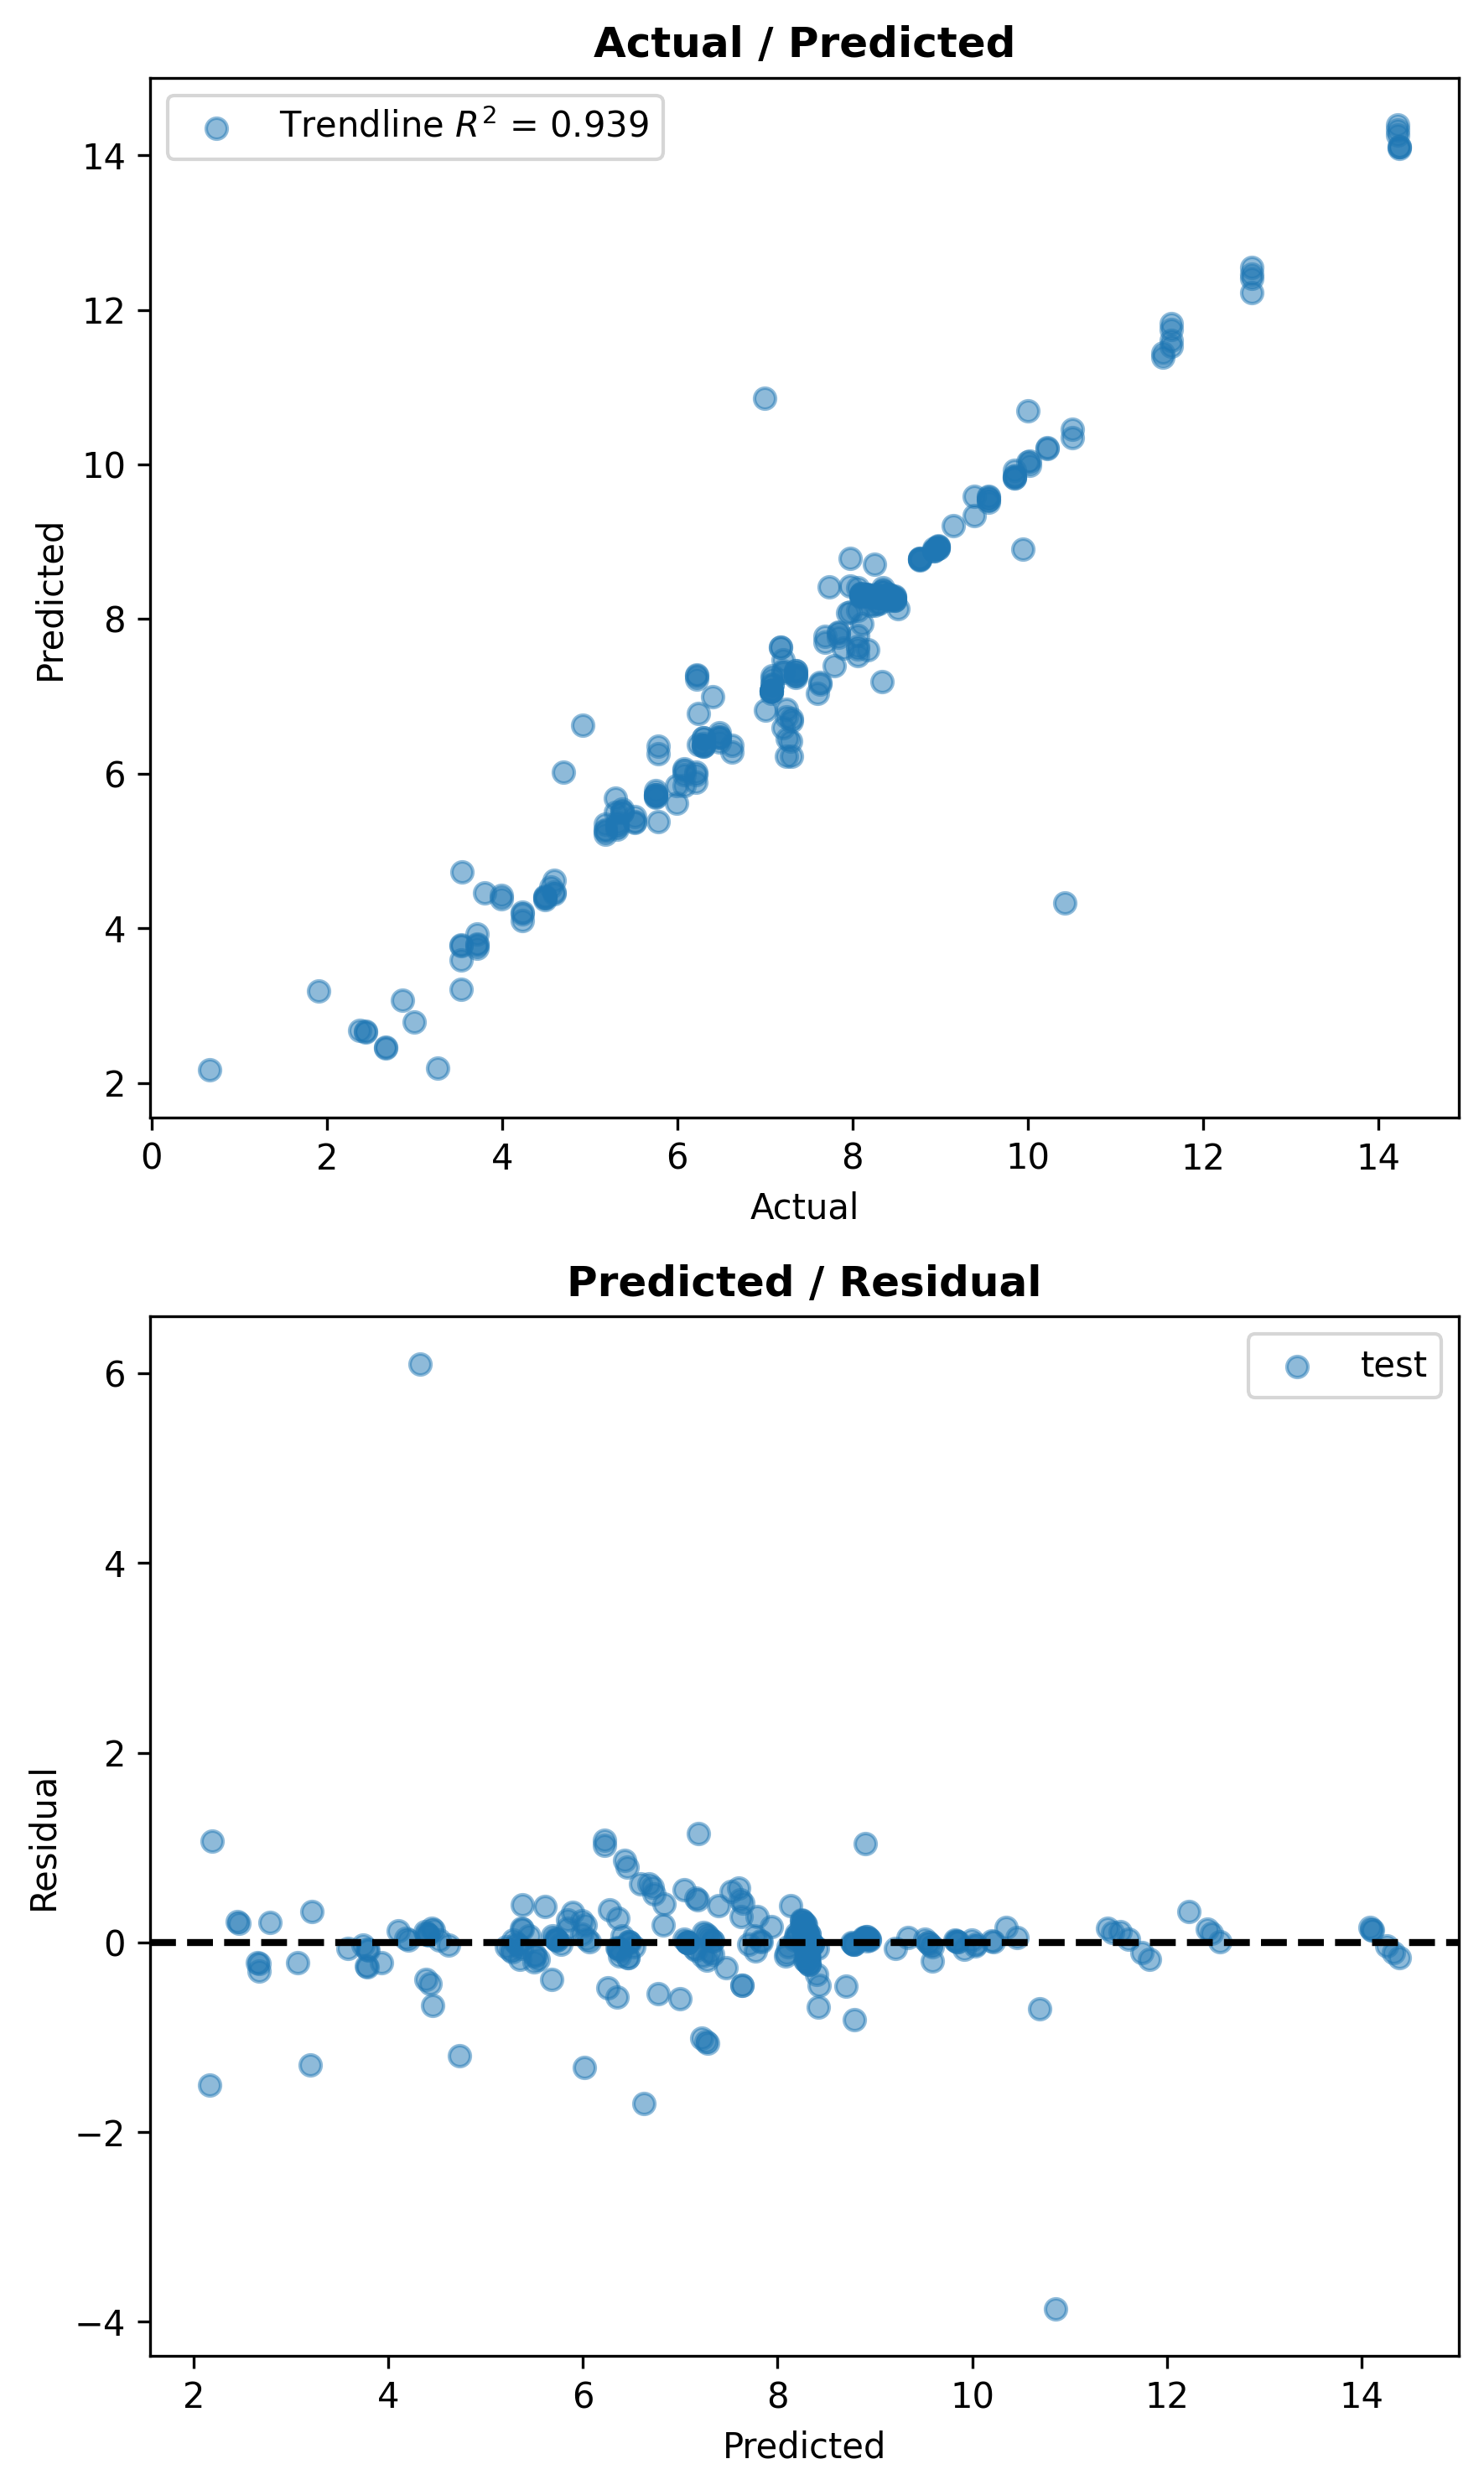

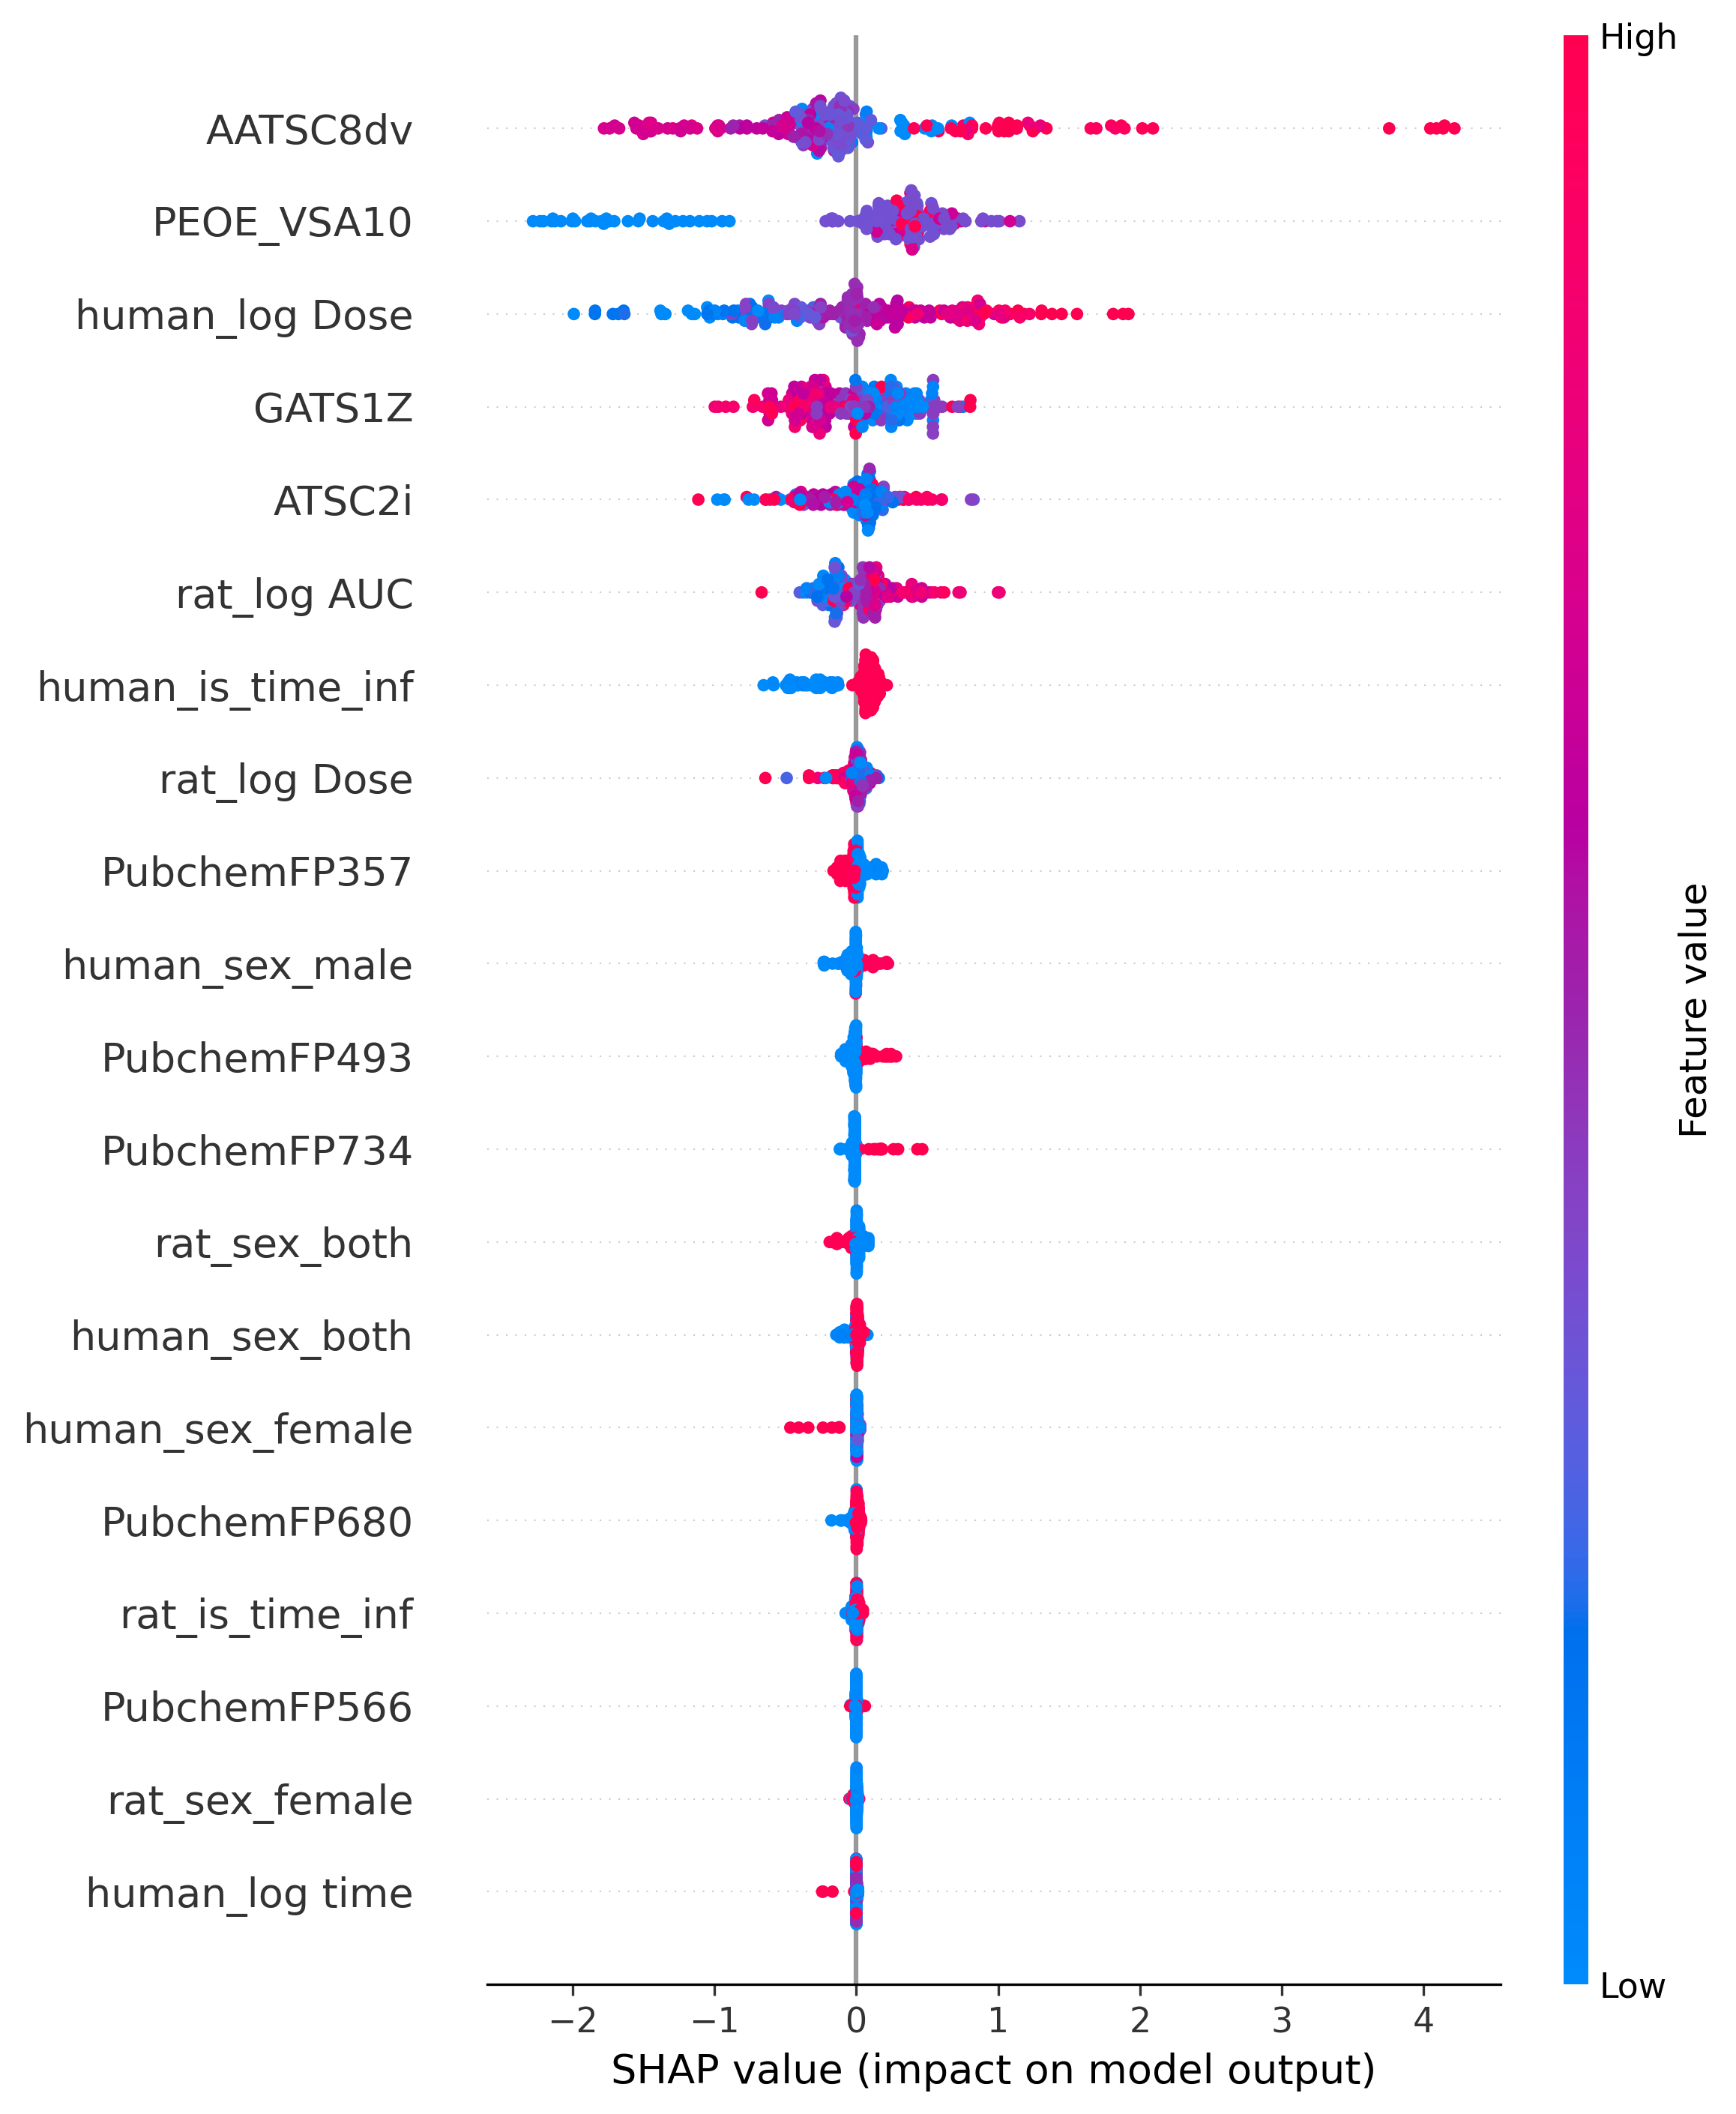

In [104]:
print('AUC CV 10 fold')                              
model_name = "XGBoost"
y_true_all = np.array(results[model_name]['y_true_all'])
y_pred_all = np.array(results[model_name]['y_pred_all'])
print('\nFor', model_name)
plot_residual_for_kfold_cv(y_true_all, y_pred_all)

plt.figure(dpi=300)
final_shap_matrix = np.vstack(oof_shap_values)
final_X_scaled_df = pd.concat(oof_X_test_scaled, axis=0)
shap.summary_plot(final_shap_matrix, final_X_scaled_df)

# pprint(results_all_folds_seperated)


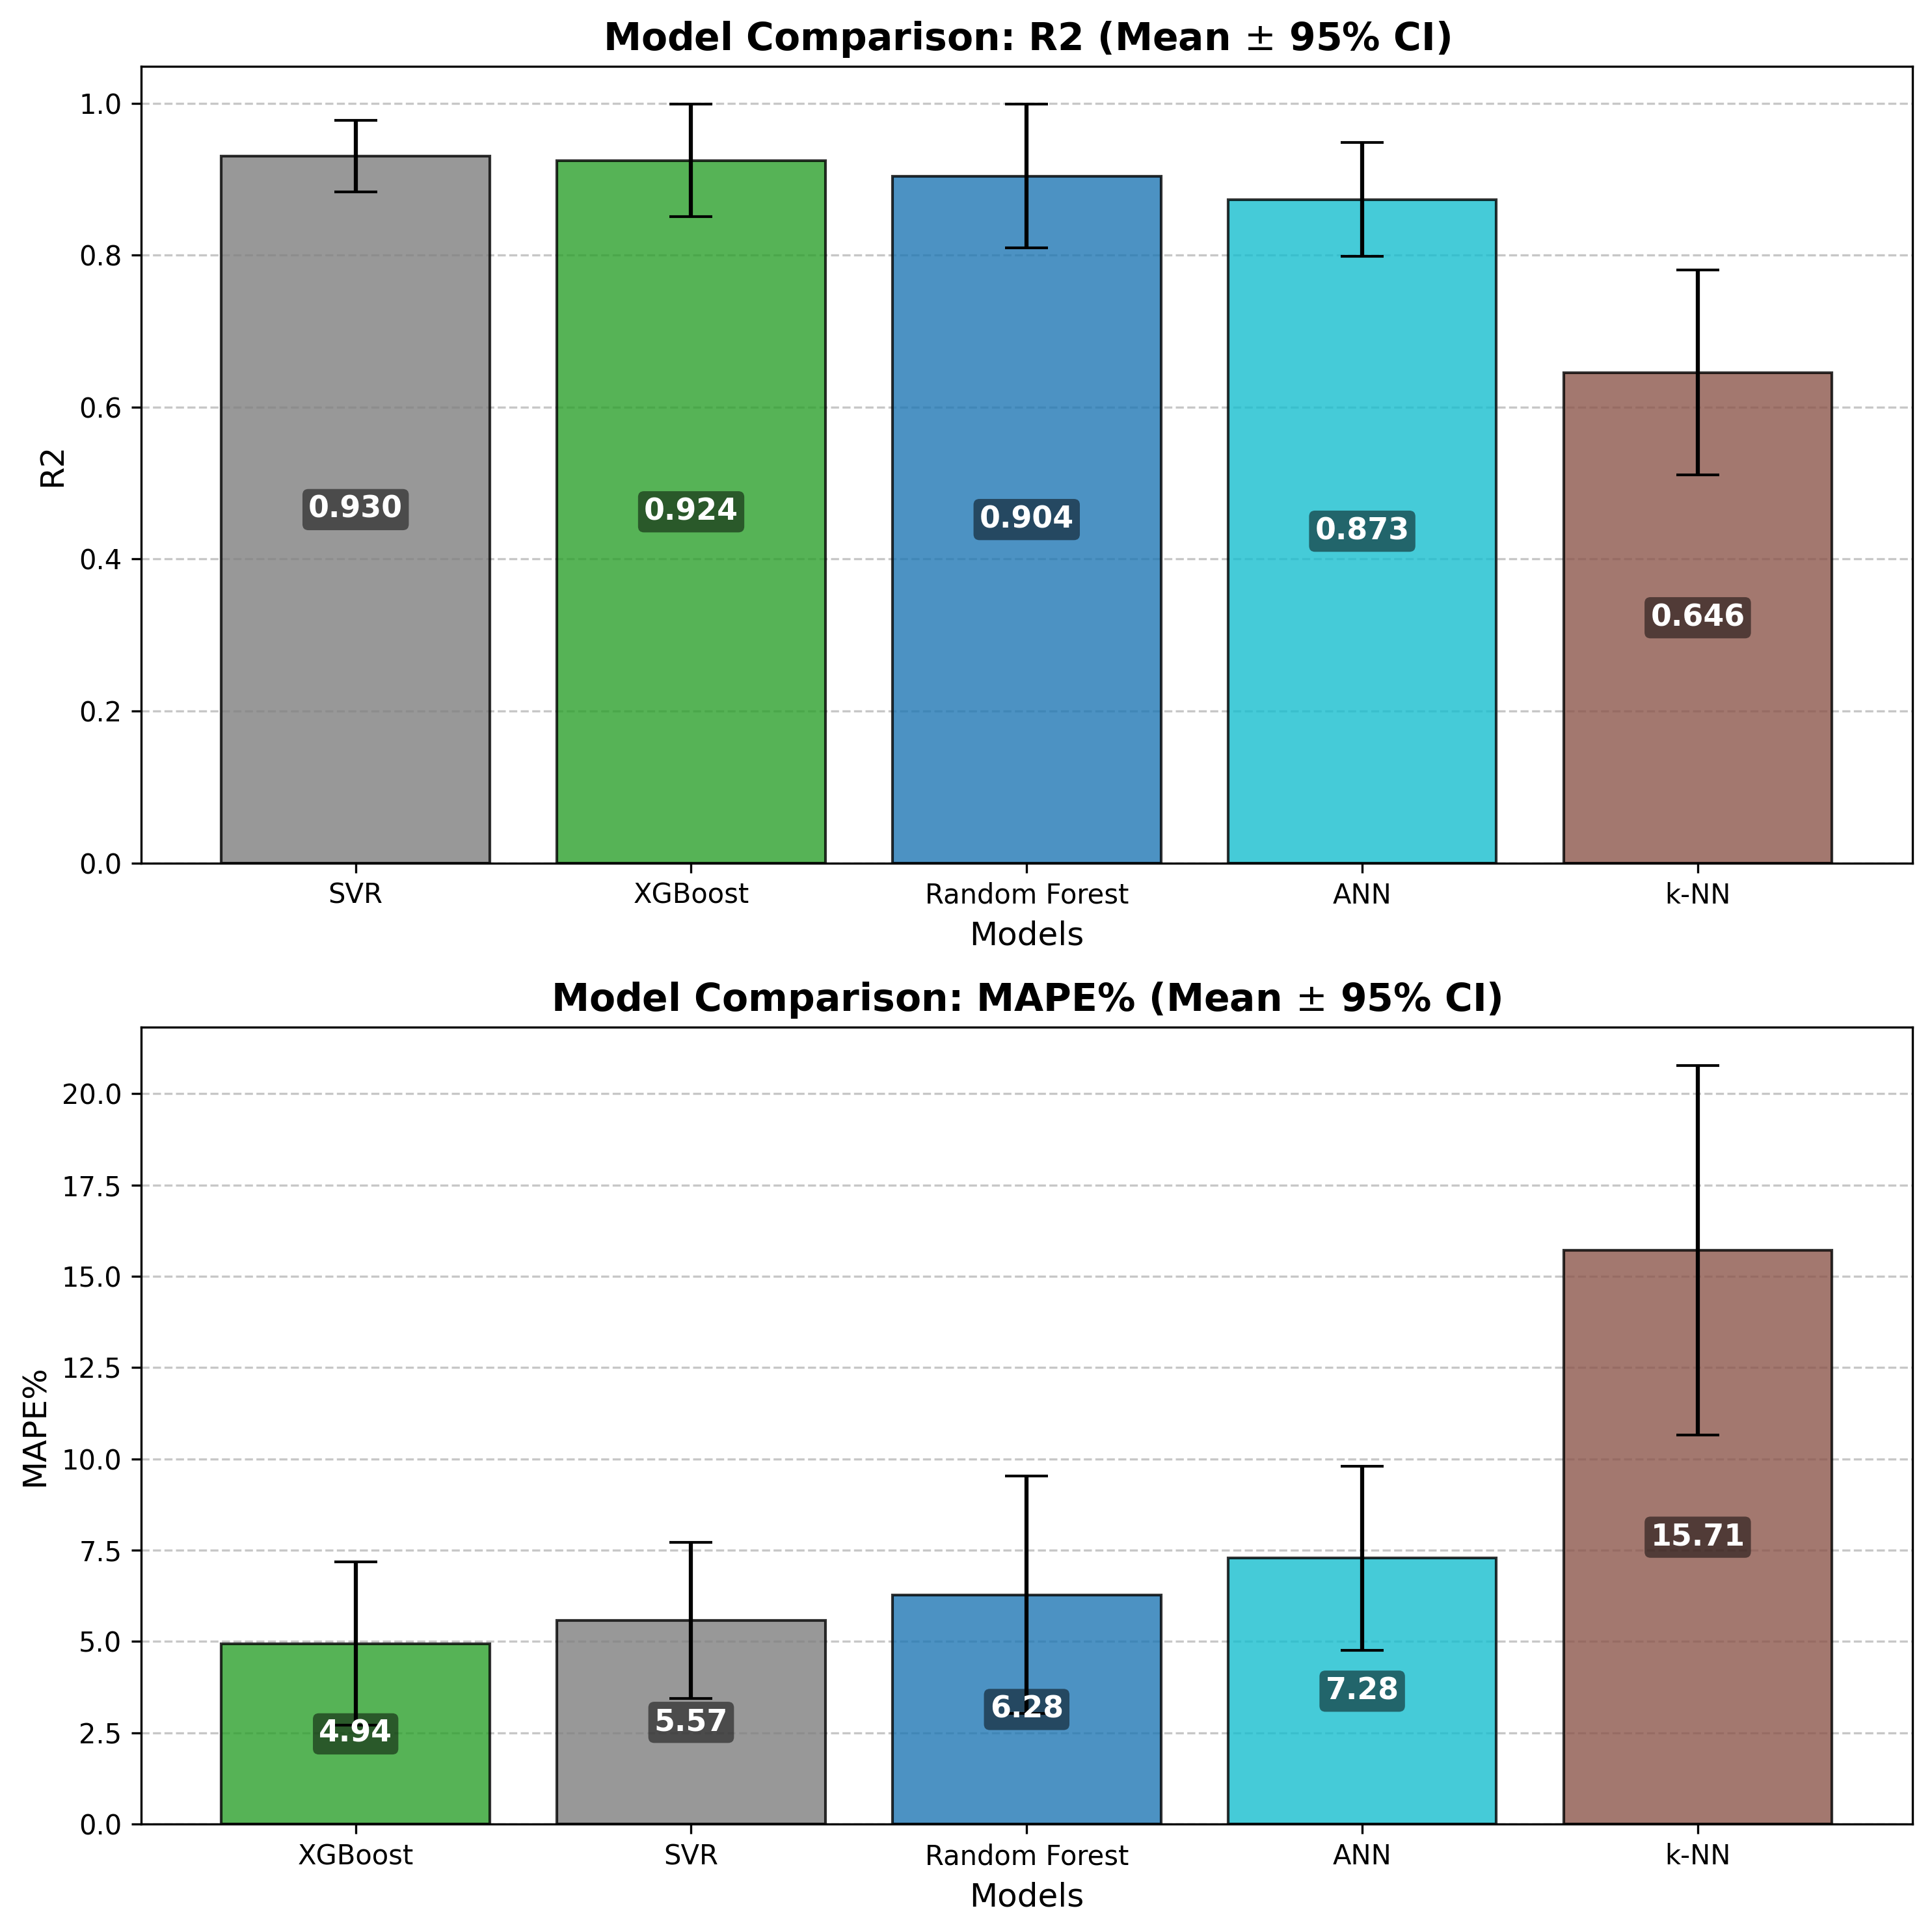

In [105]:
plot_cv_results_with_ci(results_all_folds_seperated, metrics_to_plot=['R2', 'MAPE%'])
# pprint(results_all_folds_seperated)

### Bootstrap comparison of models' R^2 (paired)


In [106]:
# ==============================================================================
# Paired (cluster) bootstrap comparison of model R2 on out-of-fold predictions
# ==============================================================================

def bootstrap_r2_distribution(results, model_names=None, groups=None,
                              n_boot=5000, seed=42):
    """
    Paired bootstrap of R2 for several models.
    - Uses the SAME resampled rows for every model in each iteration (paired),
      so differences between models are estimated fairly.
    - If `groups` is given (e.g. Parent_SMILES), whole drugs are resampled
      (cluster bootstrap) because rows of the same drug are not independent.
    Returns: observed R2 (pd.Series) and bootstrap R2 matrix (pd.DataFrame, n_boot x models)
    """
    if model_names is None:
        model_names = list(results.keys())

    y = np.asarray(results[model_names[0]]['y_true_all'], dtype=float)
    for m in model_names:  # all models must be evaluated on the same rows in the same order
        if not np.allclose(np.asarray(results[m]['y_true_all'], dtype=float), y):
            raise ValueError(f"y_true_all of '{m}' is not in the same order as '{model_names[0]}'")
    P = np.column_stack([np.asarray(results[m]['y_pred_all'], dtype=float) for m in model_names])
    n = len(y)

    rng = np.random.default_rng(seed)
    if groups is not None:
        groups = np.asarray(groups)
        _, inv = np.unique(groups, return_inverse=True)
        members = [np.where(inv == g)[0] for g in range(inv.max() + 1)]
        n_groups = len(members)

    def r2_vec(idx):
        yt = y[idx]
        ss_tot = np.sum((yt - yt.mean()) ** 2)
        ss_res = np.sum((P[idx] - yt[:, None]) ** 2, axis=0)
        return 1 - ss_res / ss_tot

    boot = np.empty((n_boot, len(model_names)))
    for b in range(n_boot):
        if groups is None:
            idx = rng.integers(0, n, n)
        else:
            picked = rng.integers(0, n_groups, n_groups)
            idx = np.concatenate([members[k] for k in picked])
        boot[b] = r2_vec(idx)

    observed = pd.Series(r2_vec(np.arange(n)), index=model_names, name='R2')
    return observed, pd.DataFrame(boot, columns=model_names)


def adjust_pvalues(p, method='holm'):
    """Holm (FWER), Bonferroni (FWER) or Benjamini-Hochberg 'fdr_bh' (FDR) adjustment."""
    p = np.asarray(p, dtype=float)
    m = len(p)
    if method == 'bonferroni':
        return np.minimum(p * m, 1)
    order = np.argsort(p)
    adj = np.empty(m)
    if method == 'holm':
        running = 0
        for k, i in enumerate(order):
            running = max(running, (m - k) * p[i])
            adj[i] = min(running, 1)
    elif method == 'fdr_bh':
        running = 1
        for k in range(m - 1, -1, -1):
            i = order[k]
            running = min(running, p[i] * m / (k + 1))
            adj[i] = min(running, 1)
    else:
        raise ValueError("method must be 'holm', 'bonferroni' or 'fdr_bh'")
    return adj


def compare_models_r2_bootstrap(results, model_names=None, groups=None, n_boot=5000,
                                comparisons='all', alpha=0.05, p_adjust='holm',
                                seed=42, title='', plot=True, savepath=None, dpi=300):
    """
    comparisons: 'all'     -> every pair of models
                 'vs_best' -> best model (highest observed R2) vs each of the others
    p_adjust   : 'holm' (recommended), 'bonferroni', 'fdr_bh', or None
    savepath   : if given, the figure is also written to this file at `dpi` (e.g. 'Figure4.png')
    """
    observed, boot = bootstrap_r2_distribution(results, model_names, groups, n_boot, seed)
    lo_q, hi_q = 100 * alpha / 2, 100 * (1 - alpha / 2)

    # --- 1) R2 of each model with bootstrap CI ---
    r2_table = pd.DataFrame({
        'R2': observed,
        f'CI {100*(1-alpha):.0f}% low': boot.quantile(lo_q / 100),
        f'CI {100*(1-alpha):.0f}% high': boot.quantile(hi_q / 100),
        'Bootstrap SE': boot.std(ddof=1),
    }).sort_values('R2', ascending=False)

    # --- 2) Pairwise differences in R2 ---
    names = list(observed.sort_values(ascending=False).index)
    if comparisons == 'vs_best':
        pairs = [(names[0], m) for m in names[1:]]
    else:
        pairs = list(itertools.combinations(names, 2))  # higher-R2 model is always first

    rows = []
    for a, b in pairs:
        d = boot[a].values - boot[b].values
        # two-sided bootstrap p-value: how often the difference crosses zero
        p = (2 * min(np.sum(d <= 0), np.sum(d >= 0)) + 1) / (n_boot + 1)
        rows.append({'Model A': a, 'Model B': b,
                     'ΔR2 (A-B)': observed[a] - observed[b],
                     'CI low': np.percentile(d, lo_q), 'CI high': np.percentile(d, hi_q),
                     'p (raw)': min(p, 1.0)})
    diff_table = pd.DataFrame(rows)
    if p_adjust is not None and len(diff_table) > 1:
        diff_table[f'p ({p_adjust})'] = adjust_pvalues(diff_table['p (raw)'], p_adjust)
        p_col = f'p ({p_adjust})'
    else:
        p_col = 'p (raw)'
    diff_table['Significant'] = diff_table[p_col] < alpha

    print(f"=== {title} R2 with bootstrap CI  "
          f"({'cluster bootstrap by drug' if groups is not None else 'row bootstrap'}, n_boot={n_boot}) ===")
    display(r2_table.style.format('{:.3f}'))
    print(f"\n=== {title} Pairwise ΔR2 (paired bootstrap, p adjusted by: {p_adjust}) ===")
    display(diff_table.style.format({'ΔR2 (A-B)': '{:.3f}', 'CI low': '{:.3f}', 'CI high': '{:.3f}',
                                     'p (raw)': '{:.4f}', p_col: '{:.4f}'}))

    # ------------------------------------------------------------------
    # Publication-size figure: panel (a) R2 on top, panel (b) delta-R2 below.
    # Only the drawing differs from the previous version; every number above
    # and every object returned is computed exactly as before.
    # ------------------------------------------------------------------
    if plot:
        n_m, n_p = len(r2_table), len(diff_table)
        fig_h = max(6.0, 0.48 * n_m + 0.40 * n_p + 2.4)
        fig, axes = plt.subplots(2, 1, figsize=(7.1, fig_h), dpi=dpi,
                                 gridspec_kw={'height_ratios': [n_m, 0.85 * n_p]})

        # ---- (a) R2 with confidence interval ----
        ax = axes[0]
        t_ = r2_table.iloc[::-1]
        y = np.arange(n_m)
        val = t_['R2'].values
        lo = t_.iloc[:, 1].values
        hi = t_.iloc[:, 2].values
        ax.errorbar(val, y, xerr=[val - lo, hi - val], fmt='o', ms=6,
                    color='black', ecolor='#1f6fb4', elinewidth=2, capsize=5)
        for yy, v in zip(y, val):
            ax.annotate(f'{v:.3f}', (v, yy), textcoords='offset points',
                        xytext=(0, 9), ha='center', fontsize=9.5)
        ax.set_yticks(y)
        ax.set_yticklabels(t_.index, fontsize=10)
        ax.set_ylim(-0.7, n_m - 0.3)
        ax.set_xlabel('$R^2$ (out-of-fold)', fontsize=11)
        ax.tick_params(axis='x', labelsize=10)
        ax.set_title(f'(a) {title}: $R^2$ with {100*(1-alpha):.0f}% bootstrap CI',
                     fontsize=12, fontweight='bold')
        ax.grid(axis='x', ls='--', alpha=0.6)
        ax.set_axisbelow(True)

        # ---- (b) pairwise differences ----
        ax = axes[1]
        t_ = diff_table.iloc[::-1]
        y = np.arange(n_p)
        for yy, (_, r) in zip(y, t_.iterrows()):
            c = '#c0392b' if r['Significant'] else '#7f8c8d'
            ax.plot([r['CI low'], r['CI high']], [yy, yy], color=c, lw=2.4, solid_capstyle='butt')
            ax.plot([r['CI low']] * 2, [yy - 0.16, yy + 0.16], color=c, lw=2.0)
            ax.plot([r['CI high']] * 2, [yy - 0.16, yy + 0.16], color=c, lw=2.0)
            ax.plot(r['ΔR2 (A-B)'], yy, 'o', color=c, ms=6)
        ax.axvline(0, color='black', ls='--', lw=1.2)
        ax.set_yticks(y)
        ax.set_yticklabels([f"{a} − {b}" for a, b in zip(t_['Model A'], t_['Model B'])], fontsize=10)
        ax.set_ylim(-0.7, n_p - 0.3)
        ax.set_xlabel('$\\Delta R^2$', fontsize=11)
        ax.tick_params(axis='x', labelsize=10)
        adj_name = {'holm': 'Holm', 'bonferroni': 'Bonferroni',
                    'fdr_bh': 'BH-FDR'}.get(p_adjust, str(p_adjust))
        ax.set_title(f'(b) {title}: pairwise $\\Delta R^2$ (red: significant after {adj_name})',
                     fontsize=11.5, fontweight='bold')
        ax.grid(axis='x', ls='--', alpha=0.6)
        ax.set_axisbelow(True)

        # room on the right for the p-value labels
        x_hi = t_['CI high'].max()
        x_lo = min(-0.06, t_['CI low'].min() - 0.03)
        ax.set_xlim(x_lo, x_hi + 0.22 * (x_hi - x_lo))
        for yy, (_, r) in zip(y, t_.iterrows()):
            p_txt = 'p < 0.001' if r[p_col] < 0.001 else f'p = {r[p_col]:.3f}'
            ax.annotate(p_txt, (ax.get_xlim()[1], yy), xytext=(-4, 0),
                        textcoords='offset points', ha='right', va='center',
                        fontsize=9, color='#333333')

        fig.tight_layout(h_pad=2.0)
        if savepath:
            fig.savefig(savepath, dpi=dpi, bbox_inches='tight', facecolor='white')
            print(f'figure saved to {savepath}')
        plt.show()

    return r2_table, diff_table, boot

=== AUC R2 with bootstrap CI  (cluster bootstrap by drug, n_boot=5000) ===


,R2,CI 95% low,CI 95% high,Bootstrap SE
SVR,0.939,0.847,0.974,0.033
XGBoost,0.939,0.822,0.983,0.042
Random Forest,0.928,0.816,0.971,0.041
ANN,0.895,0.742,0.958,0.056
k-NN,0.676,0.333,0.819,0.130



=== AUC Pairwise ΔR2 (paired bootstrap, p adjusted by: holm) ===


,Model A,Model B,ΔR2 (A-B),CI low,CI high,p (raw),p (holm),Significant
0,SVR,XGBoost,0.001,-0.024,0.035,0.9868,1.0000,False
1,SVR,Random Forest,0.011,-0.027,0.075,0.6389,1.0000,False
2,SVR,ANN,0.044,0.004,0.135,0.0178,0.1068,False
3,SVR,k-NN,0.263,0.141,0.544,0.0002,0.0020,True
4,XGBoost,Random Forest,0.011,-0.036,0.060,0.5629,1.0000,False
5,XGBoost,ANN,0.044,-0.013,0.144,0.1474,0.7369,False
6,XGBoost,k-NN,0.262,0.146,0.536,0.0002,0.0020,True
7,Random Forest,ANN,0.033,-0.040,0.133,0.3441,1.0000,False
8,Random Forest,k-NN,0.252,0.120,0.533,0.0002,0.0020,True
9,ANN,k-NN,0.219,0.087,0.483,0.0006,0.0042,True


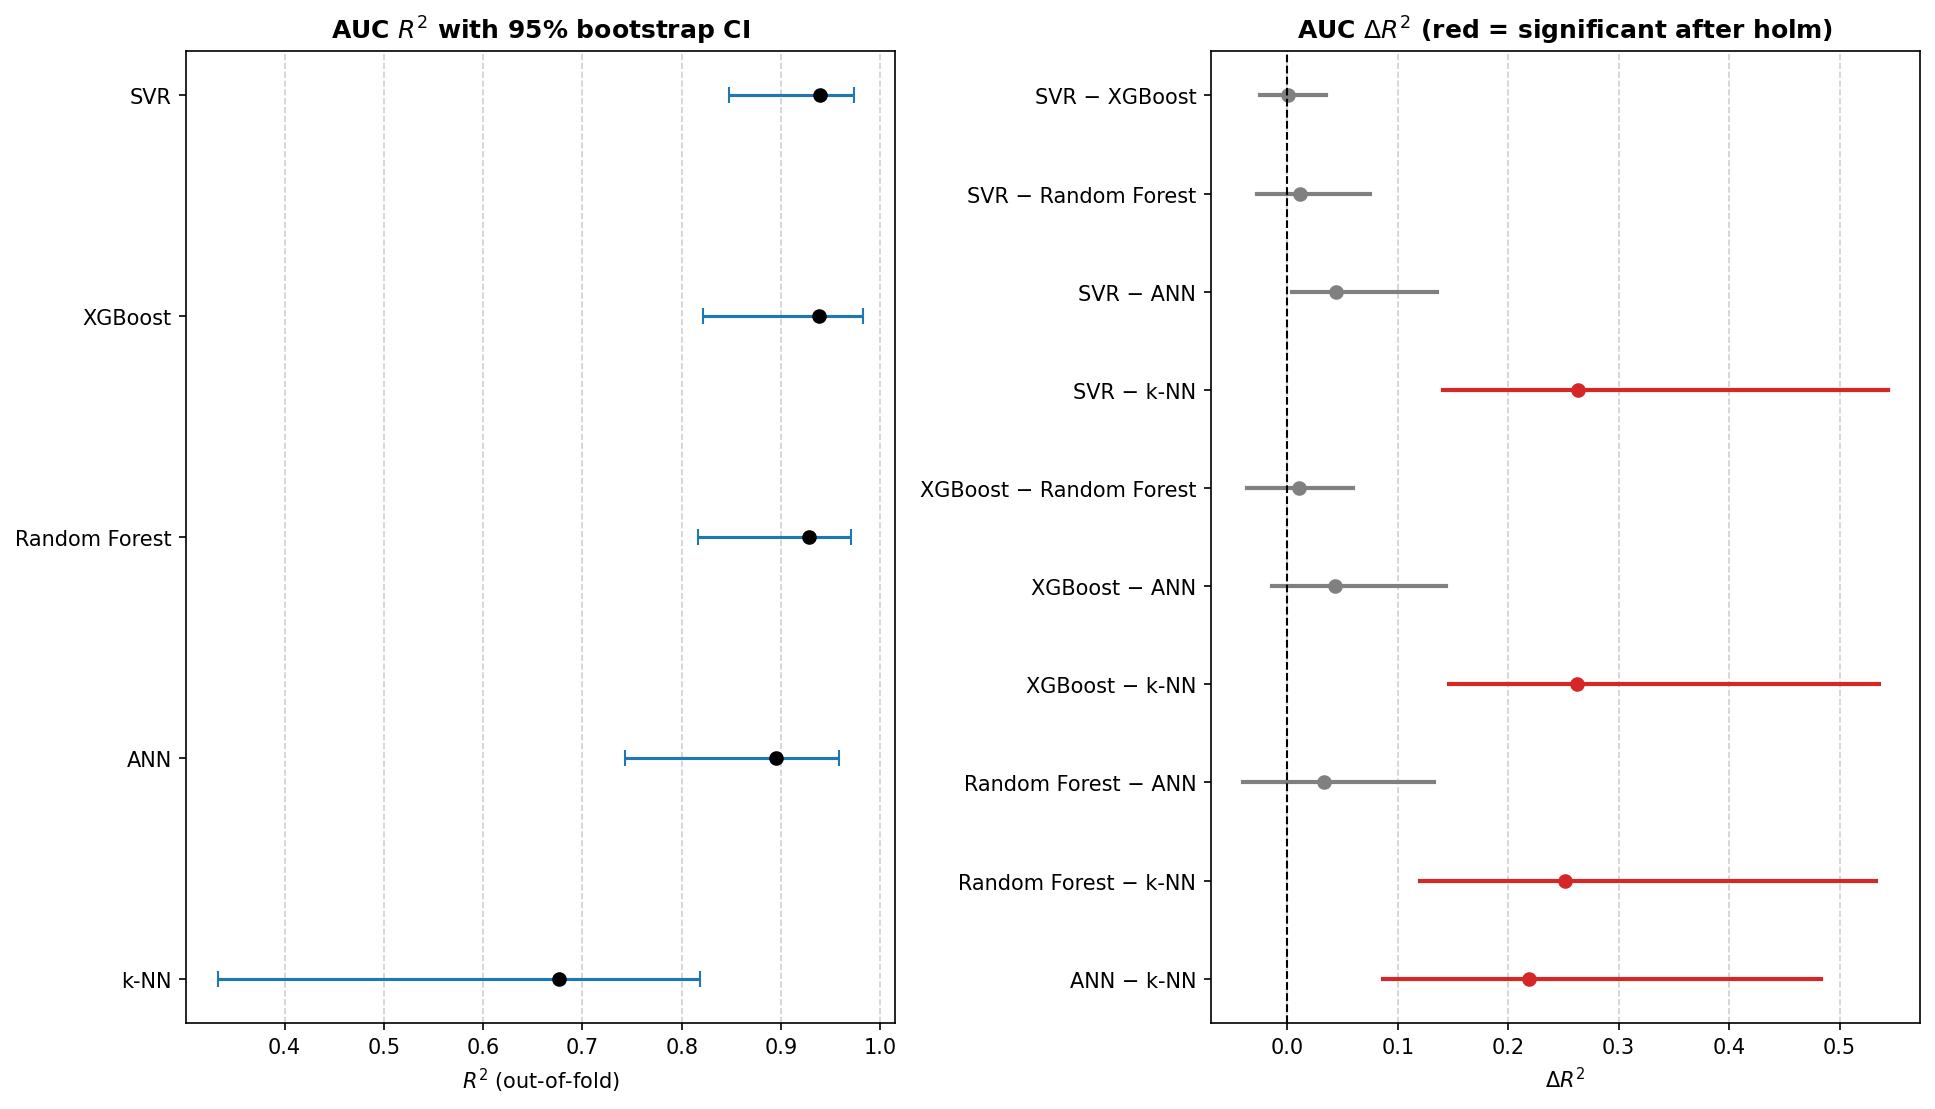

In [107]:
# AUC: paired cluster-bootstrap comparison of R2 between models

# Row order of y_true_all / y_pred_all = order of the test folds of kf
oof_order = np.concatenate([test_idx for _, test_idx in kf.split(X)])
# Resample whole drugs, because rows (doses) of the same drug are not independent
drug_groups = df['Parent_SMILES'].values[oof_order]

r2_table_auc, diff_table_auc, boot_auc = compare_models_r2_bootstrap(
    results,
    groups=drug_groups,      # set to None for an ordinary row-wise bootstrap
    n_boot=5000,
    comparisons='all',       # 'all' = every pair of models, 'vs_best' = best model vs each other model
    p_adjust='holm',         # 'holm' (recommended), 'bonferroni', 'fdr_bh' or None
    alpha=0.05,
    title='AUC',
)

# with pd.ExcelWriter('AUC_bootstrap_R2_comparison.xlsx') as writer:
#     r2_table_auc.to_excel(writer, sheet_name='R2 with CI')
#     diff_table_auc.to_excel(writer, sheet_name='Pairwise dR2', index=False)


In [108]:
# All Points not each fol
pd.DataFrame(np.abs(y_true_all - y_pred_all)/y_true_all*100, columns = ['Relative Error%']).to_excel('AUC_for_each_point_RE%.xlsx')

In [109]:
# AUC Predicting for compound 4a: After training on ALL dataset
best_xgb_params = {'n_estimators': 580, 'max_depth': 3, 'learning_rate': 0.08114906263133624, 'subsample': 0.9968299596973474, 'colsample_bytree': 0.7685347805300924}

X = df[cols[1:-1]] # Without DrugName and Target Column
y = df[cols[-1]]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)
X_train, y_train = X, y
X_for_my_drug_4a = MY_DF[cols[1:-1]]

print("shape of X_train, y_train")
print(X_train.shape, y_train.shape)
models = {
    # "Linear Regression": LinearRegression(),
    # "Linear (Ridge)": Ridge(alpha=1.0),
    # "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(**best_xgb_params),
    # "k-NN (Similarity)": KNeighborsRegressor(n_neighbors=5),
    # "SVR (Support Vector)": SVR(kernel='rbf', C=10, epsilon=0.1),
    # "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(20, 5), max_iter=2000, random_state=42),
    # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), 

}

# 4. Loop through each model and evaluate using LOGOCV
for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    
    # Create a pipeline that standardizes the data THEN fits the model
    # This ensures no data leakage during cross-validation
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])
    
    
    y_true_all = []
    y_pred_all = []
    
    pipeline.fit(X_train, y_train)

    y_pred_for_my_drug_4a = pipeline.predict(X_for_my_drug_4a)
        


# 5. Display the final results as a DataFrame
print("\n--- AUC Predicted results for compound 4a ---")
pd.DataFrame((DOSES, y_pred_for_my_drug_4a, np.exp(y_pred_for_my_drug_4a)-1)).T.style.format("{:.2f}") #because of log1p

shape of X_train, y_train
(247, 24) (247,)
Evaluating XGBoost...

--- AUC Predicted results for compound 4a ---


,0,1,2
0,28.20,7.81,2467.08
1,56.40,8.18,3555.09
2,112.80,8.05,3138.90
3,169.20,8.05,3119.24
4,225.60,8.19,3613.76


# Cmax Predicting

In [112]:
# other_features  = [      
#      'MW',
#      'SLogP',
#      'TopoPSA',
#      'nHBDon',
#      'nHBAcc',
#      'nRot',
#      'nRing',
#      'nHeavyAtom',
#      'QED',
#      'BertzCT',
#      'LabuteASA',
#      'FCSP3',
#      'SMR',
#     ]

# other_features_names = list(other_features_filtered.columns)

n = 25
importance_df = pd.read_excel('Cmax_all_features_importances_xgboost_human_as_label.xlsx', index_col=0)
other_features_names = importance_df.iloc[:n, 0].values.tolist()


### Feature Selection with: Plus-L Minus-R method for feature selection

In [113]:
# n = 30

# PLUS-L MINUS-R (SFFS) FEATURE SELECTION

# all_candidate_features = list(other_features_filtered.columns)[1:] # because first is SMILES strings

# X_selection = final_df[all_candidate_features]
# y_selection = final_df['human_log C max']

# # Drop NaNs for the selection phase
# selection_df = pd.concat([X_selection, y_selection], axis=1).dropna()
# X_selection_clean = selection_df[all_candidate_features]
# y_selection_clean = selection_df['human_log C max']

# # 2. Define the base estimator for evaluating the features
# # Using a fast configuration here saves time during the intense selection loops.
# fs_model = xgb.XGBRegressor(n_estimators=100, max_depth=3, random_state=42, n_jobs=-1)

# # 3. Initialize the Plus-L Minus-R Selector (Sequential Floating Forward Selection)
# sffs = SFS(
#     estimator=fs_model, 
#     k_features=(10, n),      # The algorithm will find the optimal number of features between 10 and 25
#     forward=True,             # True = Forward Selection
#     floating=True,            # True = PLUS-L MINUS-R Logic (This is what the reviewer asked for!)
#     scoring='neg_mean_squared_error', # Evaluation metric
#     # scoring='neg_mean_absolute_percentage_error',
#     cv=5,                     # 5-fold cross-validation during selection to prevent overfitting
#     n_jobs=-1,                # Use all CPU cores
#     verbose=2
# )

# print("Starting Plus-L Minus-R Feature Selection. This may take a few minutes...")

# # 4. Fit the selector
# sffs = sffs.fit(X_selection_clean, y_selection_clean)

# # 5. Extract the best feature names chosen by the algorithm
# other_features_names = list(sffs.k_feature_names_)

# path = 'Cmax_all_Selected_Features_PlusL_MinusR.json'
# with open(path, 'w') as f:
#     json.dump(other_features_names, f)
        
# print(f"Algorithm finished! Optimal number of features selected: {len(other_features_names)}")
# print(f"Selected Features: {other_features_names}")


In [114]:
path = 'Cmax_all_Selected_Features_PlusL_MinusR.json'
with open(path) as f:
    other_features_names = json.load(f)

# other_features_names = ['human_food_fast', 'ATSC2v', 'NssS', 'PubchemFP13', 'PubchemFP155', 'PubchemFP336', 'PubchemFP505', 'PubchemFP518', 'PubchemFP614', 'PubchemFP693', 'PubchemFP714', 'PubchemFP770']

other_features_names

['human_food_fast',
 'ATSC2v',
 'NssS',
 'PubchemFP13',
 'PubchemFP155',
 'PubchemFP336',
 'PubchemFP505',
 'PubchemFP518',
 'PubchemFP614',
 'PubchemFP693',
 'PubchemFP714',
 'PubchemFP770']

In [115]:
cols1 =  [
    'Parent_SMILES',
#     'Dose (mg/kg)',
    'rat_log Dose','human_log Dose',

    'rat_sex_both', 'rat_sex_female','rat_sex_male',
    'human_sex_both', 'human_sex_female','human_sex_male',
#     'type_rad', 'type_simple',
]
cols2 = [
    # 'rat_log time', 'human_log time',
#     'time','time',
    
    # 'rat_is_time_inf','human_is_time_inf',
    # 'rat_log AUC','human_log AUC',
    
    'rat_log C max','human_log C max',
#     'rat_log T max (hr)','human_log T max (hr)',

]


cols = cols1 + other_features_names + cols2
cols

df = final_df[cols]
df = df.dropna(subset=['rat_log C max', 'human_log C max'])
df = df[df['human_log C max']!=0] 

# Keep only the first occurrence of each column name
df = df.loc[:, ~df.columns.duplicated()]
cols = list(df.columns)
df.shape

(270, 23)

In [116]:
column_df = pd.DataFrame([cols]).T
column_df.columns = ['Features Cmax']
print('Cmax')
column_df.drop(0, axis=0)

Cmax


,Features Cmax
1,rat_log Dose
2,human_log Dose
3,rat_sex_both
4,rat_sex_female
5,rat_sex_male
6,human_sex_both
7,human_sex_female
8,human_sex_male
9,human_food_fast
10,ATSC2v


### Outlier Removal  (uncomment it if we want to peform)

In [117]:
rdf = df.copy()

In [118]:
# # 1. Identify strictly continuous columns (exclude one-hot/binary/categorical)
# # We assume a continuous variable should have more than 10 unique values.
# UNIQUE_THRESHOLD = 5 # 10 default

# all_numeric_cols = rdf.select_dtypes(include=[np.number]).columns
# continuous_cols = [col for col in all_numeric_cols if rdf[col].nunique() > UNIQUE_THRESHOLD]

# print(f"Total numeric columns: {len(all_numeric_cols)}")
# print(f"Continuous columns selected for outlier removal: {len(continuous_cols)}")

# # 2. Calculate IQR and bounds ONLY for continuous columns
# Q1 = rdf[continuous_cols].quantile(0.25)
# Q3 = rdf[continuous_cols].quantile(0.75)
# IQR = Q3 - Q1  

# # Using a multiplier of 3 for extreme outliers (adjust to 1.5 for standard outliers)
# lower_bound = Q1 - 3 * IQR
# upper_bound = Q3 + 3 * IQR

# # 3. Create the boolean mask for continuous columns
# # True means the value is an inlier (within bounds)
# mask = ~((rdf[continuous_cols] < lower_bound) | (rdf[continuous_cols] > upper_bound))

# # # 4. Filter the DataFrame
# # df = rdf[mask.all(axis=1)]

# # # 5. Report the results
# # rows_removed = len(rdf) - len(df)
# # percent_removed = rows_removed / len(rdf)
# # print(f"Removed {rows_removed} rows ({percent_removed:.1%} of data)")

# # This limits the values in the column to be no lower than lower_bound and no higher than upper_bound
# df_cleaned = rdf.copy()
# for col in continuous_cols:
#     df_cleaned[col] = rdf[col].clip(lower=lower_bound[col], upper=upper_bound[col])


# df = df_cleaned

# mask.sum()

In [119]:
# Cmax train test split method (All columns StandardScaler)

# drugs = rdf.Compound.unique()
# drugs_train, drugs_test = train_test_split(drugs, test_size=0.1, random_state=42)
# df.index = df.Compound
# df_train = df.loc[drugs_train]
# df_test = df.loc[drugs_test]

# X_train = df_train[cols[1:-1]] # Without DrugName and Target Column
# X_test = df_test[cols[1:-1]]

# y_train = df_train[cols[-1]]
# y_test = df_test[cols[-1]]

X = df[cols[1:-1]] # Without DrugName and Target Column
y = df[cols[-1]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

print("shape of X_train, X_test")
print(X_train.shape, X_test.shape)
models = {
    "Linear Regression": LinearRegression(),
    "Linear (Ridge)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42),
    "k-NN (Similarity)": KNeighborsRegressor(n_neighbors=5),
    "SVR (Support Vector)": SVR(kernel='rbf', C=10, epsilon=0.1),
    "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(200), max_iter=2000, random_state=42),
    "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), 

}

# Dictionary to store the overall performance of each model
results = {}

# 4. Loop through each model and evaluate using LOGOCV
for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    
    # Create a pipeline that standardizes the data THEN fits the model
    # This ensures no data leakage during cross-validation
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])
    
    
    y_true_all = []
    y_pred_all = []
    
    # Train the pipeline (scales X_train, then fits model)
    pipeline.fit(X_train, y_train)

    # Predict the left-out group (scales X_test using X_train's parameters, then predicts)
    y_pred = pipeline.predict(X_test)
        
    # Store true and predicted values
    y_true_all.extend(y_test.values)
    y_pred_all.extend(y_pred)
        
    # Calculate overall metrics for the model
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    mae = mean_absolute_error(y_true_all, y_pred_all)
    mape = mean_absolute_percentage_error(y_true_all, y_pred_all)*100
    
    r2 = r2_score(y_true_all, y_pred_all)
    
    # Save results
    results[model_name] = {'RMSE': rmse, 'MAPE%':mape, 'MAE': mae, 'R2': r2}

# 5. Display the final results as a DataFrame
results_df = pd.DataFrame(results).T
print("\n--- Final Model Performance Cmax ---")
print(results_df.sort_values(by='RMSE', ascending=True))


shape of X_train, X_test
(243, 21) (27, 21)
Evaluating Linear Regression...
Evaluating Linear (Ridge)...
Evaluating Random Forest...
Evaluating XGBoost...
Evaluating k-NN (Similarity)...
Evaluating SVR (Support Vector)...
Evaluating ANN (MLP)...
Evaluating ElasticNet...

--- Final Model Performance Cmax ---
                          RMSE      MAPE%       MAE        R2
XGBoost               0.485535  13.791326  0.321616  0.981136
ANN (MLP)             0.729712  16.372114  0.454137  0.957392
Random Forest         0.743034  21.470126  0.515577  0.955822
SVR (Support Vector)  1.095030  23.403019  0.663105  0.904052
k-NN (Similarity)     1.161759  46.867888  0.844756  0.892002
Linear (Ridge)        1.791498  33.133976  1.178759  0.743187
Linear Regression     1.791528  33.765497  1.182348  0.743179
ElasticNet            1.835261  26.785313  1.192595  0.730487


In [120]:
# unccomment this code if we want to see which features are better in all features

# xgboost = models["XGBoost"]
# col_names = cols[1:-1]

# importance_df = pd.DataFrame({
#     'Feature': col_names,
#     'Importance': xgboost.feature_importances_
# })

# importance_df.sort_values(by='Importance', ascending=False, inplace=True)
# importance_df.to_excel('Cmax_all_features_importances_xgboost_human_as_label.xlsx')
# importance_df.head(100)

In [121]:
# # Plotting Residual Plot and Actual/Predicted plot
# model = models['XGBoost']

# pipeline = Pipeline([
#     ('scaler', StandardScaler()),
#     ('regressor', model)
# ])

# # 3. Fit the pipeline on the training data
# pipeline.fit(X_train, y_train)

# # 4. Make predictions using the PIPELINE, not the base model
# y_pred_train = pipeline.predict(X_train)
# y_pred = pipeline.predict(X_test)

# y_pred_real = y_pred
# y_test_real = y_test


# mape = 100*mean_absolute_percentage_error(y_test_real, y_pred_real)
# r2 = r2_score(y_test_real, y_pred_real)   
# mse = mean_squared_error(y_test, y_pred)
# rmse = mse**(1/2)

# var = y_test.std()**2
# print(f'{r2=:.3f}, {mape=:.3f} {mse=:.4f} {rmse=:.3f} {var=:3f}')

# acc_10 = tolerance_accuracy(y_test, y_pred, tolerance=0.10)
# acc_15 = tolerance_accuracy(y_test, y_pred, tolerance=0.15)
# acc_20 = tolerance_accuracy(y_test, y_pred, tolerance=0.20)

# print(f"Accuracy (10% tolerance): {acc_10:.2%}")
# print(f"Accuracy (15% tolerance): {acc_15:.2%}")
# print(f"Accuracy (20% tolerance): {acc_20:.2%}")


# # linregress calculates the exact same regression line that regplot draws
# # res = linregress(y_test_real.ravel(), y_pred_real.ravel())
# # r_squared_of_line = res.rvalue ** 2
# # print(f'{r_squared_of_line=}')

# # # calculating accuracy (error less than 10, 15 , 20 %)
# # # Plot and pass the R^2 value to the line label to show in the legend
# # sns.regplot(x=y_test_real, y=y_pred_real, color='black', line_kws={'label': f'Trendline $R^2$ = {r_squared_of_line:.3f}'})
# # plt.legend()
# # plt.show()

# # # all train, and test
# # plt.figure()
# # plt.title('Actual/Predicted')
# # plt.scatter(y_train, y_pred_train, color='tab:blue', alpha=0.5, label='train')
# # plt.scatter(y_test, y_pred, color='black', alpha=0.5, label='test')
# # plt.xlabel('Actual')
# # plt.ylabel('Predicted')
# # plt.legend()
# # plt.show()


# # res_train = y_train - y_pred_train
# # res_test = y_test - y_pred
# # plt.figure()
# # plt.title('Predicted/Residual')
# # plt.scatter(y_pred_train, res_train, color='tab:blue', alpha=0.5, label='train')
# # plt.scatter(y_pred, res_test, color='black', alpha=0.5, label='test')
# # plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# # plt.xlabel('Predicted')
# # plt.ylabel('Residual')
# # plt.legend()
# # plt.show()

# # plt.figure()
# # plt.title('Actual/Residual')
# # plt.scatter(y_train, res_train, color='tab:blue', alpha=0.5, label='train')
# # plt.scatter(y_test, res_test, color='black', alpha=0.5, label='test')
# # plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# # plt.xlabel('Actual')
# # plt.ylabel('Residual')
# # plt.legend()
# # plt.show()

In [122]:
# # Cmax Hyperparameter Optimization for the best model (least MAPE%): XGboost

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]

# print("Shape of X, y:")
# print(X.shape, y.shape)

# # ==============================================================================
# # PHASE 1: Optuna Bayesian Optimization for XGBoost
# # ==============================================================================
# def objective(trial):
#     # Define hyperparameter search space for XGBoost
#     param = {
#         'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
#         'max_depth': trial.suggest_int('max_depth', 3, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
#         'random_state': 42,
#         'n_jobs': -1 # Utilize all CPU cores for speed
#     }
    
#     cv = KFold(n_splits=10, shuffle=True, random_state=42)
#     fold_mapes = []
    
#     for train_index, test_index in cv.split(X):
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        
#         # We must scale data inside the CV loop during Optuna tuning as well
#         pipeline = Pipeline([
#             ('scaler', StandardScaler()),
#             ('xgb', xgb.XGBRegressor(**param))
#         ])
        
#         pipeline.fit(X_train, y_train)
#         y_pred = pipeline.predict(X_test)
        
#         # Calculate MAPE% for this fold
#         mape = mean_absolute_percentage_error(y_test, y_pred) * 100
#         fold_mapes.append(mape)
        
#     # Return the mean MAPE% across all 10 folds to Optuna
#     return np.mean(fold_mapes)

# print("\n--- Starting Optuna Optimization for XGBoost ---")
# # Create a study object and optimize to MINIMIZE the MAPE%
# study = optuna.create_study(direction='minimize')
# study.optimize(objective, n_trials=50)

# print("\n--- Optuna Tuning Complete ---")
# print("Best XGBoost Parameters:", study.best_params)
# print(f"XGBoost Cmax Best Hyperparameters CV MAPE%: {study.best_value:.2f}%")


In [123]:
# # Cmax 10 fold crossvalidation method

# best_xgb_params = {'n_estimators': 471, 'max_depth': 9, 'learning_rate': 0.02351827240924052, 'subsample': 0.9967651683149855, 'colsample_bytree': 0.8701763637393823}

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]

# print("Shape of X, y:")
# print(X.shape, y.shape)

# models = {
#     # "Linear Regression": LinearRegression(),
#     # "Linear (Ridge)": Ridge(alpha=1.0),
#     "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
#     "XGBoost": xgb.XGBRegressor(**best_xgb_params),
#     "k-NN": KNeighborsRegressor(n_neighbors=5),
#     "SVR": SVR(kernel='rbf', C=10, epsilon=0.1),
#     "ANN": MLPRegressor(hidden_layer_sizes=(20,10), max_iter=2000, random_state=42),
#     # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
# }

# # 3. Initialize 10-Fold Cross-Validation
# kf = KFold(n_splits=10, shuffle=True, random_state=42)

# # Dictionary to store the overall performance of each model
# results = {}
# results_all_folds_seperated = {}

# # Initialize lists to hold the SHAP values and the scaled features (Out of the fold Shap)
# oof_shap_values = []
# oof_X_test_scaled = []

# # 4. Loop through each model and evaluate using 10-Fold CV
# for model_name, model in models.items():
#     print(f"Evaluating {model_name}...")
    
#     results_all_folds_seperated[model_name] = {
#         "RMSE":[],
#         "MAE":[],
#         "MAPE%":[],
#         "R2":[]
#     }
    
#     # Create a pipeline that standardizes the data THEN fits the model
#     # This ensures no data leakage during cross-validation
#     pipeline = Pipeline([
#         ('scaler', StandardScaler()),
#         ('regressor', model)
#     ])

#     y_true_all = []
#     y_pred_all = []
#     for fold_idx, (train_index, test_index) in enumerate(kf.split(X), 1):
#         # print(f'fold = {fold_idx}')
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]

#         # Train the pipeline (scales X_train, then fits model)
#         pipeline.fit(X_train, y_train)

#         # Predict the held-out fold (scales X_test using X_train's parameters, then predicts)
#         y_pred = pipeline.predict(X_test)
        
#         # Store true and predicted values
#         y_true_all.extend(y_test.values)
#         y_pred_all.extend(y_pred)

#         # Calculate each fold metrics for the model to calculate SD and CI
#         results_all_folds_seperated[model_name]["RMSE"].append(np.sqrt(mean_squared_error(y_test.values, y_pred)))
#         results_all_folds_seperated[model_name]["MAE"].append(mean_absolute_error(y_test.values, y_pred))
#         results_all_folds_seperated[model_name]["MAPE%"].append(mean_absolute_percentage_error(y_test.values, y_pred) * 100)
#         results_all_folds_seperated[model_name]["R2"].append(r2_score(y_test.values, y_pred))

#         if model_name == "XGBoost":
#             shap_vals, x_scaled_vals = get_out_of_fold_shap(pipeline, X_train, X_test,X.columns, model_name )
#             oof_shap_values.append(shap_vals)
#             oof_X_test_scaled.append(x_scaled_vals)
            
#     # Calculate overall metrics for the model across all folds
#     rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
#     mae = mean_absolute_error(y_true_all, y_pred_all)
#     mape = mean_absolute_percentage_error(y_true_all, y_pred_all) * 100
#     r2 = r2_score(y_true_all, y_pred_all)
#     acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
#     acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
#     acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
#     # Save results
#     results[model_name] = {'RMSE': rmse, 'MAPE%': mape, 'MAE': mae, 'R2': r2,
#                            'y_true_all':y_true_all, 'y_pred_all':y_pred_all,
#                             'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20
#                           }
    
# # 5. Display the final results as a DataFrame
# results_df = pd.DataFrame(results).drop(['y_true_all', 'y_pred_all']).T
# print("\n--- Cmax Final Model Performance (10-Fold CV) ---")
# results_df.sort_values(by='RMSE', ascending=True).style.format("{:.3f}")

In [124]:
# nested 10 fold Cmax cross validation for both hyperparamtere and evaluation the model

# 1. Prepare features and target
X = df[cols[1:-1]]
y = df[cols[-1]]

print("Shape of X, y:")
print(X.shape, y.shape)

models = {
    # "Linear Regression": LinearRegression(),
    # "Linear (Ridge)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(random_state=42, n_jobs=4), # Base model for GridSearch
    "k-NN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(kernel='rbf', C=10, epsilon=0.1),
    "ANN": MLPRegressor(hidden_layer_sizes=(20,10), max_iter=2000, random_state=42),
    # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
}

# Define the Inner Loop parameter grid specifically for XGBoost
xgb_param_grid = {
    'regressor__n_estimators': [100, 200, 300, 400],
    'regressor__max_depth': [3, 5],
    'regressor__learning_rate': [0.05, 0.1],
    'regressor__subsample': [0.8, 1.0]
}

# Notice we give it wide ranges now, so it doesn't hit the boundaries
xgb_param_distributions = {
    'regressor__n_estimators': IntDistribution(100, 700),
    'regressor__max_depth': IntDistribution(2, 7),
    'regressor__learning_rate': FloatDistribution(0.01, 0.3, log=True),
    'regressor__subsample': FloatDistribution(0.5, 1.0)
}

# 3. Initialize Cross-Validation
# Outer CV (original 10-fold evaluation loop)
kf = KFold(n_splits=10, shuffle=True, random_state=42)
# Inner CV (For hyperparameter tuning inside each fold)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store the overall performance of each model
results = {}
results_all_folds_seperated = {}

# Initialize lists to hold the SHAP values and the scaled features (Out of the fold Shap)
oof_shap_values = []
oof_X_test_scaled = []

# 4. Loop through each model and evaluate using Nested CV (for XGBoost) / Standard CV (for others)
for model_name, model in models.items():
    print(f"\nEvaluating {model_name}...")
    
    results_all_folds_seperated[model_name] = {
        "RMSE":[], "MAE":[], "MAPE%":[], "R2":[]
    }
    
    # Base pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])

    y_true_all = []
    y_pred_all = []
    
    for fold_idx, (train_index, test_index) in enumerate(kf.split(X), 1):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        if model_name == 'XGBoost':
            # --- NESTED CV BLOCK FOR XGBOOST ---
            # Run GridSearch ONLY on the training data of this specific outer fold
            clf = GridSearchCV(estimator=pipeline, param_grid=xgb_param_grid, 
                               cv=inner_cv, scoring='neg_mean_absolute_percentage_error', n_jobs=1)

            clf = OptunaSearchCV(
                estimator=pipeline, 
                param_distributions=xgb_param_distributions, 
                cv=inner_cv, 
                n_trials=15, # Number of Optuna iterations per outer fold
                scoring='neg_mean_squared_error', # Evaluation metric
                # scoring='neg_mean_absolute_percentage_error', 
                n_jobs=-1,
                random_state=42
            )
            
            clf.fit(X_train, y_train)
            
            # Extract the best pipeline found in this fold to use for predictions and SHAP
            best_fold_pipeline = clf.best_estimator_
            y_pred = best_fold_pipeline.predict(X_test)
            
            print(f"  Fold {fold_idx} Best Params: {clf.best_params_}")
            
            # Pass the optimized pipeline to  SHAP function
            shap_vals, x_scaled_vals = get_out_of_fold_shap(best_fold_pipeline, X_train, X_test, X.columns, model_name)
            oof_shap_values.append(shap_vals)
            oof_X_test_scaled.append(x_scaled_vals)
            
        else:
            # --- STANDARD CV BLOCK FOR OTHER MODELS ---
            # Train the pipeline (scales X_train, then fits model)
            pipeline.fit(X_train, y_train)
            # Predict the held-out fold
            y_pred = pipeline.predict(X_test)

        # Store true and predicted values
        y_true_all.extend(y_test.values)
        y_pred_all.extend(y_pred)

        # Calculate each fold metrics for the model to calculate SD and CI
        results_all_folds_seperated[model_name]["RMSE"].append(np.sqrt(mean_squared_error(y_test.values, y_pred)))
        results_all_folds_seperated[model_name]["MAE"].append(mean_absolute_error(y_test.values, y_pred))
        results_all_folds_seperated[model_name]["MAPE%"].append(mean_absolute_percentage_error(y_test.values, y_pred) * 100)
        results_all_folds_seperated[model_name]["R2"].append(r2_score(y_test.values, y_pred))
            
    # Calculate overall metrics for the model across all folds
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    mae = mean_absolute_error(y_true_all, y_pred_all)
    mape = mean_absolute_percentage_error(y_true_all, y_pred_all) * 100
    r2 = r2_score(y_true_all, y_pred_all)
    
    acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
    acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
    acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
    # Save results
    results[model_name] = {'RMSE': rmse, 'MAPE%': mape, 'MAE': mae, 'R2': r2,
                           'y_true_all':y_true_all, 'y_pred_all':y_pred_all,
                           'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20}
    
# 5. Display the final results as a DataFrame
results_df = pd.DataFrame(results).drop(['y_true_all', 'y_pred_all']).T
print("\n--- Cmax Final Model Performance (Nested 10-Fold CV) ---")
display(results_df.sort_values(by='RMSE', ascending=True).style.format("{:.3f}"))


Shape of X, y:
(270, 21) (270,)

Evaluating Random Forest...


C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\3331554510.py:79: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  clf = OptunaSearchCV(
[I 2026-11-16 14:02:15,226] A new study created in memory with name: no-name-7c8604cf-c552-4700-a6ea-5614a5dec723



Evaluating XGBoost...


[I 2026-11-16 14:02:17,757] Trial 12 finished with value: -0.9033011944712539 and parameters: {'regressor__n_estimators': 193, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.1236957109417674, 'regressor__subsample': 0.758684714658876}. Best is trial 12 with value: -0.9033011944712539.
[I 2026-11-16 14:02:18,104] Trial 6 finished with value: -1.5000630745126402 and parameters: {'regressor__n_estimators': 234, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.028559338867118426, 'regressor__subsample': 0.9774091979882304}. Best is trial 12 with value: -0.9033011944712539.
[I 2026-11-16 14:02:20,697] Trial 3 finished with value: -0.8145455609541618 and parameters: {'regressor__n_estimators': 297, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.01859441275562819, 'regressor__subsample': 0.8555149810232214}. Best is trial 3 with value: -0.8145455609541618.
[I 2026-11-16 14:02:20,945] Trial 9 finished with value: -0.927130684057681 and parameters: {'regressor__n_est

  Fold 1 Best Params: {'regressor__n_estimators': 499, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.07433079000120571, 'regressor__subsample': 0.5739810071693272}


[I 2026-11-16 14:02:27,747] Trial 3 finished with value: -1.5176739703250515 and parameters: {'regressor__n_estimators': 207, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.014536225315605356, 'regressor__subsample': 0.5632982316794837}. Best is trial 3 with value: -1.5176739703250515.
[I 2026-11-16 14:02:28,965] Trial 6 finished with value: -0.8035728997078359 and parameters: {'regressor__n_estimators': 191, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.0343775241665438, 'regressor__subsample': 0.6538721620184721}. Best is trial 6 with value: -0.8035728997078359.
[I 2026-11-16 14:02:29,323] Trial 14 finished with value: -0.7056118094593438 and parameters: {'regressor__n_estimators': 257, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.05024574947100034, 'regressor__subsample': 0.7874260835796483}. Best is trial 14 with value: -0.7056118094593438.
[I 2026-11-16 14:02:30,509] Trial 0 finished with value: -0.784247274919603 and parameters: {'regressor__n_est

... (14 outputs left out)

  Fold 9 Best Params: {'regressor__n_estimators': 547, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.13303275376805004, 'regressor__subsample': 0.7442982677379679}


[I 2026-11-16 14:03:46,605] Trial 1 finished with value: -1.0134000010854478 and parameters: {'regressor__n_estimators': 219, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.06542845211912121, 'regressor__subsample': 0.9186792101189454}. Best is trial 1 with value: -1.0134000010854478.
[I 2026-11-16 14:03:46,697] Trial 7 finished with value: -1.2192441687070539 and parameters: {'regressor__n_estimators': 224, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.04527149029733374, 'regressor__subsample': 0.9596719926374448}. Best is trial 1 with value: -1.0134000010854478.
[I 2026-11-16 14:03:47,054] Trial 3 finished with value: -1.566831460095119 and parameters: {'regressor__n_estimators': 259, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.023211836418176778, 'regressor__subsample': 0.7441240367145571}. Best is trial 1 with value: -1.0134000010854478.
[I 2026-11-16 14:03:47,628] Trial 13 finished with value: -0.6193067218663719 and parameters: {'regressor__n_est

  Fold 10 Best Params: {'regressor__n_estimators': 381, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.070037996521125, 'regressor__subsample': 0.7319814363021926}

Evaluating k-NN...

Evaluating SVR...

Evaluating ANN...

--- Cmax Final Model Performance (Nested 10-Fold CV) ---


,RMSE,MAPE%,MAE,R2,Accuracy 10%,Accuracy 15%,Accuracy 20%
XGBoost,0.710,9.105,0.332,0.961,77.407,84.074,89.630
Random Forest,0.759,12.588,0.424,0.956,67.778,76.667,82.963
SVR,1.364,15.464,0.718,0.858,66.296,73.704,78.889
ANN,1.450,18.178,0.804,0.839,54.815,64.444,71.481
k-NN,1.574,28.228,1.006,0.811,44.815,52.222,59.630


Cmax CV 10 fold

For XGBoost
r_squared_of_line=0.9616098506600133


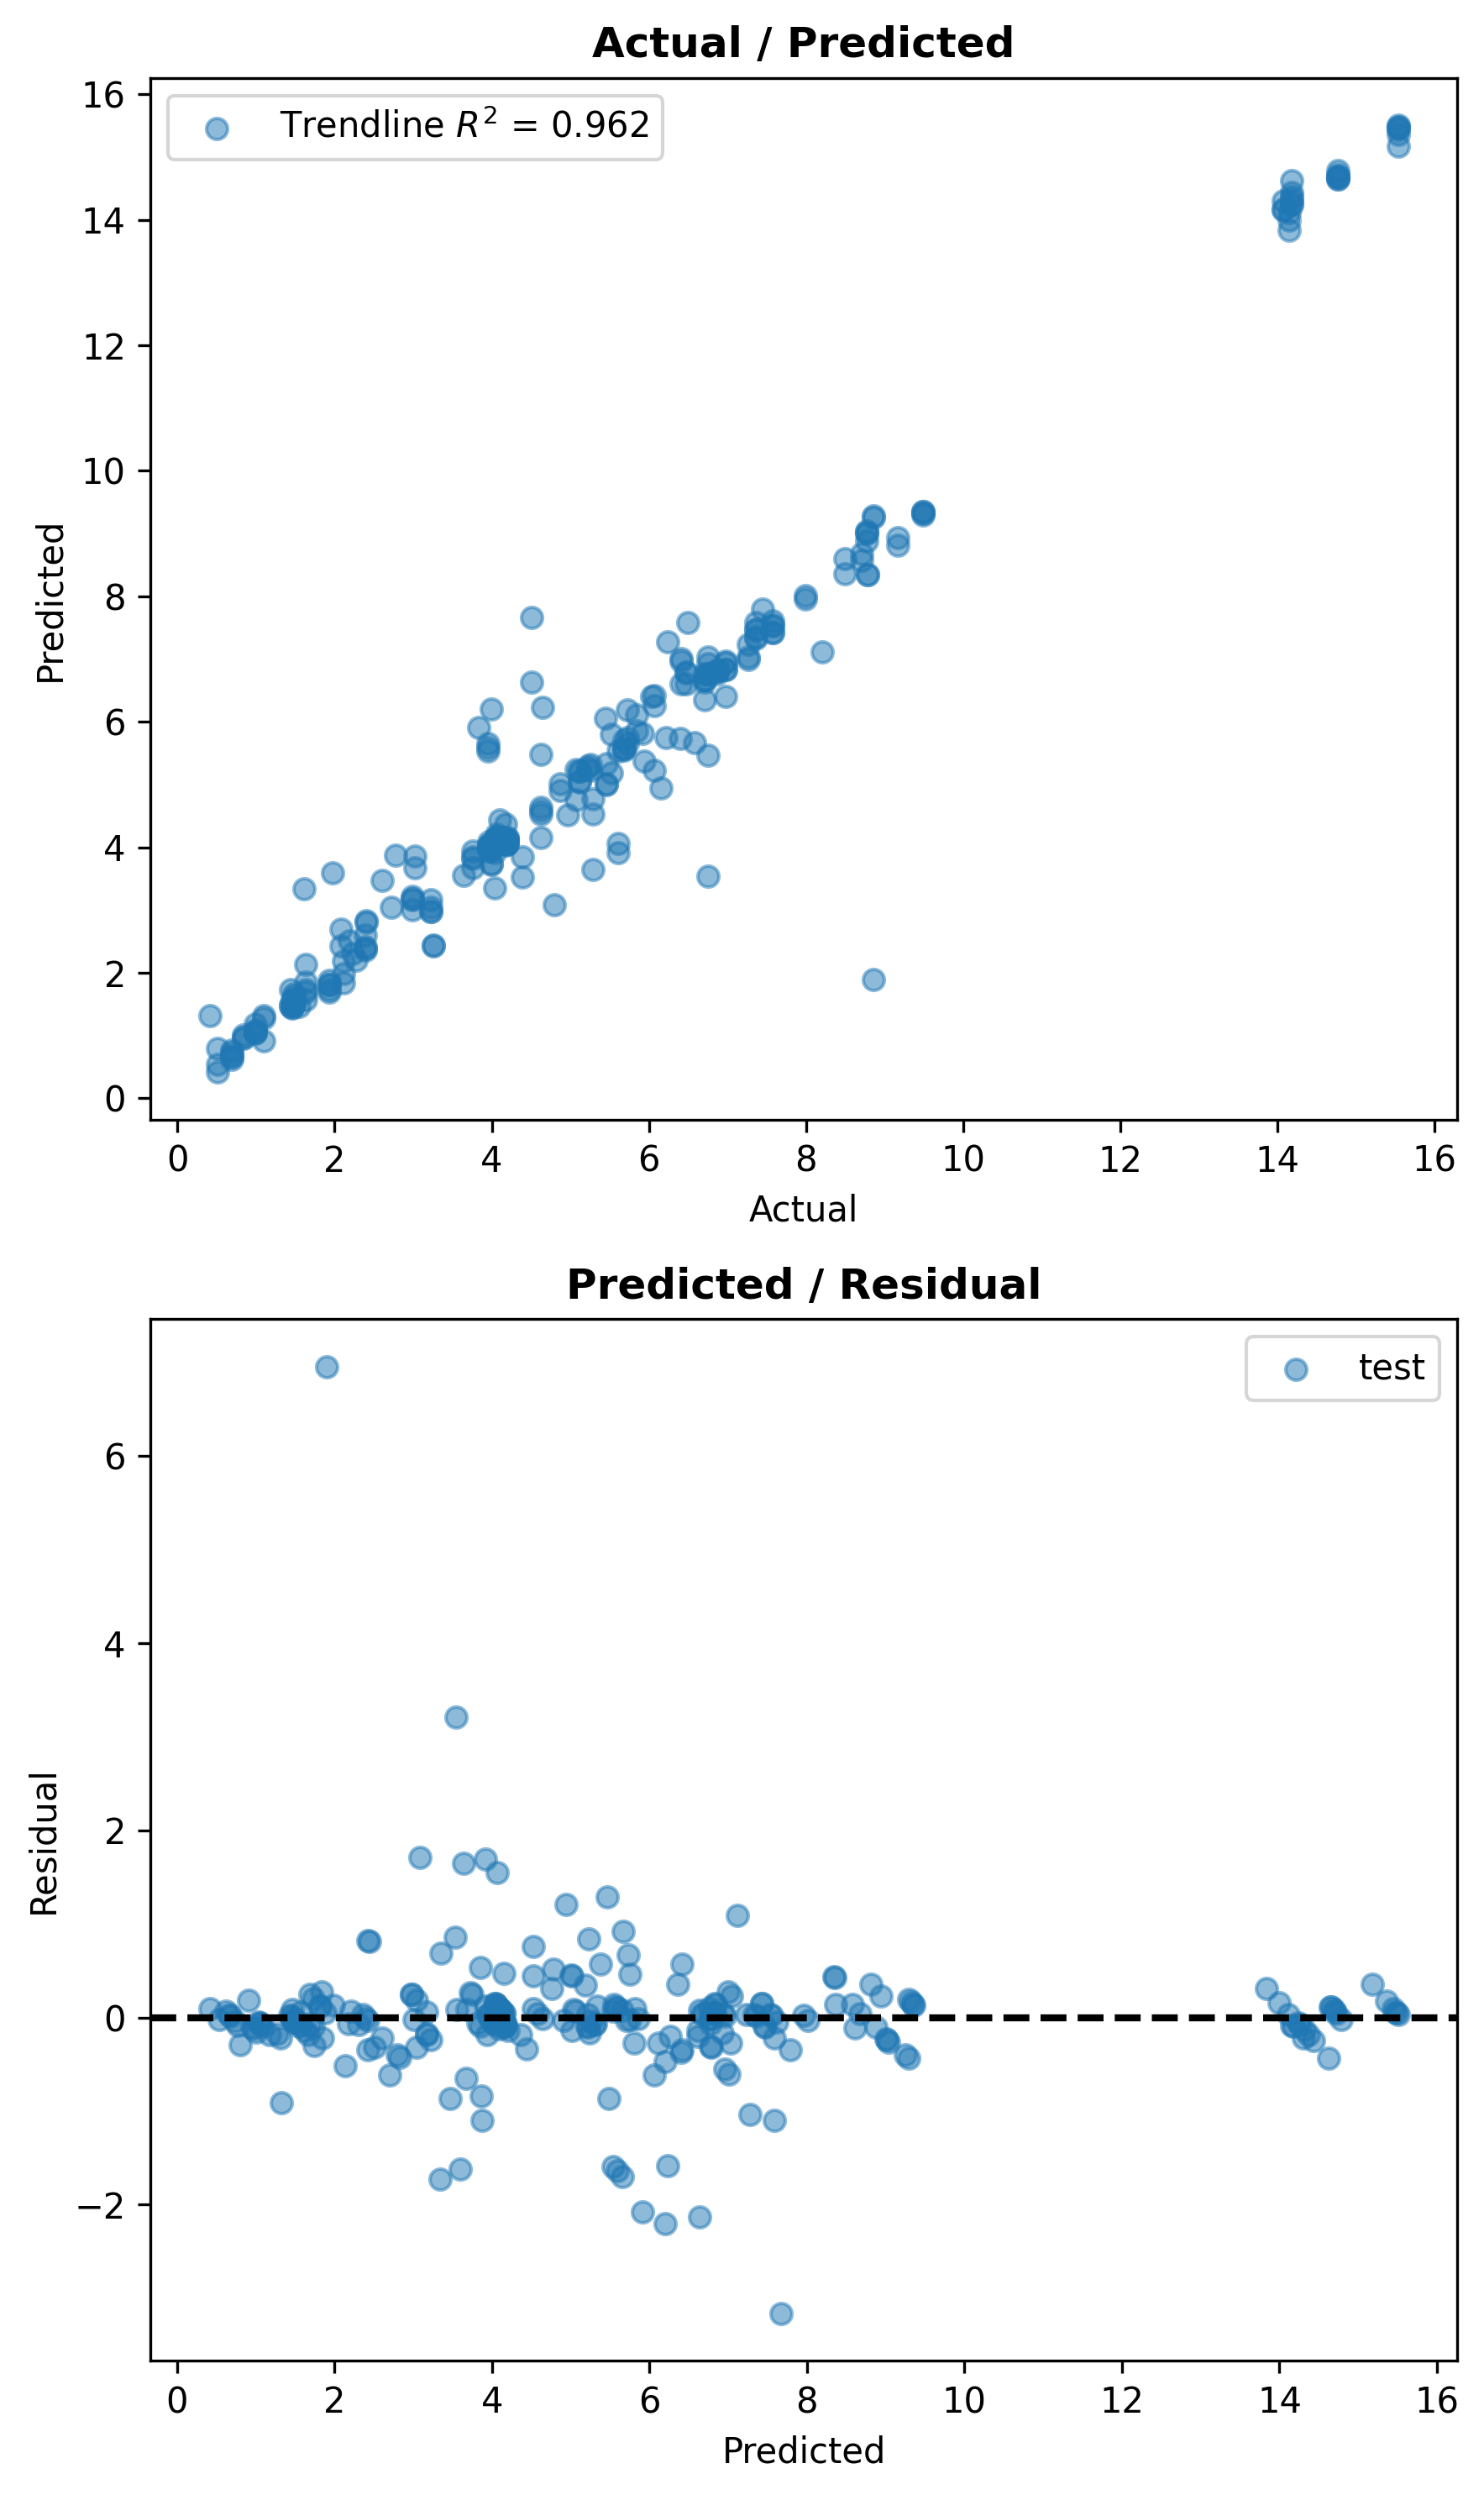

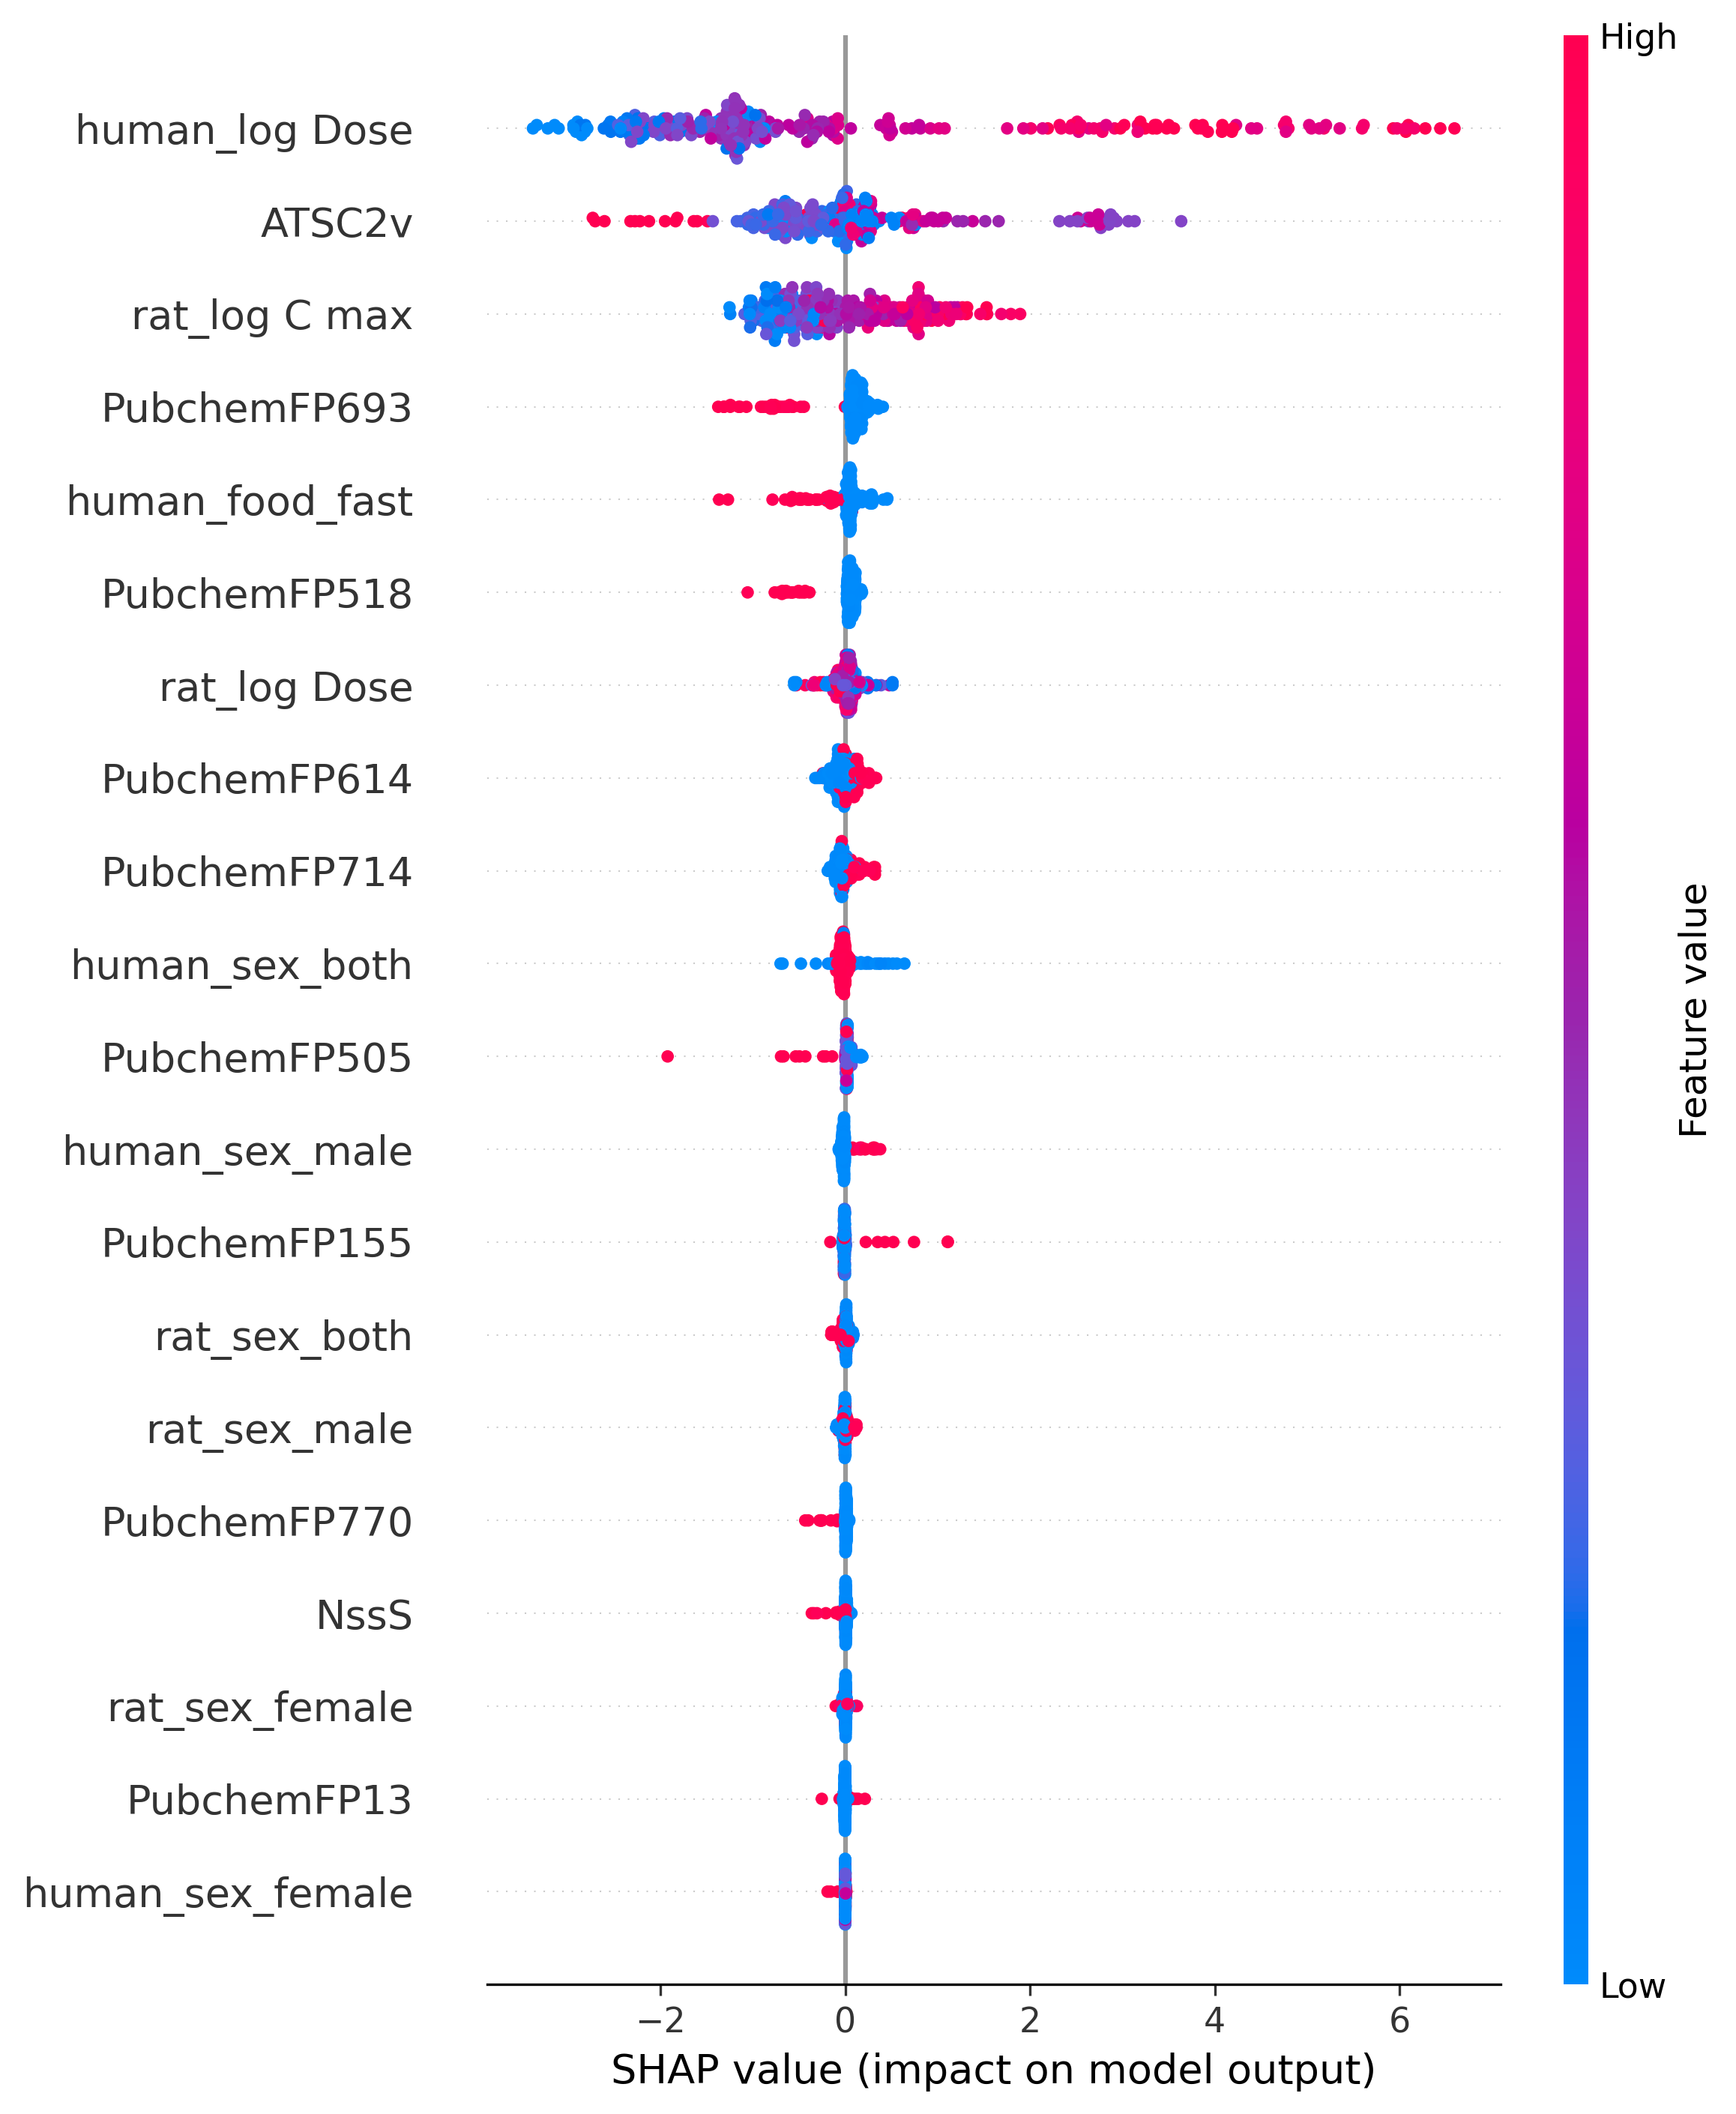

In [125]:
# Plot Residual and Actual/Predicted for the best model above in CV10fold 
print('Cmax CV 10 fold')
model_name = "XGBoost"
y_true_all = np.array(results[model_name]['y_true_all'])
y_pred_all = np.array(results[model_name]['y_pred_all'])
print('\nFor', model_name)
plot_residual_for_kfold_cv(y_true_all, y_pred_all)

plt.figure(dpi=300)
final_shap_matrix = np.vstack(oof_shap_values)
final_X_scaled_df = pd.concat(oof_X_test_scaled, axis=0)
shap.summary_plot(final_shap_matrix, final_X_scaled_df)

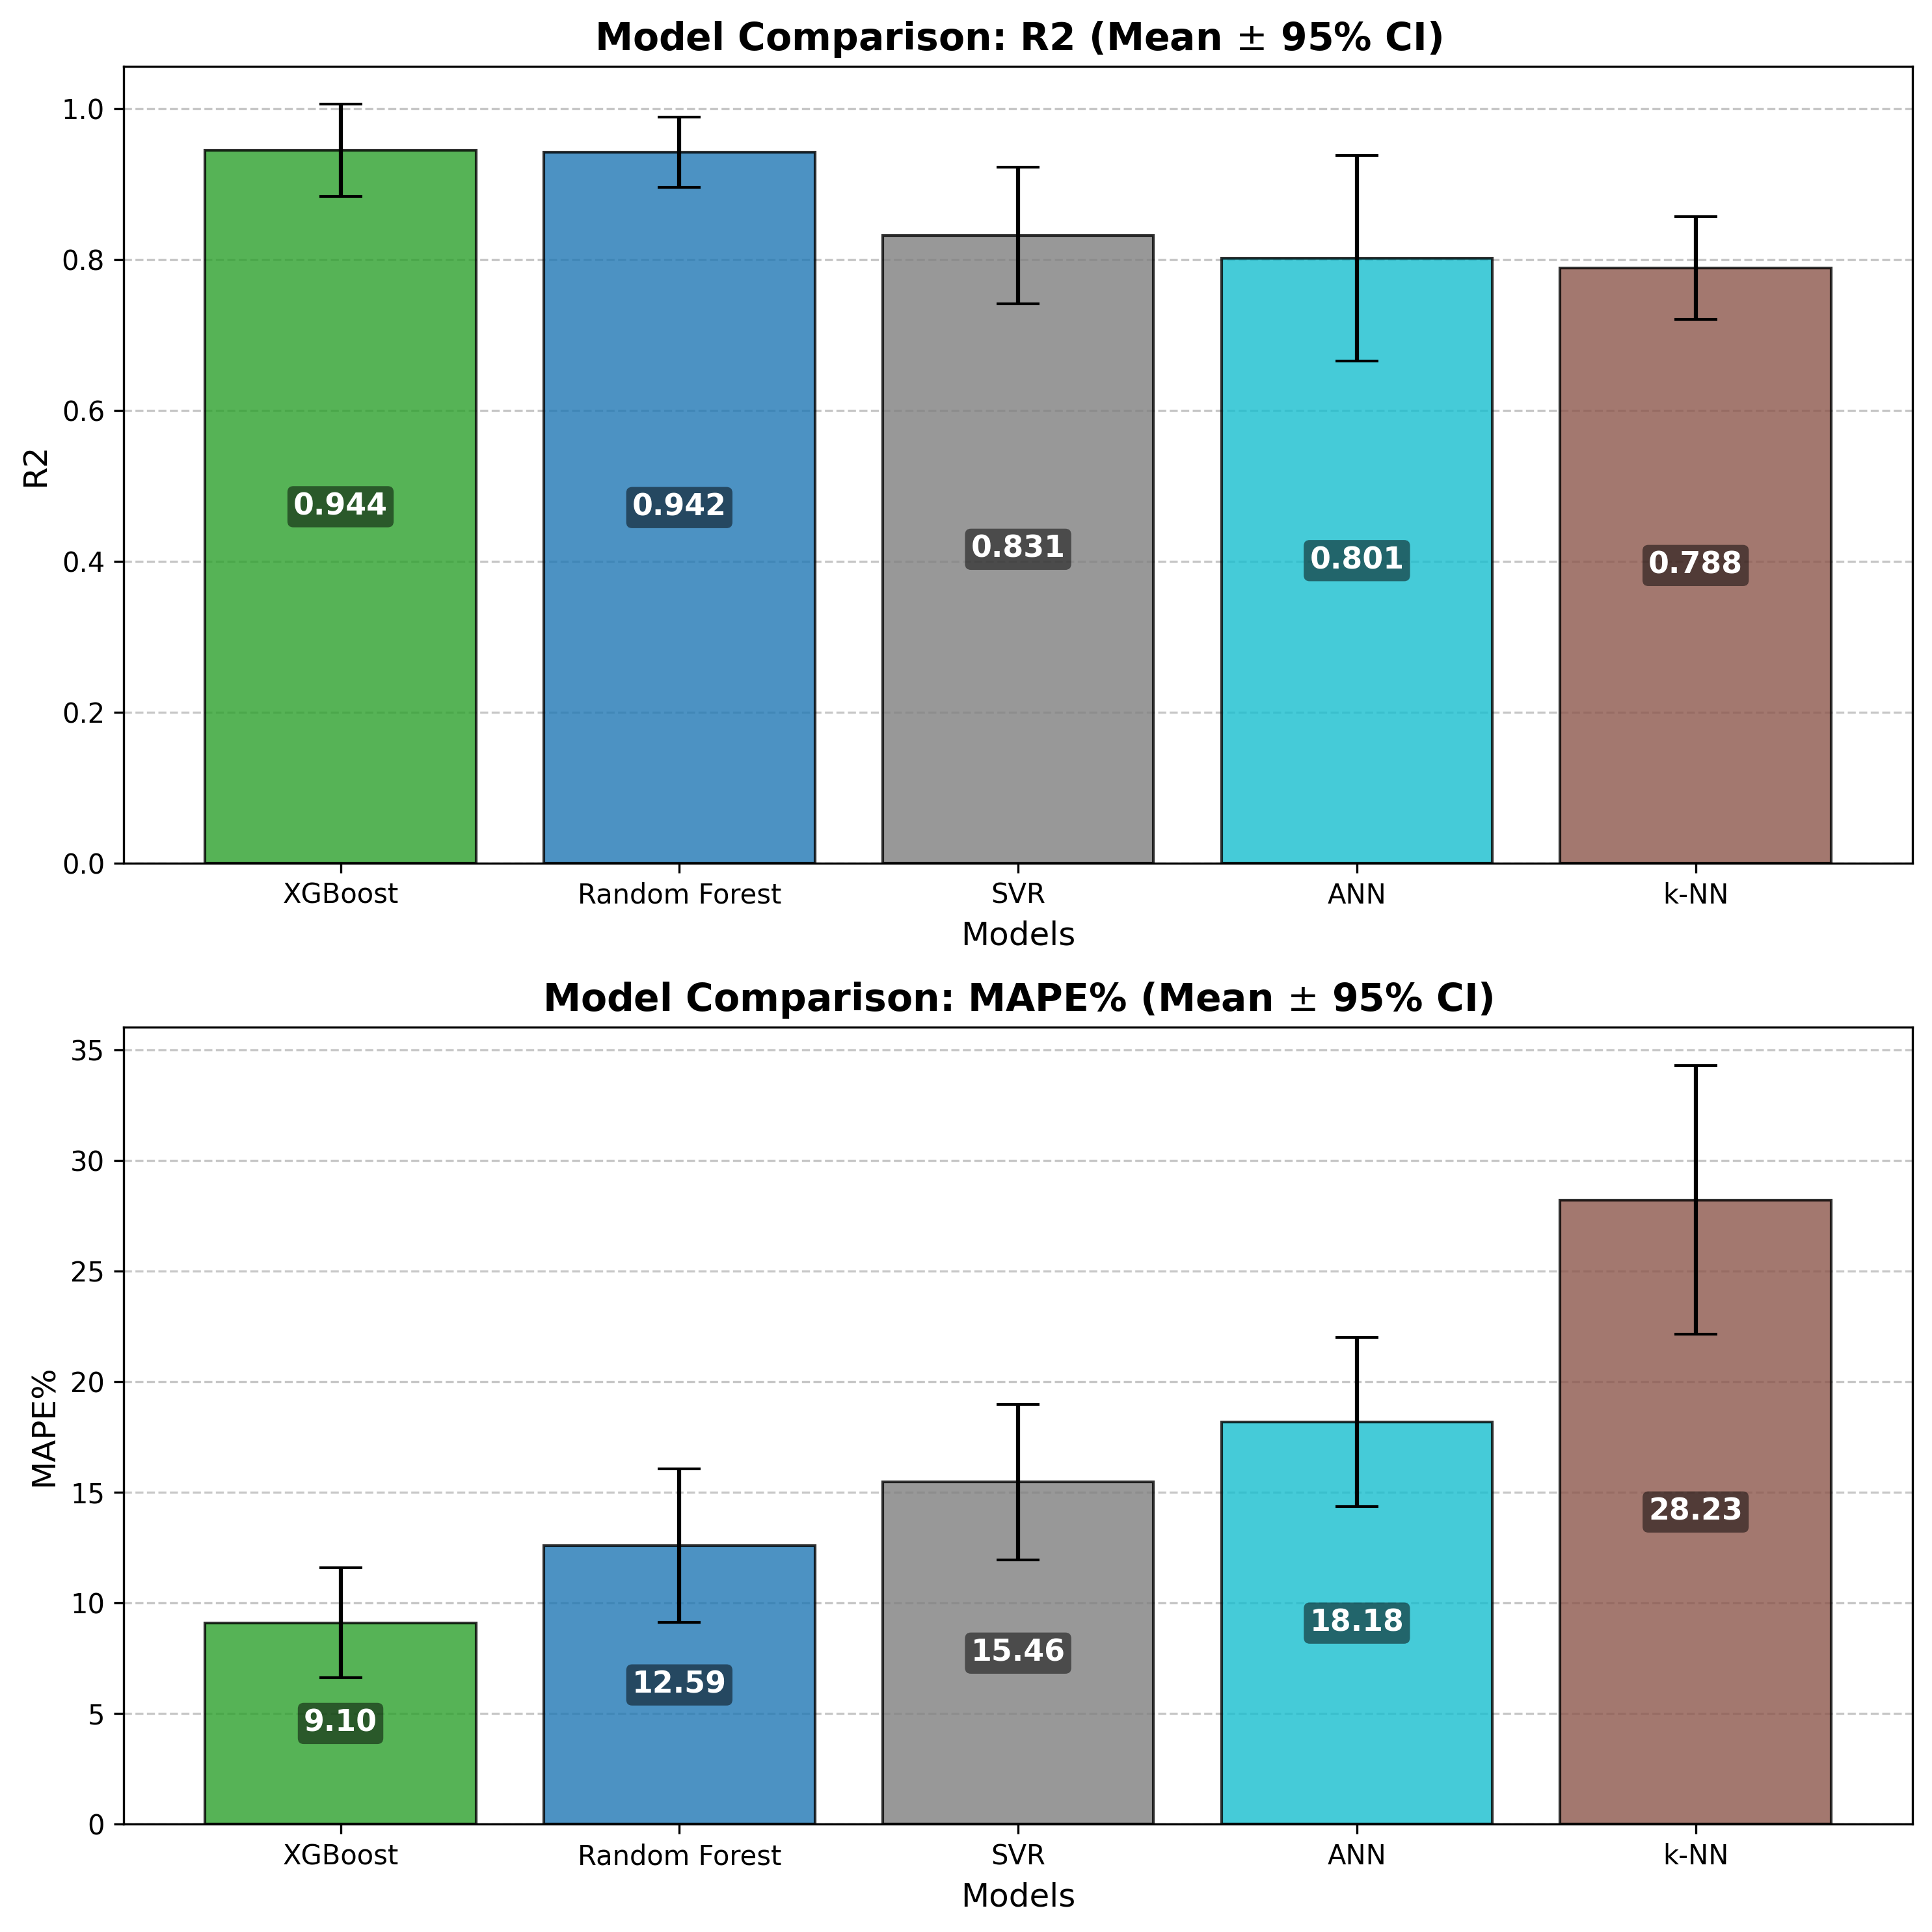

In [126]:
plot_cv_results_with_ci(results_all_folds_seperated, metrics_to_plot=['R2', 'MAPE%'])

=== Cmax R2 with bootstrap CI  (cluster bootstrap by drug, n_boot=5000) ===


,R2,CI 95% low,CI 95% high,Bootstrap SE
XGBoost,0.961,0.838,0.987,0.040
Random Forest,0.956,0.828,0.982,0.042
SVR,0.858,0.453,0.943,0.133
ANN,0.839,0.453,0.918,0.128
k-NN,0.811,0.346,0.906,0.150



=== Cmax Pairwise ΔR2 (paired bootstrap, p adjusted by: holm) ===


,Model A,Model B,ΔR2 (A-B),CI low,CI high,p (raw),p (holm),Significant
0,XGBoost,Random Forest,0.006,-0.008,0.032,0.2933,0.8800,False
1,XGBoost,SVR,0.104,0.008,0.420,0.0222,0.1332,False
2,XGBoost,ANN,0.122,0.062,0.399,0.0002,0.0020,True
3,XGBoost,k-NN,0.151,0.065,0.518,0.0002,0.0020,True
4,Random Forest,SVR,0.098,0.002,0.401,0.0462,0.2310,False
5,Random Forest,ANN,0.117,0.057,0.388,0.0002,0.0020,True
6,Random Forest,k-NN,0.145,0.061,0.510,0.0006,0.0042,True
7,SVR,ANN,0.018,-0.140,0.232,0.7077,1.0000,False
8,SVR,k-NN,0.047,-0.008,0.212,0.0926,0.3703,False
9,ANN,k-NN,0.029,-0.122,0.225,0.5981,1.0000,False


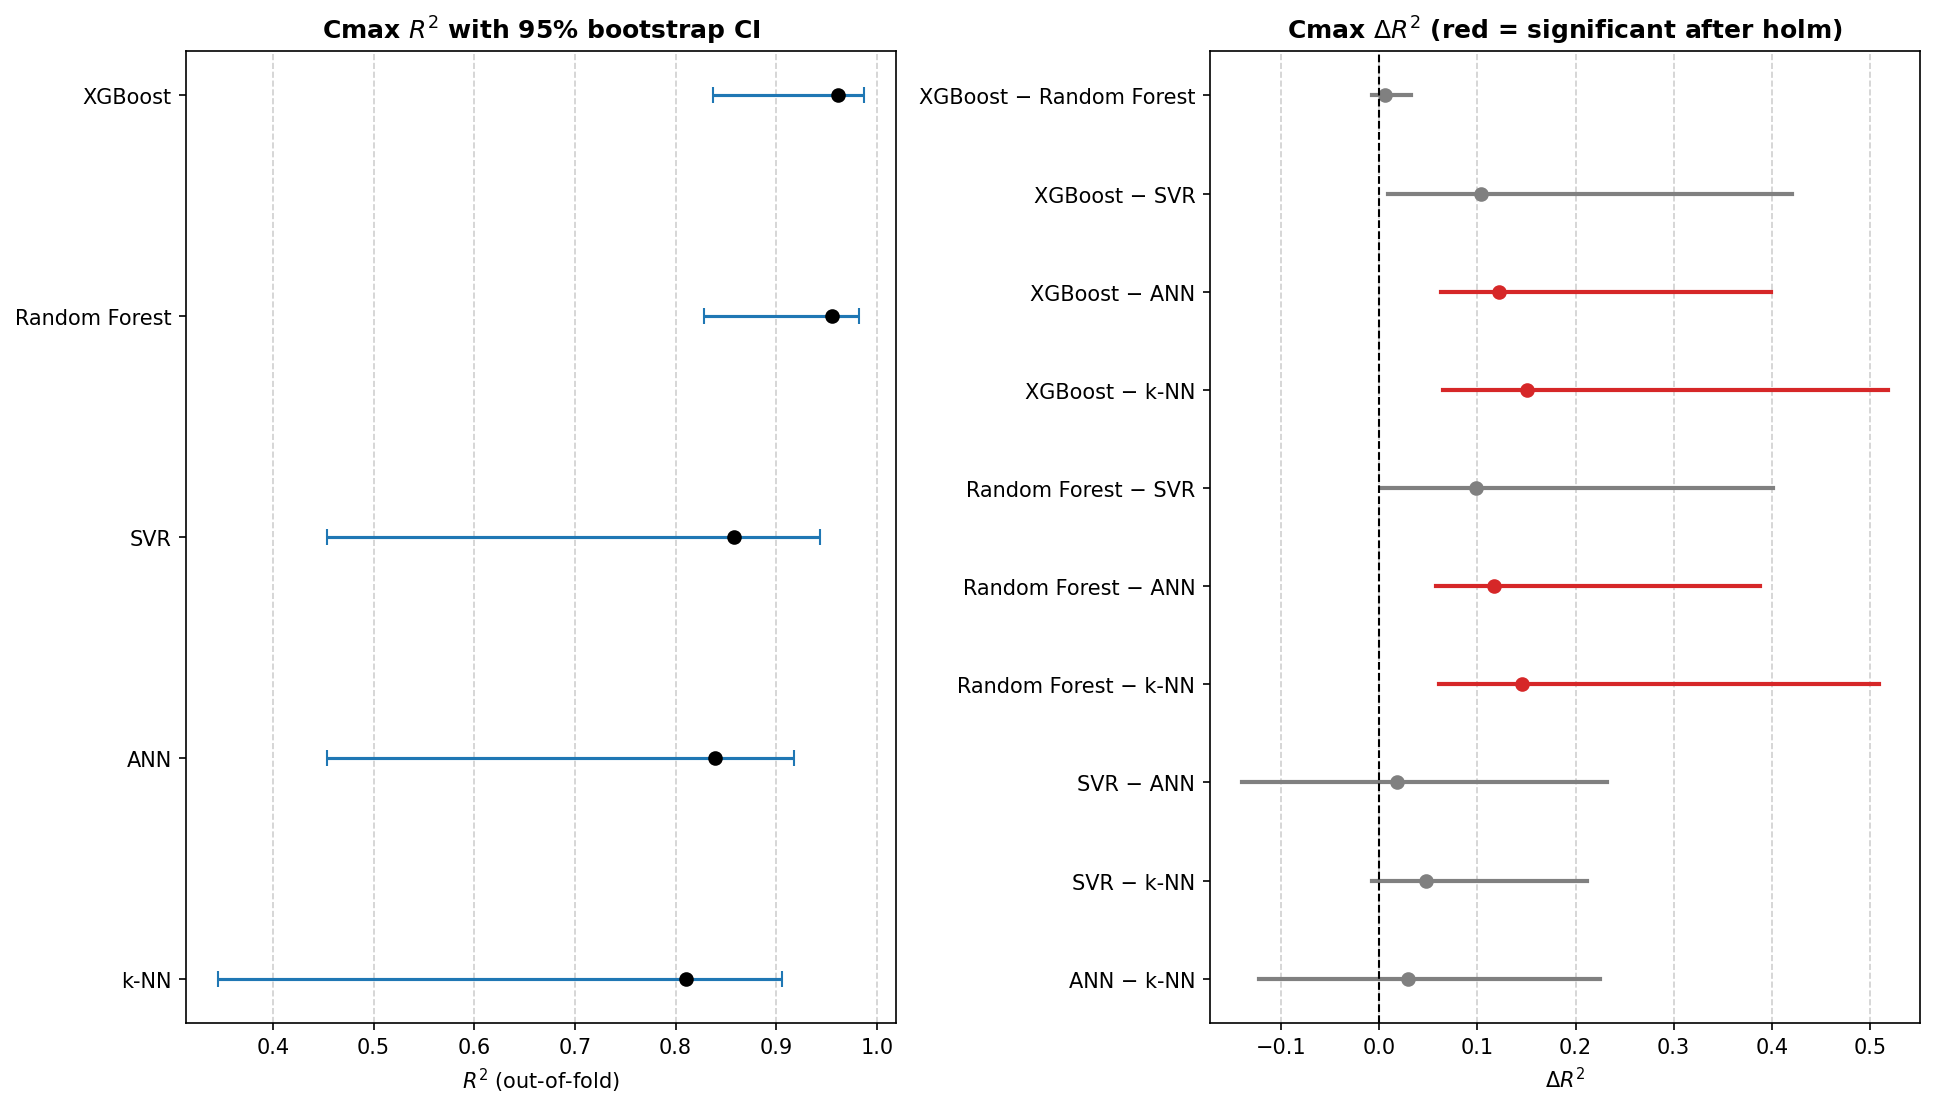

In [127]:
# Cmax: paired cluster-bootstrap comparison of R2 between models
# Run this right after the nested 10-fold CV cell above (it uses `results`, `kf`, `X` and `df` from that cell)

# Row order of y_true_all / y_pred_all = order of the test folds of kf
oof_order = np.concatenate([test_idx for _, test_idx in kf.split(X)])
# Resample whole drugs, because rows (doses) of the same drug are not independent
drug_groups = df['Parent_SMILES'].values[oof_order]

r2_table_cmax, diff_table_cmax, boot_cmax = compare_models_r2_bootstrap(
    results,
    groups=drug_groups,      # set to None for an ordinary row-wise bootstrap
    n_boot=5000,
    comparisons='all',       # 'all' = every pair of models, 'vs_best' = best model vs each other model
    p_adjust='holm',         # 'holm' (recommended), 'bonferroni', 'fdr_bh' or None
    alpha=0.05,
    title='Cmax',
)

# with pd.ExcelWriter('Cmax_bootstrap_R2_comparison.xlsx') as writer:
#     r2_table_cmax.to_excel(writer, sheet_name='R2 with CI')
#     diff_table_cmax.to_excel(writer, sheet_name='Pairwise dR2', index=False)


In [128]:
# All Points not each fold
pd.DataFrame(np.abs(y_true_all - y_pred_all)/np.abs(y_true_all)*100, columns = ['Relative Error%']).to_excel('Cmax_for_each_point_RE%.xlsx')

In [129]:
# Predicting for compound 4a: After training on ALL dataset

X = df[cols[1:-1]] # Without DrugName and Target Column
y = df[cols[-1]]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)
X_train, y_train = X, y
X_for_my_drug_4a = MY_DF[cols[1:-1]]

print("shape of X_train, y_train")
print(X_train.shape, y_train.shape)
models = {
    # "Linear Regression": LinearRegression(),
    # "Linear (Ridge)": Ridge(alpha=1.0),
    # "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42),
    # "k-NN (Similarity)": KNeighborsRegressor(n_neighbors=5),
    # "SVR (Support Vector)": SVR(kernel='rbf', C=10, epsilon=0.1),
    # "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(20, 5), max_iter=2000, random_state=42),
    # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), 

}

for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    
    # Create a pipeline that standardizes the data THEN fits the model
    # This ensures no data leakage during cross-validation
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])
    
    
    y_true_all = []
    y_pred_all = []
    
    # Train the pipeline (scales X_train, then fits model)
    pipeline.fit(X_train, y_train)

    y_pred_for_my_drug_4a = pipeline.predict(X_for_my_drug_4a)
        
        # Store true and predicted values

# 5. Display the final results as a DataFrame
print("\n--- Cmax Predicted results for compound 4a ---")
pd.DataFrame((DOSES, y_pred_for_my_drug_4a, np.exp(y_pred_for_my_drug_4a)-1)).T.style.format("{:.3f}")

shape of X_train, y_train
(270, 21) (270,)
Evaluating XGBoost...

--- Cmax Predicted results for compound 4a ---


,0,1,2
0,28.200,5.363,212.423
1,56.400,5.765,317.851
2,112.800,6.902,993.633
3,169.200,7.070,1175.489
4,225.600,7.018,1115.666


# Tmax Predicting

In [131]:
# other_features  = [      
#      'MW',
#      'SLogP',
#      'TopoPSA',
#      'nHBDon',
#      'nHBAcc',
#      'nRot',
#      'nRing',
#      'nHeavyAtom',
#      'QED',
#      'BertzCT',
#      'LabuteASA',
#      'FCSP3',
#      'SMR',
#     ]

# other_features_names = list(other_features_filtered.columns)

n = 25
importance_df = pd.read_excel('Tmax_all_features_importances_xgboost_human_as_label.xlsx', index_col=0)
other_features_names = importance_df.iloc[:n, 0].values.tolist()


### Feature Selection with: Plus-L Minus-R method for feature selection

In [132]:
# n = 30

# # PLUS-L MINUS-R (SFFS) FEATURE SELECTION
# # -----------------------------------------------------------------------
# # 1. all  candidate features that we want to select from
# all_candidate_features = list(other_features_filtered.columns)[1:] # because first is SMILES strings

# # Prepare a temporary X and y just for the feature selection phase
# X_selection = final_df[all_candidate_features]
# y_selection = final_df['human_log T max (hr)']

# # Drop NaNs for the selection phase
# selection_df = pd.concat([X_selection, y_selection], axis=1).dropna()
# X_selection_clean = selection_df[all_candidate_features]
# y_selection_clean = selection_df['human_log T max (hr)']

# # 2.  The base estimator for evaluating the features
# # Using a fast configuration here saves time during the intense selection loops.
# fs_model = xgb.XGBRegressor(n_estimators=100, max_depth=3, random_state=42, n_jobs=-1)

# # 3. Initialize the Plus-L Minus-R Selector (Sequential Floating Forward Selection)
# sffs = SFS(
#     estimator=fs_model, 
#     k_features=(10, n),      # The algorithm will find the optimal number of features between 10 and 25
#     forward=True,             # True = Forward Selection
#     floating=True,            # True = PLUS-L MINUS-R Logic (This is what the reviewer asked for!)
#     scoring='neg_mean_squared_error', # Evaluation metric
#     # scoring='neg_mean_absolute_percentage_error',
#     cv=5,                     # 5-fold cross-validation during selection to prevent overfitting
#     n_jobs=-1,                # Use all CPU cores
#     verbose=2
# )

# print("Starting Plus-L Minus-R Feature Selection. This may take a few minutes...")

# # 4. Fit the selector
# sffs = sffs.fit(X_selection_clean, y_selection_clean)

# # 5. Extract the best feature names chosen by the algorithm
# other_features_names = list(sffs.k_feature_names_)

# path = 'Tmax_all_Selected_Features_PlusL_MinusR.json'
# with open(path, 'w') as f:
#     json.dump(other_features_names, f)
        
# print(f"Algorithm finished! Optimal number of features selected: {len(other_features_names)}")
# print(f"Selected Features: {other_features_names}")


In [133]:
path = 'Tmax_all_Selected_Features_PlusL_MinusR.json'
with open(path) as f:
    other_features_names = json.load(f)

# other_features_names = ['rat_food_nonfast', 'nX', 'NaaN', 'NdssS', 'n5ARing', 'PubchemFP1', 'PubchemFP180', 'PubchemFP691', 'PubchemFP713', 'PubchemFP861']
other_features_names

['rat_food_nonfast',
 'nX',
 'NaaN',
 'NdssS',
 'n5ARing',
 'PubchemFP1',
 'PubchemFP180',
 'PubchemFP691',
 'PubchemFP713',
 'PubchemFP861']

In [134]:
cols1 =  [
    'Parent_SMILES',
#     'Dose (mg/kg)',
    'rat_log Dose','human_log Dose',

    'rat_sex_both', 'rat_sex_female','rat_sex_male',
    'human_sex_both', 'human_sex_female','human_sex_male',
#     'type_rad', 'type_simple',
]
cols2 = [
    # 'rat_log time', 'human_log time',
#     'time','time',
    
    # 'rat_is_time_inf','human_is_time_inf',
    # 'rat_log AUC','human_log AUC',
    
#     'rat_log C max','human_log C max',
    'rat_log T max (hr)','human_log T max (hr)',

]


cols = cols1 + other_features_names + cols2
cols

df = final_df[cols]
df = df.dropna(subset=['rat_log T max (hr)','human_log T max (hr)'])
# only keeps one rat data (not several rat data) just lowest dose
# df = df.sort_values('Dose (mg/kg)').groupby('Compound').first().reset_index()

# Keep only the first occurrence of each column name
df = df.loc[:, ~df.columns.duplicated()]
cols = list(df.columns)
df.shape

(201, 21)

In [135]:
column_df = pd.DataFrame([cols]).T
column_df.columns = ['Features Tmax']
print('Tmax')
column_df.drop(0, axis=0)

Tmax


,Features Tmax
1,rat_log Dose
2,human_log Dose
3,rat_sex_both
4,rat_sex_female
5,rat_sex_male
6,human_sex_both
7,human_sex_female
8,human_sex_male
9,rat_food_nonfast
10,nX


In [136]:
rdf = df.copy()

### Outlier Removal  (uncomment it if you want to peform)

In [137]:
# # 1. Identify strictly continuous columns (exclude one-hot/binary/categorical)
# # We assume a continuous variable should have more than 10 unique values.
# UNIQUE_THRESHOLD = 5 # 10 default

# all_numeric_cols = rdf.select_dtypes(include=[np.number]).columns
# continuous_cols = [col for col in all_numeric_cols if rdf[col].nunique() > UNIQUE_THRESHOLD]

# print(f"Total numeric columns: {len(all_numeric_cols)}")
# print(f"Continuous columns selected for outlier removal: {len(continuous_cols)}")

# # 2. Calculate IQR and bounds ONLY for continuous columns
# Q1 = rdf[continuous_cols].quantile(0.25)
# Q3 = rdf[continuous_cols].quantile(0.75)
# IQR = Q3 - Q1  

# # Using a multiplier of 3 for extreme outliers (adjust to 1.5 for standard outliers)
# lower_bound = Q1 - 3 * IQR
# upper_bound = Q3 + 3 * IQR

# # 3. Create the boolean mask for continuous columns
# # True means the value is an inlier (within bounds)
# mask = ~((rdf[continuous_cols] < lower_bound) | (rdf[continuous_cols] > upper_bound))

# # # 4. Filter the DataFrame
# # df = rdf[mask.all(axis=1)]

# # # 5. Report the results
# # rows_removed = len(rdf) - len(df)
# # percent_removed = rows_removed / len(rdf)
# # print(f"Removed {rows_removed} rows ({percent_removed:.1%} of data)")

# # This limits the values in the column to be no lower than lower_bound and no higher than upper_bound
# df_cleaned = rdf.copy()
# for col in continuous_cols:
#     df_cleaned[col] = rdf[col].clip(lower=lower_bound[col], upper=upper_bound[col])


# df = df_cleaned

# # mask.sum()

In [138]:
# Tamax train test split method (Standard Scaler for all with pipeline)
# drugs = rdf['Canonical SMILES'].unique()
# drugs_train, drugs_test = train_test_split(drugs, test_size=0.1, random_state=42)
# df.index = df['Canonical SMILES']
# df_train = df.loc[drugs_train]
# df_test = df.loc[drugs_test]

# X_train = df_train[cols[1:-1]] # Without DrugName and Target Column
# X_test = df_test[cols[1:-1]]

# y_train = df_train[cols[-1]]
# y_test = df_test[cols[-1]]

X = df[cols[1:-1]] # Without DrugName and Target Column
y = df[cols[-1]]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

print("shape of X_train, X_test")
print(X_train.shape, X_test.shape)

models = {
    "Linear Regression": LinearRegression(),
    "Linear (Ridge)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42),
    "k-NN (Similarity)": KNeighborsRegressor(n_neighbors=5),
    "SVR (Support Vector)": SVR(kernel='rbf', C=10, epsilon=0.1),
    "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(1500), max_iter=2000, random_state=42),
    "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), 

}


# Dictionary to store the overall performance of each model
results = {}

# 4. Loop through each model and evaluate using LOGOCV
for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    
    # Create a pipeline that standardizes the data THEN fits the model
    # This ensures no data leakage during cross-validation
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])
    
    
    y_true_all = []
    y_pred_all = []
    
    # Train the pipeline (scales X_train, then fits model)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
        
        # Store true and predicted values
    y_true_all.extend(y_test.values)
    y_pred_all.extend(y_pred)
        
    # Calculate overall metrics for the model
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    mae = mean_absolute_error(y_true_all, y_pred_all)
    mape = mean_absolute_percentage_error(y_true_all, y_pred_all)*100
    
    r2 = r2_score(y_true_all, y_pred_all)
    
    # Save results
    results[model_name] = {'RMSE': rmse, 'MAPE%':mape, 'MAE': mae, 'R2': r2}

# 5. Display the final results as a DataFrame
results_df = pd.DataFrame(results).T
print("\n--- Final Model Performance Tmax ---")
print(results_df.sort_values(by='RMSE', ascending=True))

shape of X_train, X_test
(180, 19) (21, 19)
Evaluating Linear Regression...
Evaluating Linear (Ridge)...
Evaluating Random Forest...
Evaluating XGBoost...
Evaluating k-NN (Similarity)...
Evaluating SVR (Support Vector)...
Evaluating ANN (MLP)...
Evaluating ElasticNet...

--- Final Model Performance Tmax ---
                          RMSE      MAPE%       MAE        R2
XGBoost               0.127943   7.358995  0.082903  0.933490
Random Forest         0.128171   7.066912  0.079079  0.933253
SVR (Support Vector)  0.133068   8.296588  0.104071  0.928055
ANN (MLP)             0.145197   9.480041  0.110560  0.914343
k-NN (Similarity)     0.202551  12.236212  0.145929  0.833306
Linear Regression     0.260608  17.153055  0.204457  0.724051
Linear (Ridge)        0.261667  17.276866  0.205709  0.721805
ElasticNet            0.364289  29.151122  0.323615  0.460808


In [139]:
# Plotting Residual Plot and Actual/Predicted plot
model = models['XGBoost']

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', model)
])

# 3. Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# 4. Make predictions using the PIPELINE, not the base model
y_pred_train = pipeline.predict(X_train)
y_pred = pipeline.predict(X_test)

y_pred_real = y_pred
y_test_real = y_test


mape = 100*mean_absolute_percentage_error(y_test_real, y_pred_real)
r2 = r2_score(y_test_real, y_pred_real)   
mse = mean_squared_error(y_test, y_pred)
rmse = mse**(1/2)

var = y_test.std()**2
print(f'{r2=:.3f}, {mape=:.3f} {mse=:.4f} {rmse=:.3f} {var=:3f}')

acc_10 = tolerance_accuracy(y_test, y_pred, tolerance=0.10)
acc_15 = tolerance_accuracy(y_test, y_pred, tolerance=0.15)
acc_20 = tolerance_accuracy(y_test, y_pred, tolerance=0.20)

print(f"Accuracy (10% tolerance): {acc_10:.2%}")
print(f"Accuracy (15% tolerance): {acc_15:.2%}")
print(f"Accuracy (20% tolerance): {acc_20:.2%}")


#  # linregress calculates the exact same regression line that regplot draws
# res = linregress(y_test_real.ravel(), y_pred_real.ravel())
# r_squared_of_line = res.rvalue ** 2
# print(f'{r_squared_of_line=}')

# # calculating accuracy (error less than 10, 15 , 20 %)
# # Plot and pass the R^2 value to the line label to show in the legend
# sns.regplot(x=y_test_real, y=y_pred_real, color='black', line_kws={'label': f'Trendline $R^2$ = {r_squared_of_line:.3f}'})
# plt.legend()
# plt.show()

# # all train, and test
# plt.figure()
# plt.title('Actual/Predicted')
# plt.scatter(y_train, y_pred_train, color='tab:blue', alpha=0.5, label='train')
# plt.scatter(y_test, y_pred, color='black', alpha=0.5, label='test')
# plt.xlabel('Actual')
# plt.ylabel('Predicted')
# plt.legend()
# plt.show()


# res_train = y_train - y_pred_train
# res_test = y_test - y_pred
# plt.figure()
# plt.title('Predicted/Residual')
# plt.scatter(y_pred_train, res_train, color='tab:blue', alpha=0.5, label='train')
# plt.scatter(y_pred, res_test, color='black', alpha=0.5, label='test')
# plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# plt.xlabel('Predicted')
# plt.ylabel('Residual')
# plt.legend()
# plt.show()

# plt.figure()
# plt.title('Actual/Residual')
# plt.scatter(y_train, res_train, color='tab:blue', alpha=0.5, label='train')
# plt.scatter(y_test, res_test, color='black', alpha=0.5, label='test')
# plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
# plt.xlabel('Actual')
# plt.ylabel('Residual')
# plt.legend()
# plt.show()

r2=0.933, mape=7.359 mse=0.0164 rmse=0.128 var=0.258427
Accuracy (10% tolerance): 7619.05%
Accuracy (15% tolerance): 8095.24%
Accuracy (20% tolerance): 8571.43%


In [140]:
# Run this code if we want to see which features are better in all features

# xgboost = models["XGBoost"]
# col_names = cols[1:-1]

# importance_df = pd.DataFrame({
#     'Feature': col_names,
#     'Importance': xgboost.feature_importances_
# })

# importance_df.sort_values(by='Importance', ascending=False, inplace=True)
# importance_df.to_excel('Tmax_all_features_importances_xgboost_seperated_rows.xlsx')
# importance_df.head(10)

In [141]:
# Run this code if we want to see which features are better in all features

# rf = models["Random Forest"]
# col_names = df.columns[1:-1]

# # feature_importances = list(zip(rf.feature_importances_, col_names))
# # sorted_importances = sorted(feature_importances, key=lambda x:x[0], reverse=True)
# # sorted_importances

# importance_df = pd.DataFrame({
#     'Feature': col_names,
#     'Importance': rf.feature_importances_
# })

# importance_df.sort_values(by='Importance', ascending=False, inplace=True)
# importance_df.to_excel('Tmax_all_features_importances_xgboost_human_as_label.xlsx')
# importance_df.head(100)

In [142]:
# # Cmax Hyperparameter Optimization for the best model (least MAPE%): XGboost

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]  

# print("Shape of X, y:")
# print(X.shape, y.shape)

# # ==============================================================================
# # PHASE 1: Optuna Bayesian Optimization for XGBoost
# # ==============================================================================
# def objective(trial):
#     # Define hyperparameter search space for XGBoost
#     param = {
#         'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
#         'max_depth': trial.suggest_int('max_depth', 3, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
#         'random_state': 42,
#         'n_jobs': -1 # Utilize all CPU cores for speed
#     }
    
#     cv = KFold(n_splits=10, shuffle=True, random_state=42)
#     fold_mapes = []
    
#     for train_index, test_index in cv.split(X):
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        
#         # We must scale data inside the CV loop during Optuna tuning as well
#         pipeline = Pipeline([
#             ('scaler', StandardScaler()),
#             ('xgb', xgb.XGBRegressor(**param))
#         ])
        
#         pipeline.fit(X_train, y_train)
#         y_pred = pipeline.predict(X_test)
        
#         # Calculate MAPE% for this fold
#         mape = mean_absolute_percentage_error(y_test, y_pred) * 100
#         fold_mapes.append(mape)
        
#     # Return the mean MAPE% across all 10 folds to Optuna
#     return np.mean(fold_mapes)

# print("\n--- Starting Optuna Optimization for XGBoost ---")
# # Create a study object and optimize to MINIMIZE the MAPE%
# study = optuna.create_study(direction='minimize')
# study.optimize(objective, n_trials=50)

# print("\n--- Optuna Tuning Complete ---")
# print("Best XGBoost Parameters:", study.best_params)
# print(f"XGBoost Cmax Best Hyperparameters CV MAPE%: {study.best_value:.2f}%")


In [143]:
# # Tmax Hyperparameter Optimization for the best model (least MAPE%): XGboost

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]  

# print("Shape of X, y:")
# print(X.shape, y.shape)

# # ==============================================================================
# # PHASE 1: Optuna Bayesian Optimization for XGBoost
# # ==============================================================================
# def objective(trial):
#     # Define hyperparameter search space for XGBoost
#     param = {
#         'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
#         'max_depth': trial.suggest_int('max_depth', 3, 10),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
#         'random_state': 42,
#         'n_jobs': -1 # Utilize all CPU cores for speed
#     }
    
#     cv = KFold(n_splits=10, shuffle=True, random_state=42)
#     fold_mapes = []
    
#     for train_index, test_index in cv.split(X):
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        
#         # We must scale data inside the CV loop during Optuna tuning as well
#         pipeline = Pipeline([
#             ('scaler', StandardScaler()),
#             ('xgb', xgb.XGBRegressor(**param))
#         ])
        
#         pipeline.fit(X_train, y_train)
#         y_pred = pipeline.predict(X_test)
        
#         # Calculate MAPE% for this fold
#         mape = mean_absolute_percentage_error(y_test, y_pred) * 100
#         fold_mapes.append(mape)
        
#     # Return the mean MAPE% across all 10 folds to Optuna
#     return np.mean(fold_mapes)

# print("\n--- Starting Optuna Optimization for XGBoost ---")
# # Create a study object and optimize to MINIMIZE the MAPE%
# study = optuna.create_study(direction='minimize')
# study.optimize(objective, n_trials=50)

# print("\n--- Optuna Tuning Complete ---")
# print("Best XGBoost Parameters:", study.best_params)
# print(f"XGBoost Tmax Best Hyperparameters CV MAPE%: {study.best_value:.2f}%")


In [144]:
# # Tmax 10 fold crossvalidation method
# best_xgb_params = {'n_estimators': 183, 'max_depth': 5, 'learning_rate': 0.17998116713270781, 'subsample': 0.9975264486614795, 'colsample_bytree': 0.6540375505132371}

# # 1. Prepare features and target
# X = df[cols[1:-1]]  # Without DrugName and Target Column
# y = df[cols[-1]]

# print("Shape of X, y:")
# print(X.shape, y.shape)

# models = {
#     # "Linear Regression": LinearRegression(),
#     # "Linear (Ridge)": Ridge(alpha=1.0),
#     "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
#     "XGBoost": xgb.XGBRegressor(**best_xgb_params),
#     "k-NN": KNeighborsRegressor(n_neighbors=5),
#     "SVR": SVR(kernel='rbf', C=10, epsilon=0.1),
#     "ANN": MLPRegressor(hidden_layer_sizes=(20,10), max_iter=2000, random_state=42),
#     # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
# }

# # 3. Initialize 10-Fold Cross-Validation
# kf = KFold(n_splits=10, shuffle=True, random_state=42)

# # Dictionary to store the overall performance of each model
# results = {}
# results_all_folds_seperated = {}

# # Initialize lists to hold the SHAP values and the scaled features (Out of the fold Shap)
# oof_shap_values = []
# oof_X_test_scaled = []

# # 4. Loop through each model and evaluate using 10-Fold CV
# for model_name, model in models.items():
#     print(f"Evaluating {model_name}...")
    
#     results_all_folds_seperated[model_name] = {
#         "RMSE":[],
#         "MAE":[],
#         "MAPE%":[],
#         "R2":[]
#     }
    
#     # Create a pipeline that standardizes the data THEN fits the model
#     # This ensures no data leakage during cross-validation
#     pipeline = Pipeline([
#         ('scaler', StandardScaler()),
#         ('regressor', model)
#     ])

#     y_true_all = []
#     y_pred_all = []
#     for fold_idx, (train_index, test_index) in enumerate(kf.split(X), 1):
#         # print(f'fold = {fold_idx}')
#         X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#         y_train, y_test = y.iloc[train_index], y.iloc[test_index]

#         # Train the pipeline (scales X_train, then fits model)
#         pipeline.fit(X_train, y_train)

#         # Predict the held-out fold (scales X_test using X_train's parameters, then predicts)
#         y_pred = pipeline.predict(X_test)
        
#         # Store true and predicted values
#         y_true_all.extend(y_test.values)
#         y_pred_all.extend(y_pred)

#         # Calculate each fold metrics for the model to calculate SD and CI
#         results_all_folds_seperated[model_name]["RMSE"].append(np.sqrt(mean_squared_error(y_test.values, y_pred)))
#         results_all_folds_seperated[model_name]["MAE"].append(mean_absolute_error(y_test.values, y_pred))
#         results_all_folds_seperated[model_name]["MAPE%"].append(mean_absolute_percentage_error(y_test.values, y_pred) * 100)
#         results_all_folds_seperated[model_name]["R2"].append(r2_score(y_test.values, y_pred))

#         if model_name == "XGBoost":
#             shap_vals, x_scaled_vals = get_out_of_fold_shap(pipeline, X_train, X_test,X.columns, model_name )
#             oof_shap_values.append(shap_vals)
#             oof_X_test_scaled.append(x_scaled_vals)
            
#     # Calculate overall metrics for the model across all folds
#     rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
#     mae = mean_absolute_error(y_true_all, y_pred_all)
#     mape = mean_absolute_percentage_error(y_true_all, y_pred_all) * 100
#     r2 = r2_score(y_true_all, y_pred_all)
#     acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
#     acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
#     acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
#     # Save results
#     results[model_name] = {'RMSE': rmse, 'MAPE%': mape, 'MAE': mae, 'R2': r2,
#                            'y_true_all':y_true_all, 'y_pred_all':y_pred_all,
#                             'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20
#                           }
    
# # 5. Display the final results as a DataFrame
# results_df = pd.DataFrame(results).drop(['y_true_all', 'y_pred_all']).T
# print("\n--- Tmax Final Model Performance (10-Fold CV) ---")
# results_df.sort_values(by='RMSE', ascending=True).style.format("{:.3f}")

In [145]:
# nested 10 fold Tmax cross validation for both hyperparamtere and evaluation the model

# 1. Prepare features and target
X = df[cols[1:-1]]
y = df[cols[-1]]  

print("Shape of X, y:")
print(X.shape, y.shape)

models = {
    # "Linear Regression": LinearRegression(),
    # "Linear (Ridge)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(random_state=42, n_jobs=4), # Base model for GridSearch
    "k-NN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(kernel='rbf', C=10, epsilon=0.1),
    "ANN": MLPRegressor(hidden_layer_sizes=(20,10), max_iter=2000, random_state=42),
    # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
}

# Define the Inner Loop parameter grid specifically for XGBoost
xgb_param_grid = {
    'regressor__n_estimators': [100, 200, 300, 400],
    'regressor__max_depth': [3, 5],
    'regressor__learning_rate': [0.05, 0.1],
    'regressor__subsample': [0.8, 1.0]
}

xgb_param_distributions = {
    'regressor__n_estimators': IntDistribution(100, 700),
    'regressor__max_depth': IntDistribution(2, 7),
    'regressor__learning_rate': FloatDistribution(0.01, 0.3, log=True),
    'regressor__subsample': FloatDistribution(0.5, 1.0)
}


# 3. Initialize Cross-Validation
# Outer CV (Our original 10-fold evaluation loop)
kf = KFold(n_splits=10, shuffle=True, random_state=42)
# Inner CV (For hyperparameter tuning inside each fold)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store the overall performance of each model
results = {}
results_all_folds_seperated = {}

# Initialize lists to hold the SHAP values and the scaled features (Out of the fold Shap)
oof_shap_values = []
oof_X_test_scaled = []

# 4. Loop through each model and evaluate using Nested CV (for XGBoost) / Standard CV (for others)
for model_name, model in models.items():
    print(f"\nEvaluating {model_name}...")
    
    results_all_folds_seperated[model_name] = {
        "RMSE":[], "MAE":[], "MAPE%":[], "R2":[]
    }
    
    # Base pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])

    y_true_all = []
    y_pred_all = []
    
    for fold_idx, (train_index, test_index) in enumerate(kf.split(X), 1):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        if model_name == 'XGBoost':
            # --- NESTED CV BLOCK FOR XGBOOST ---
            # Run GridSearch ONLY on the training data of this specific outer fold
            # clf = GridSearchCV(estimator=pipeline, param_grid=xgb_param_grid, 
            #                    cv=inner_cv, scoring='neg_mean_absolute_percentage_error', n_jobs=1)

            clf = OptunaSearchCV(
                estimator=pipeline, 
                param_distributions=xgb_param_distributions, 
                cv=inner_cv, 
                n_trials=30, # Number of Optuna iterations per outer fold
                # scoring='neg_mean_squared_error', # Evaluation metric
                scoring='neg_mean_absolute_percentage_error', 
                n_jobs=-1,
                random_state=42
            )
            
            clf.fit(X_train, y_train)
            
            # Extract the best pipeline found in this fold to use for predictions and SHAP
            best_fold_pipeline = clf.best_estimator_
            y_pred = best_fold_pipeline.predict(X_test)
            
            print(f"  Fold {fold_idx} Best Params: {clf.best_params_}")
            
            # Pass the optimized pipeline to SHAP function
            shap_vals, x_scaled_vals = get_out_of_fold_shap(best_fold_pipeline, X_train, X_test, X.columns, model_name)
            oof_shap_values.append(shap_vals)
            oof_X_test_scaled.append(x_scaled_vals)
            
        else:
            # --- STANDARD CV BLOCK FOR OTHER MODELS ---
            # Train the pipeline (scales X_train, then fits model)
            pipeline.fit(X_train, y_train)
            # Predict the held-out fold
            y_pred = pipeline.predict(X_test)

        # Store true and predicted values
        y_true_all.extend(y_test.values)
        y_pred_all.extend(y_pred)

        # Calculate each fold metrics for the model to calculate SD and CI
        results_all_folds_seperated[model_name]["RMSE"].append(np.sqrt(mean_squared_error(y_test.values, y_pred)))
        results_all_folds_seperated[model_name]["MAE"].append(mean_absolute_error(y_test.values, y_pred))
        results_all_folds_seperated[model_name]["MAPE%"].append(mean_absolute_percentage_error(y_test.values, y_pred) * 100)
        results_all_folds_seperated[model_name]["R2"].append(r2_score(y_test.values, y_pred))
            
    # Calculate overall metrics for the model across all folds
    rmse = np.sqrt(mean_squared_error(y_true_all, y_pred_all))
    mae = mean_absolute_error(y_true_all, y_pred_all)
    mape = mean_absolute_percentage_error(y_true_all, y_pred_all) * 100
    r2 = r2_score(y_true_all, y_pred_all)
    
    acc_10 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.10)
    acc_15 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.15)
    acc_20 = tolerance_accuracy(y_true_all, y_pred_all, tolerance=0.20)
    
    # Save results
    results[model_name] = {'RMSE': rmse, 'MAPE%': mape, 'MAE': mae, 'R2': r2,
                           'y_true_all':y_true_all, 'y_pred_all':y_pred_all,
                           'Accuracy 10%':acc_10, 'Accuracy 15%':acc_15, 'Accuracy 20%':acc_20}
    
# 5. Display the final results as a DataFrame
results_df = pd.DataFrame(results).drop(['y_true_all', 'y_pred_all']).T
print("\n--- Tmax Final Model Performance (Nested 10-Fold CV) ---")
display(results_df.sort_values(by='RMSE', ascending=True).style.format("{:.3f}"))


Shape of X, y:
(201, 19) (201,)

Evaluating Random Forest...


C:\Users\Pedram\AppData\Local\Temp\ipykernel_13480\1961337229.py:79: ExperimentalWarning: OptunaSearchCV is experimental (supported from v0.17.0). The interface can change in the future.
  clf = OptunaSearchCV(
[I 2026-11-16 14:04:18,482] A new study created in memory with name: no-name-8f88fd92-1fb7-462d-a176-04bf243bb381



Evaluating XGBoost...


[I 2026-11-16 14:04:21,065] Trial 9 finished with value: -0.1572827510273554 and parameters: {'regressor__n_estimators': 109, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.05755600600510214, 'regressor__subsample': 0.9939093177402185}. Best is trial 9 with value: -0.1572827510273554.
[I 2026-11-16 14:04:22,721] Trial 3 finished with value: -0.18177609203162665 and parameters: {'regressor__n_estimators': 194, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.01579771443822584, 'regressor__subsample': 0.8210186371762012}. Best is trial 9 with value: -0.1572827510273554.
[I 2026-11-16 14:04:23,519] Trial 19 finished with value: -0.16335864648890594 and parameters: {'regressor__n_estimators': 308, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.10093860080871044, 'regressor__subsample': 0.8669872575793182}. Best is trial 9 with value: -0.1572827510273554.
[I 2026-11-16 14:04:23,787] Trial 16 finished with value: -0.1704474193645264 and parameters: {'regressor__n_

  Fold 1 Best Params: {'regressor__n_estimators': 656, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.17592149530651713, 'regressor__subsample': 0.9120974232317616}


C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\xgboost\data.py:440: DeprecationWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(data):
C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\xgboost\data.py:440: DeprecationWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(data):
C:\Users\Pedram\anaconda3\envs\data\lib\site-packages\xgboost\data.py:440: DeprecationWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if is_sparse(data):
[I 2026-11-16 14:04:38,939] Trial 9 finished with value: -0.18029209169590107 and parameters: {'regressor__n_estimators': 125, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.1760370820049873, 'regressor__subsample': 0.5672436727383399}. Best is trial 9 with value: -0.18029209169590107.
[I 2

... (14 outputs left out)

  Fold 9 Best Params: {'regressor__n_estimators': 515, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.05454525738581455, 'regressor__subsample': 0.9820468180154448}


[I 2026-11-16 14:06:51,532] Trial 16 finished with value: -0.15387655012023546 and parameters: {'regressor__n_estimators': 102, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.08364022650374013, 'regressor__subsample': 0.8187174528081013}. Best is trial 16 with value: -0.15387655012023546.
[I 2026-11-16 14:06:51,738] Trial 14 finished with value: -0.16921542053580785 and parameters: {'regressor__n_estimators': 108, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.046410832570249104, 'regressor__subsample': 0.6914855784559082}. Best is trial 16 with value: -0.15387655012023546.
[I 2026-11-16 14:06:51,914] Trial 8 finished with value: -0.15730804729626707 and parameters: {'regressor__n_estimators': 118, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.2758258825890035, 'regressor__subsample': 0.7926993792990732}. Best is trial 16 with value: -0.15387655012023546.
[I 2026-11-16 14:06:53,033] Trial 3 finished with value: -0.1969692821311977 and parameters: {'regres

  Fold 10 Best Params: {'regressor__n_estimators': 439, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.1692191255360619, 'regressor__subsample': 0.9191915160457484}

Evaluating k-NN...

Evaluating SVR...

Evaluating ANN...

--- Tmax Final Model Performance (Nested 10-Fold CV) ---


,RMSE,MAPE%,MAE,R2,Accuracy 10%,Accuracy 15%,Accuracy 20%
XGBoost,0.238,12.690,0.139,0.756,67.662,72.139,76.119
SVR,0.244,16.569,0.169,0.742,53.731,66.169,76.617
Random Forest,0.248,15.020,0.150,0.733,66.169,71.642,74.627
ANN,0.320,22.783,0.225,0.558,44.279,56.219,63.184
k-NN,0.326,24.292,0.221,0.541,48.756,59.701,64.677


Tmax CV 10 fold

For XGBoost
r_squared_of_line=0.7571329875159856


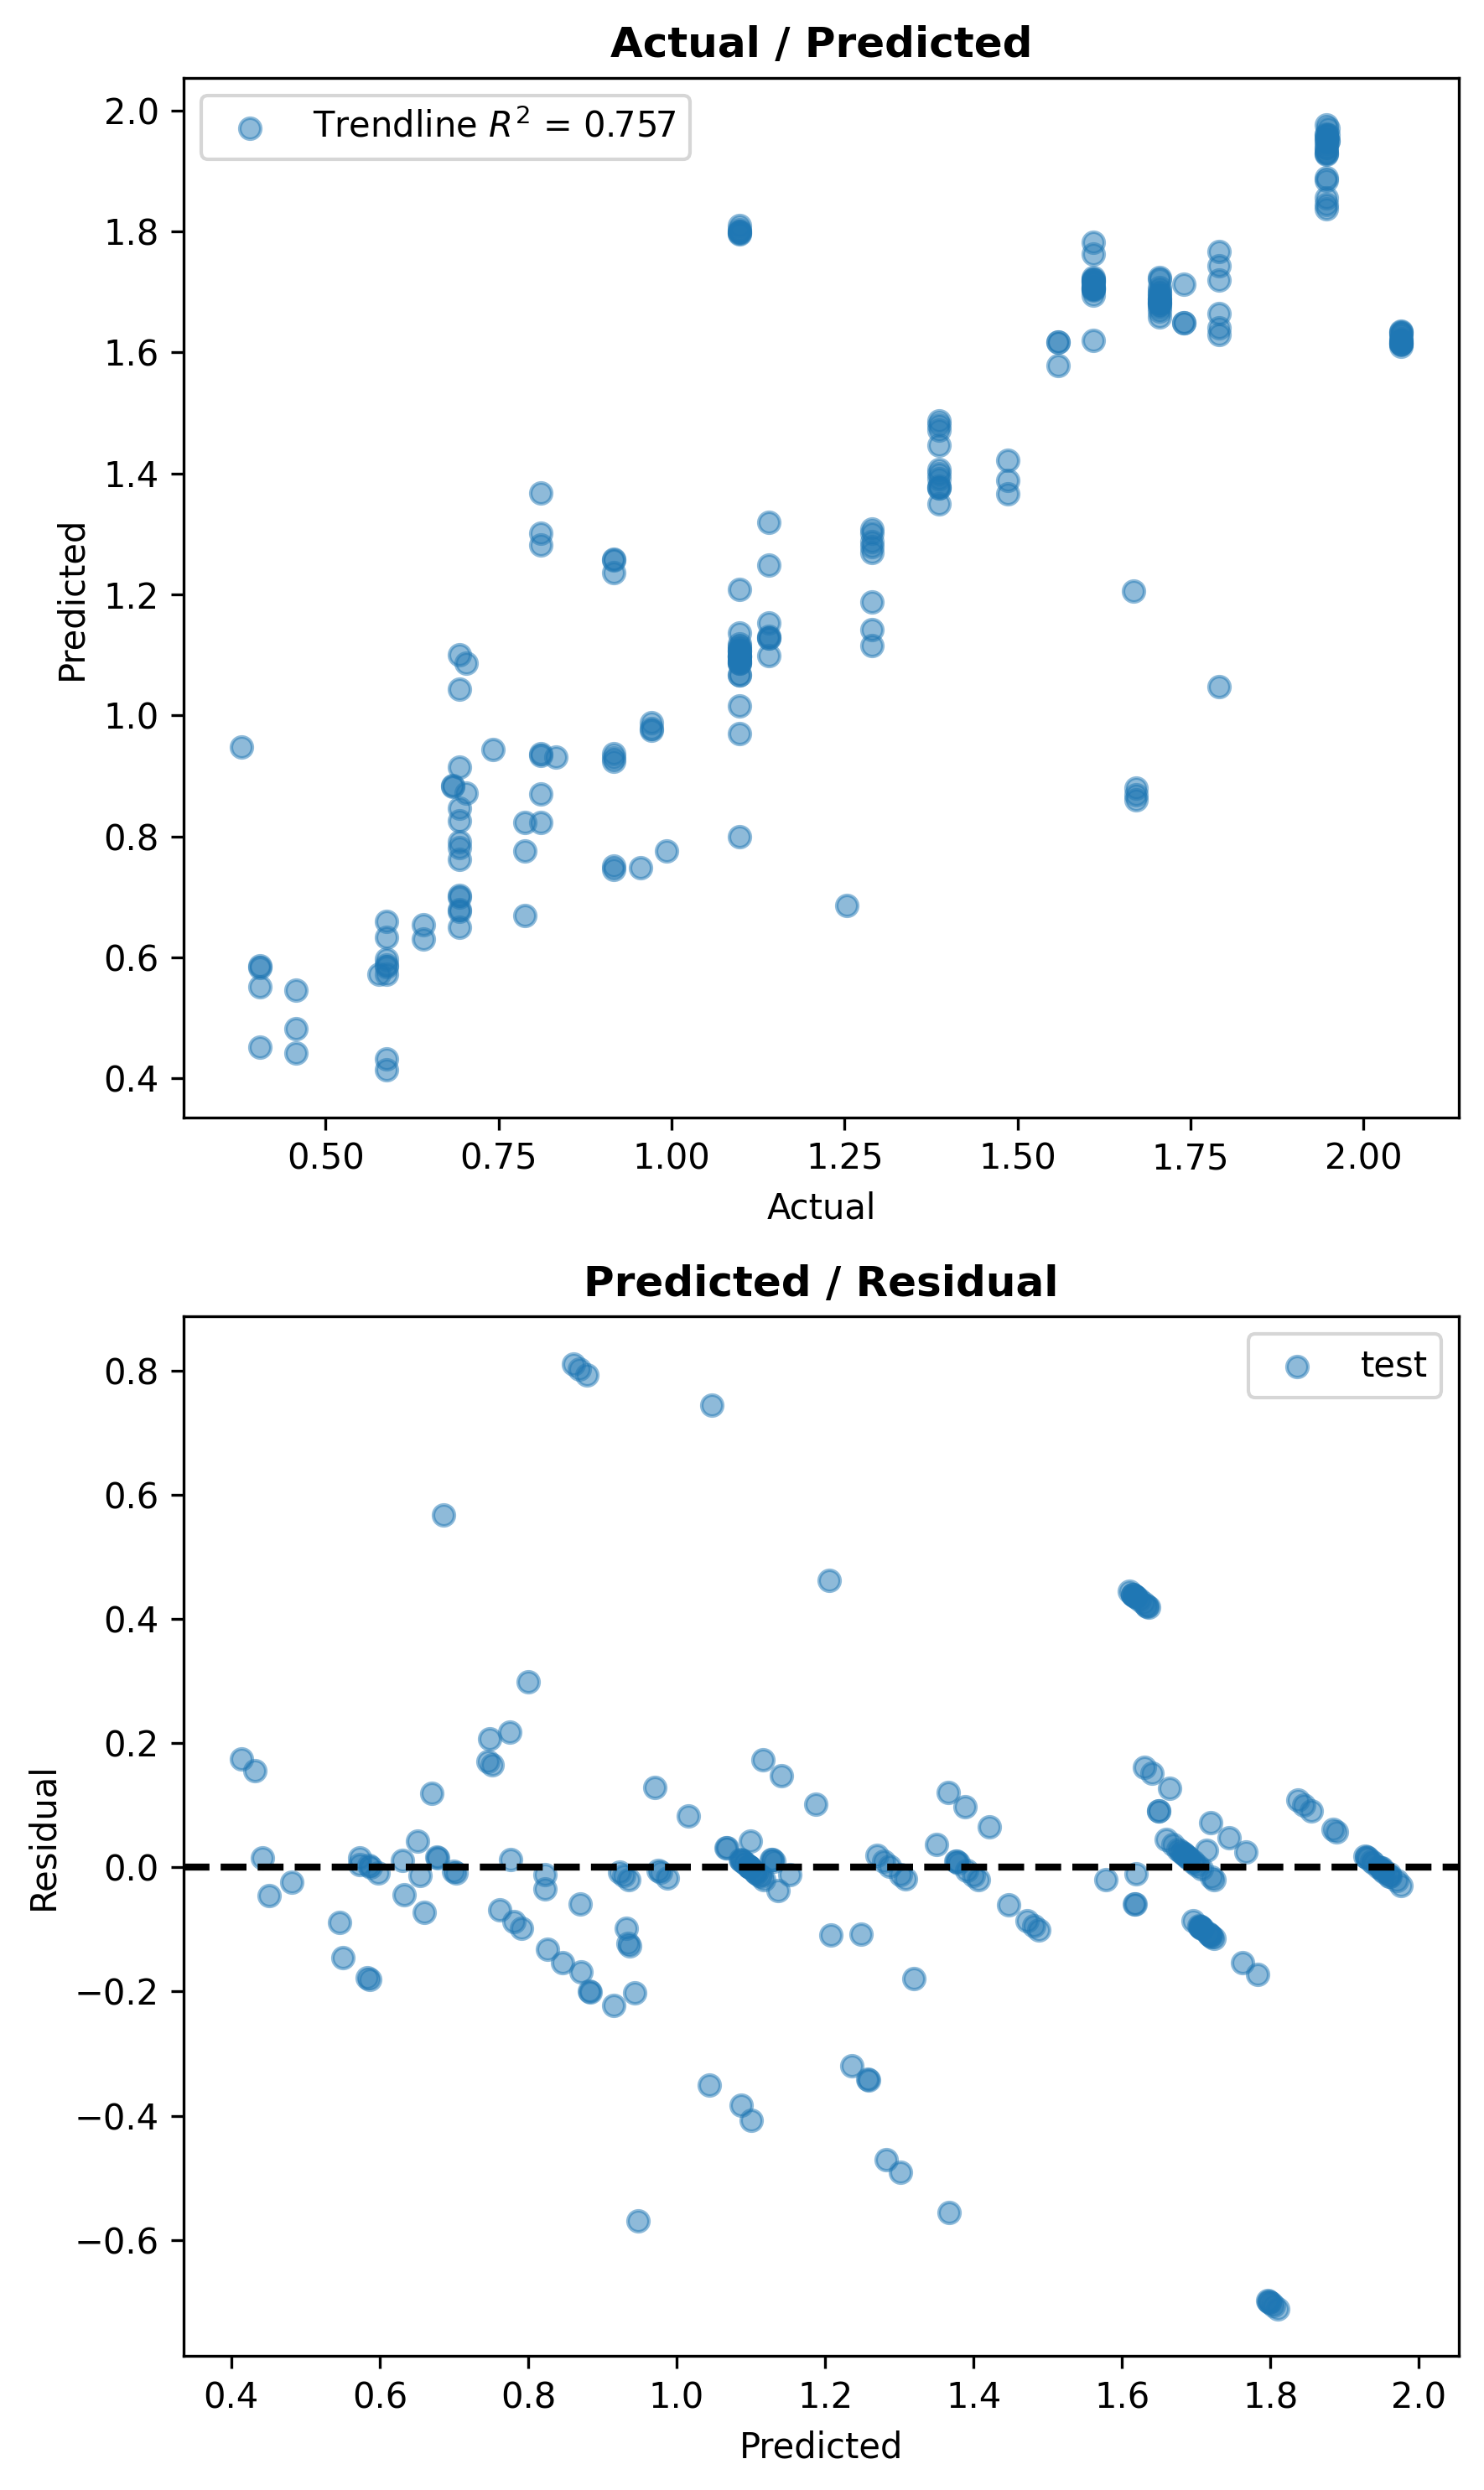

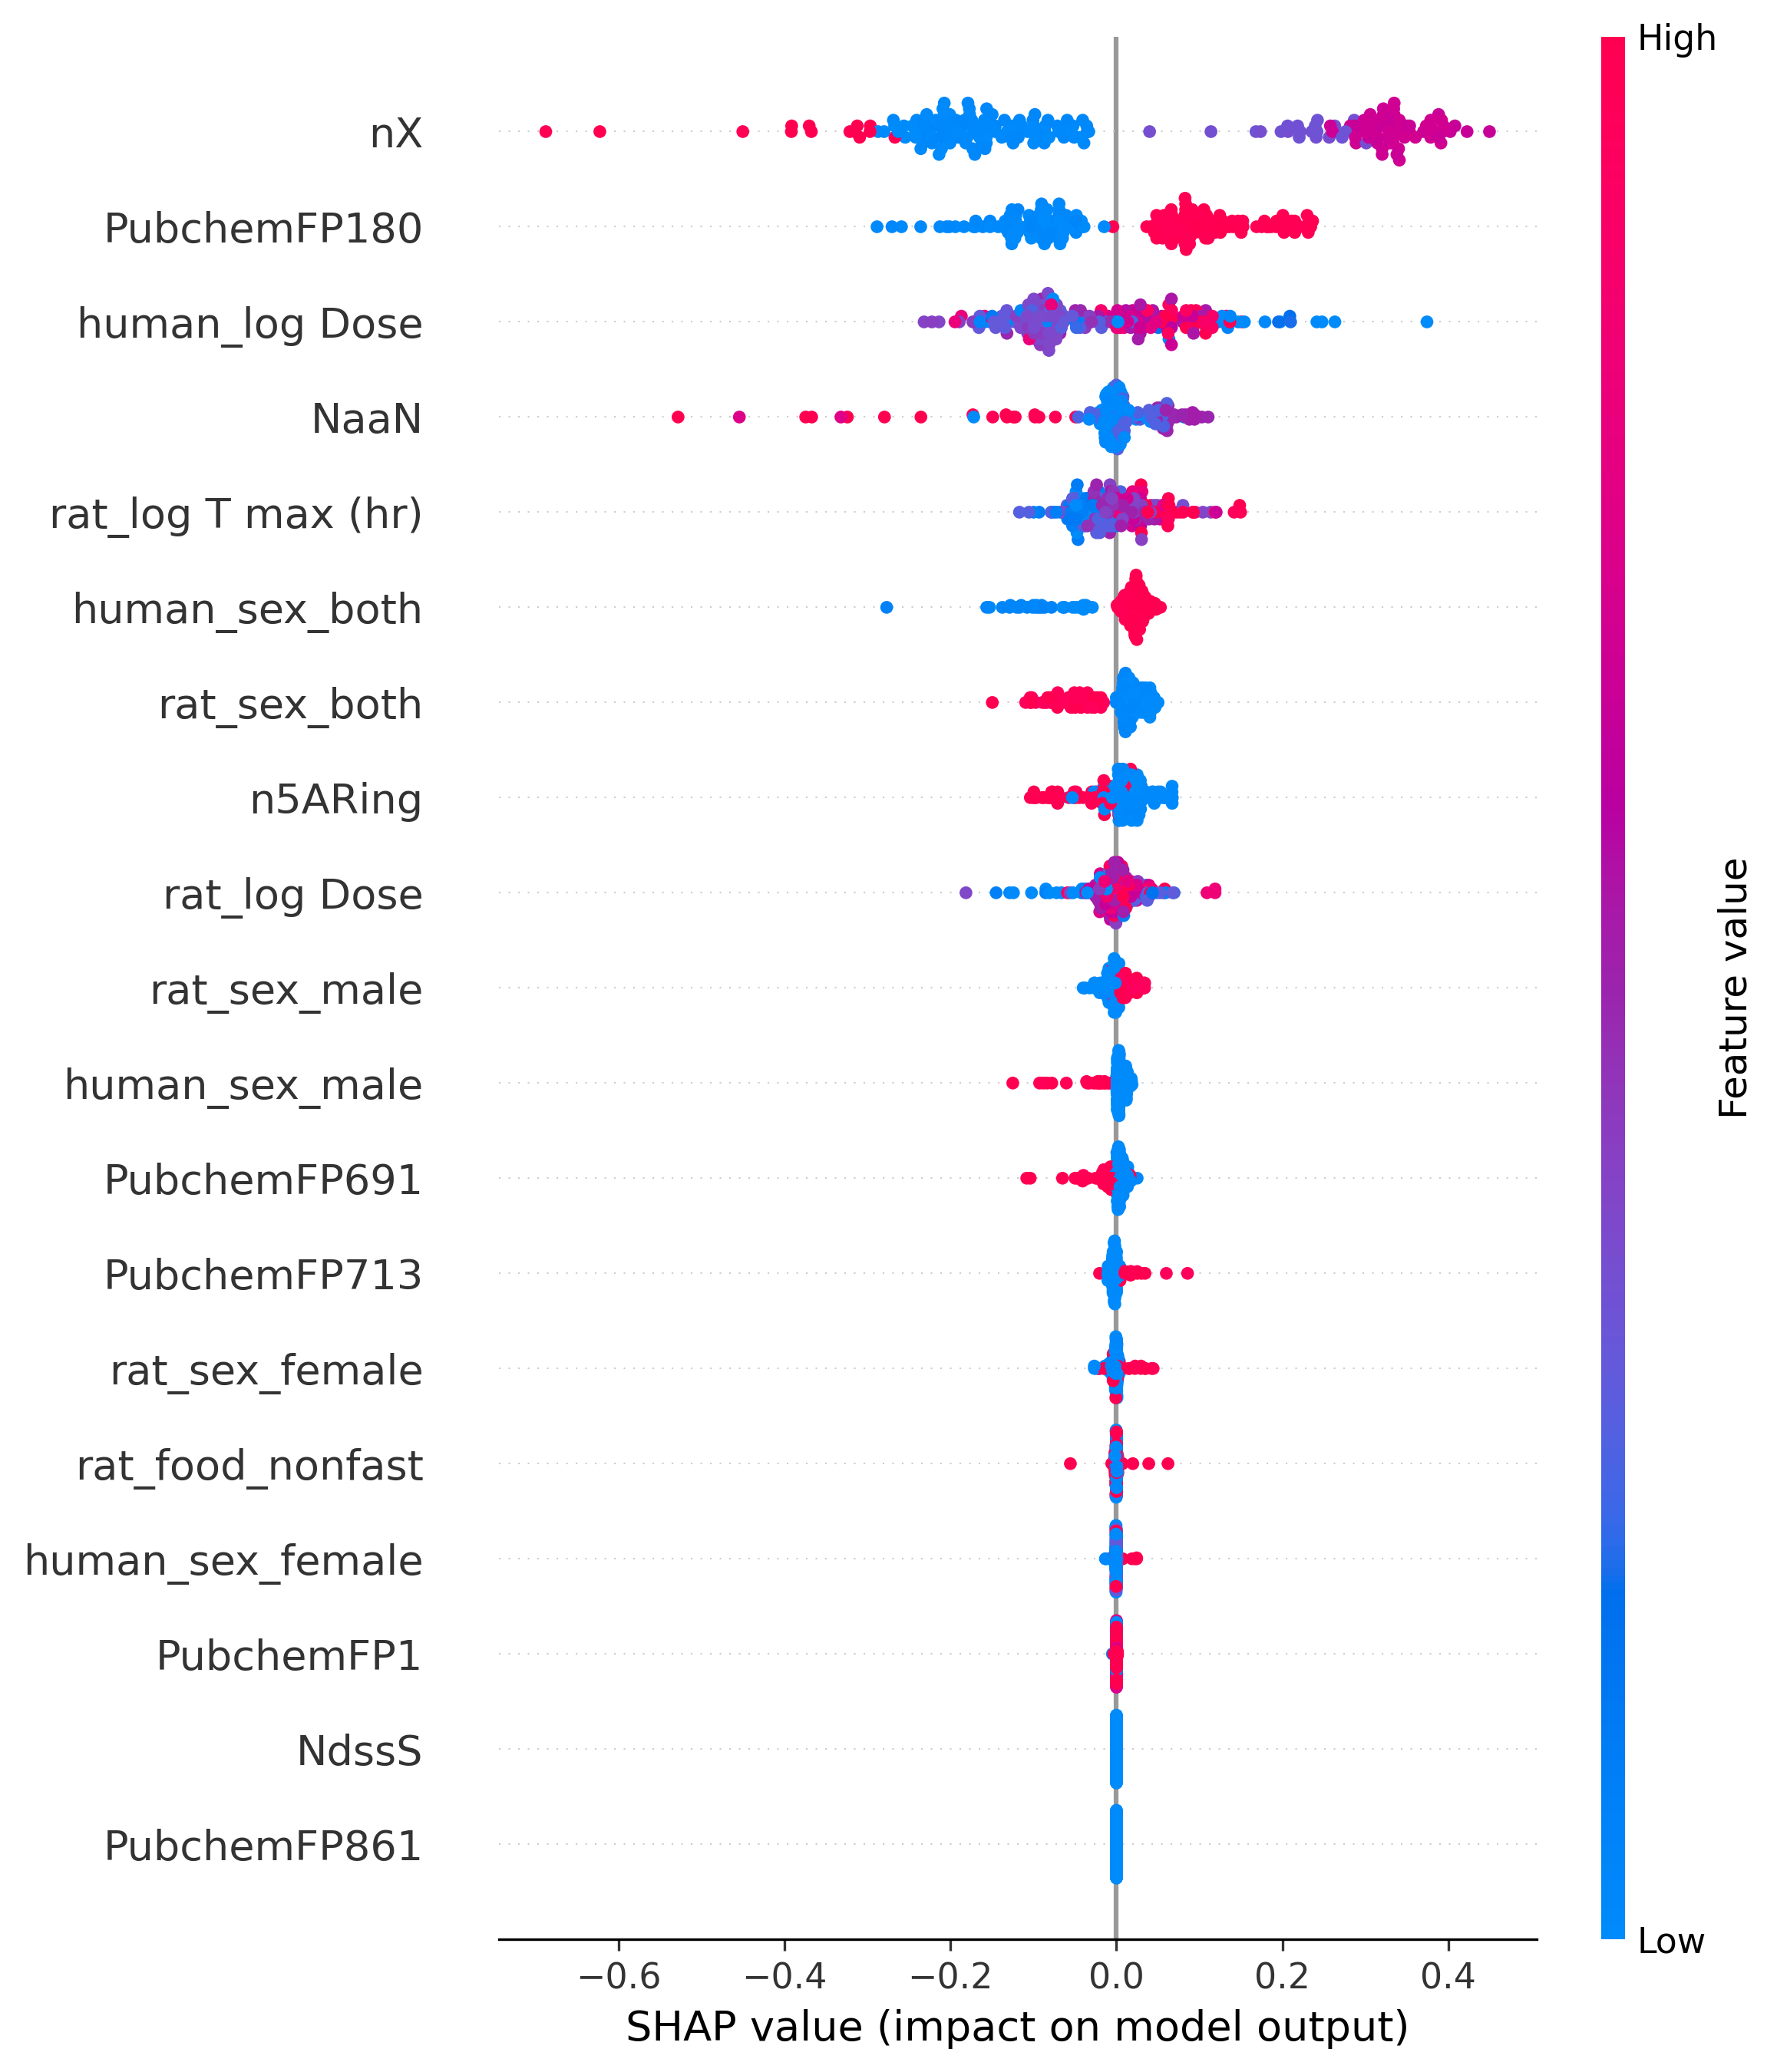

In [146]:
print('Tmax CV 10 fold')
model_name = "XGBoost"
y_true_all = np.array(results[model_name]['y_true_all'])
y_pred_all = np.array(results[model_name]['y_pred_all'])
print('\nFor', model_name)
plot_residual_for_kfold_cv(y_true_all, y_pred_all)

plt.figure(dpi=300)
final_shap_matrix = np.vstack(oof_shap_values)
final_X_scaled_df = pd.concat(oof_X_test_scaled, axis=0)
shap.summary_plot(final_shap_matrix, final_X_scaled_df)

# pprint(results_all_folds_seperated)

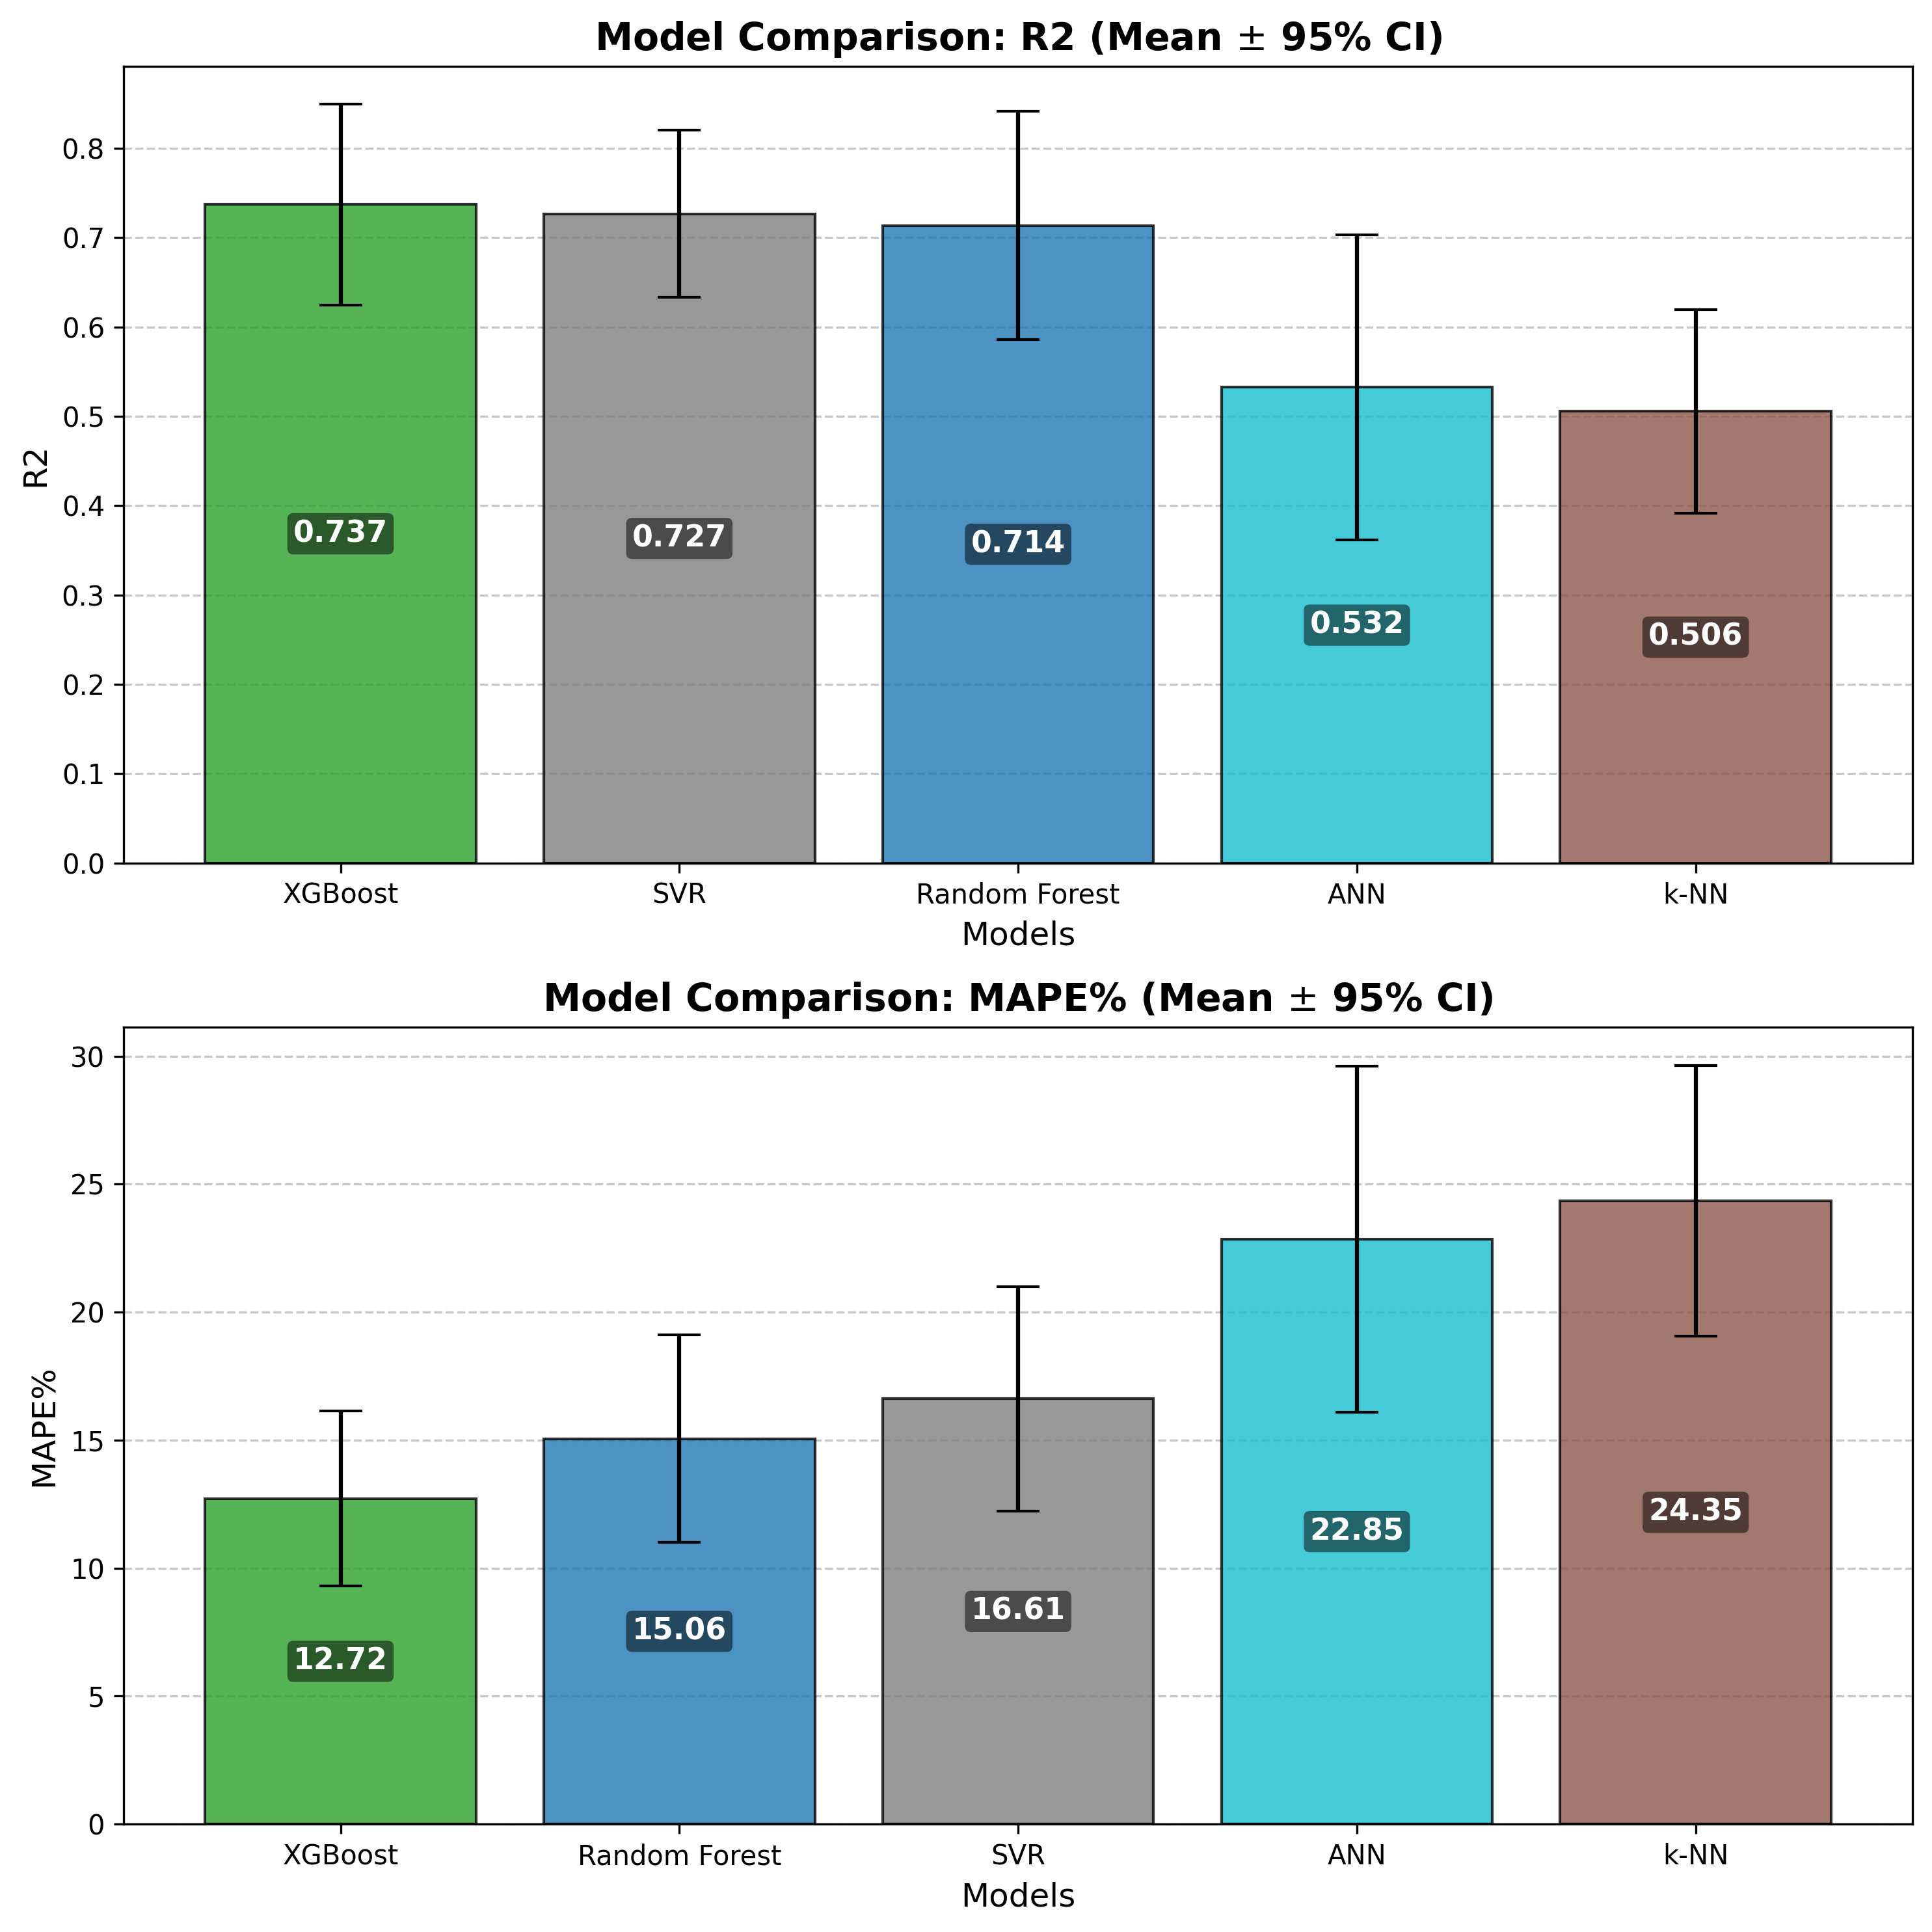

In [147]:
plot_cv_results_with_ci(results_all_folds_seperated, metrics_to_plot=['R2', 'MAPE%'])

=== Tmax R2 with bootstrap CI  (cluster bootstrap by drug, n_boot=5000) ===


,R2,CI 95% low,CI 95% high,Bootstrap SE
XGBoost,0.756,0.542,0.933,0.103
SVR,0.742,0.571,0.877,0.080
Random Forest,0.733,0.524,0.910,0.101
ANN,0.558,0.233,0.729,0.128
k-NN,0.541,0.224,0.716,0.127



=== Tmax Pairwise ΔR2 (paired bootstrap, p adjusted by: holm) ===


,Model A,Model B,ΔR2 (A-B),CI low,CI high,p (raw),p (holm),Significant
0,XGBoost,SVR,0.014,-0.067,0.123,0.7317,1.0000,False
1,XGBoost,Random Forest,0.023,-0.014,0.084,0.2438,0.9750,False
2,XGBoost,ANN,0.198,0.077,0.493,0.0002,0.0020,True
3,XGBoost,k-NN,0.215,0.064,0.527,0.0050,0.0300,True
4,SVR,Random Forest,0.009,-0.089,0.089,0.8496,1.0000,False
5,SVR,ANN,0.184,0.099,0.404,0.0002,0.0020,True
6,SVR,k-NN,0.201,0.085,0.448,0.0002,0.0020,True
7,Random Forest,ANN,0.175,0.054,0.449,0.0026,0.0182,True
8,Random Forest,k-NN,0.192,0.045,0.487,0.0086,0.0430,True
9,ANN,k-NN,0.017,-0.131,0.159,0.8380,1.0000,False


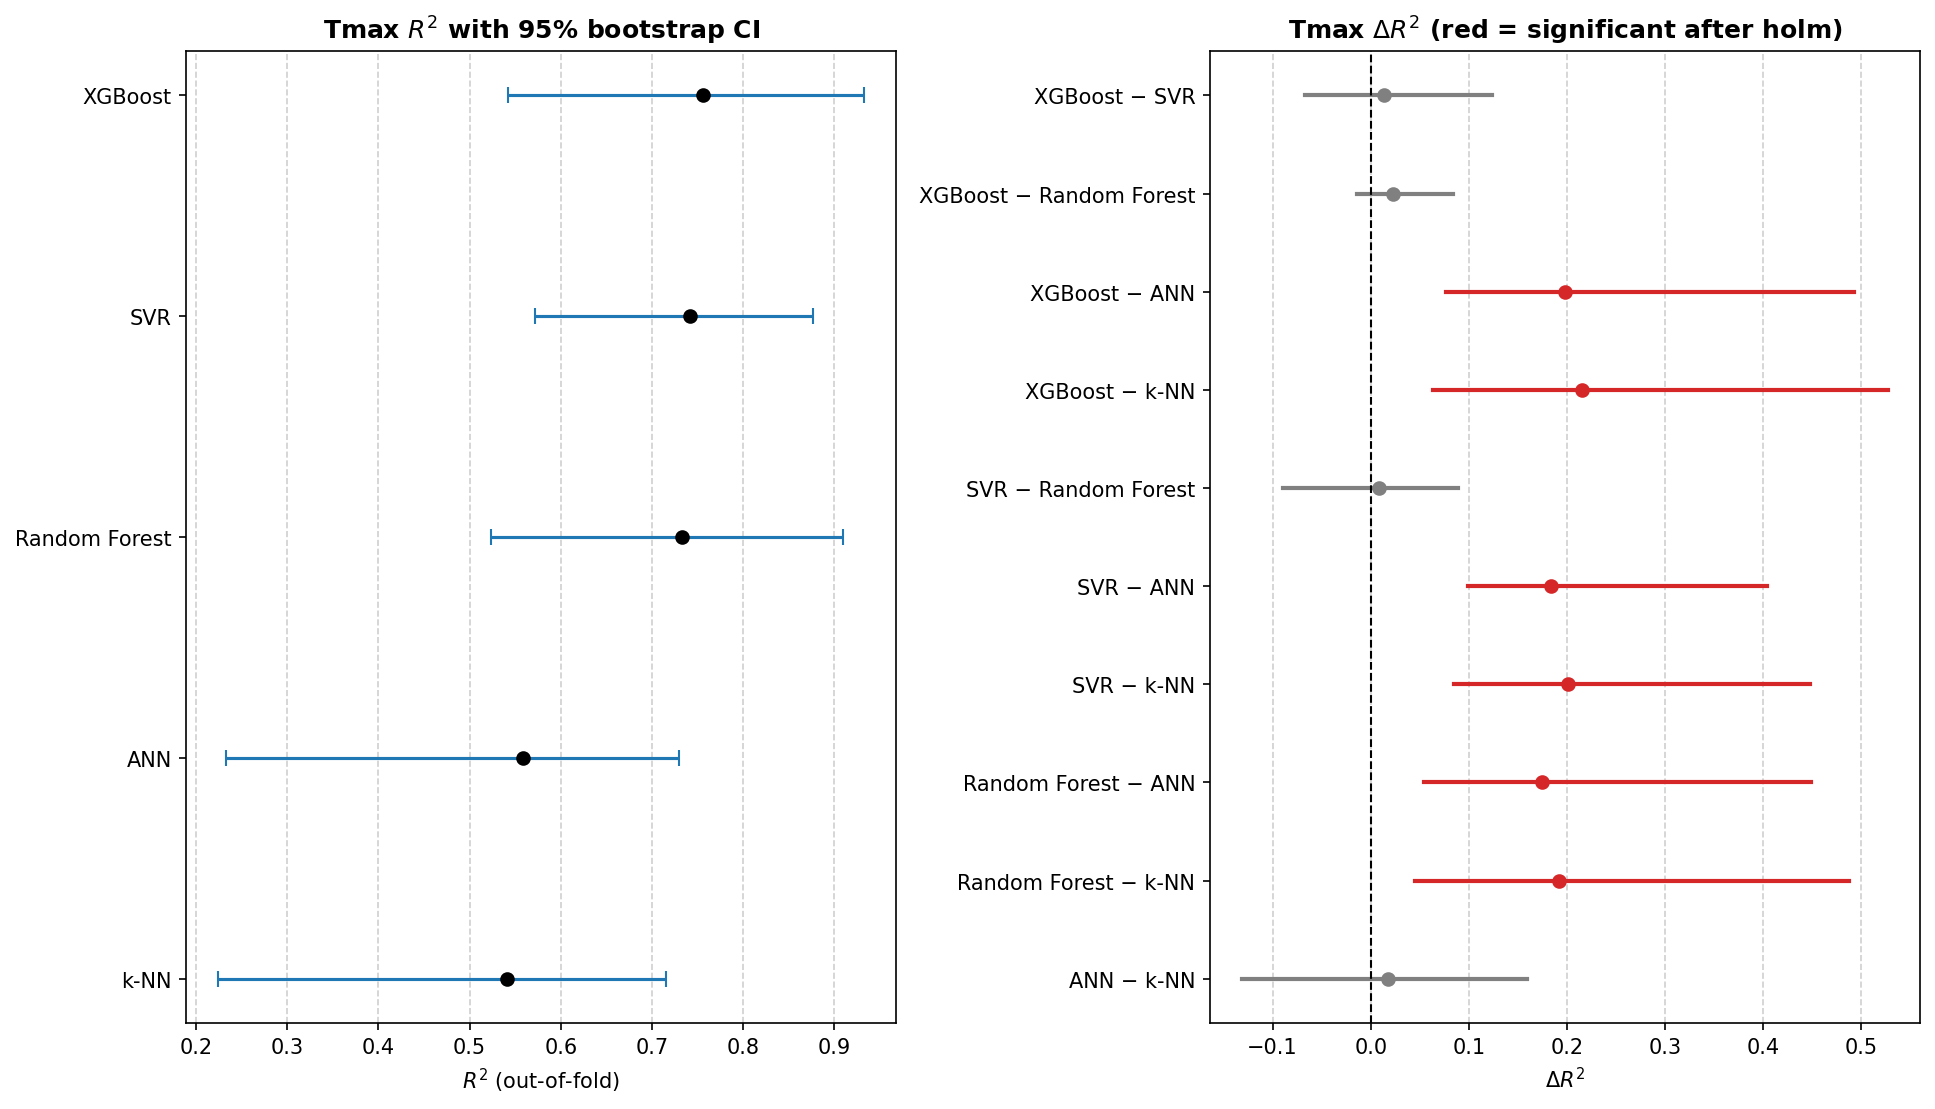

In [148]:
# Tmax: paired cluster-bootstrap comparison of R2 between models
# Run this right after the nested 10-fold CV cell above (it uses `results`, `kf`, `X` and `df` from that cell)

# Row order of y_true_all / y_pred_all = order of the test folds of kf
oof_order = np.concatenate([test_idx for _, test_idx in kf.split(X)])
# Resample whole drugs, because rows (doses) of the same drug are not independent
drug_groups = df['Parent_SMILES'].values[oof_order]

r2_table_tmax, diff_table_tmax, boot_tmax = compare_models_r2_bootstrap(
    results,
    groups=drug_groups,      # set to None for an ordinary row-wise bootstrap
    n_boot=5000,
    comparisons='all',       # 'all' = every pair of models, 'vs_best' = best model vs each other model
    p_adjust='holm',         # 'holm' (recommended), 'bonferroni', 'fdr_bh' or None
    alpha=0.05,
    title='Tmax',
)

# with pd.ExcelWriter('Tmax_bootstrap_R2_comparison.xlsx') as writer:
#     r2_table_tmax.to_excel(writer, sheet_name='R2 with CI')
#     diff_table_tmax.to_excel(writer, sheet_name='Pairwise dR2', index=False)


In [149]:
# All Points not each fold
pd.DataFrame(np.abs(y_true_all - y_pred_all)/y_true_all*100, columns = ['Relative Error%']).to_excel('Tmax_for_each_point_RE%.xlsx')

In [150]:
# Predicting for compound 4a: After training on ALL dataset

X = df[cols[1:-1]] # Without DrugName and Target Column
y = df[cols[-1]]
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)
X_train, y_train = X, y
X_for_my_drug_4a = MY_DF[cols[1:-1]]

print("shape of X_train, y_train")
print(X_train.shape, y_train.shape)
models = {
    # "Linear Regression": LinearRegression(),
    # "Linear (Ridge)": Ridge(alpha=1.0),
    # "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=10, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42),
    # "k-NN (Similarity)": KNeighborsRegressor(n_neighbors=5),
    # "SVR (Support Vector)": SVR(kernel='rbf', C=10, epsilon=0.1),
    # "ANN (MLP)": MLPRegressor(hidden_layer_sizes=(20, 5), max_iter=2000, random_state=42),
    # "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), 

}

# 4. Loop through each model and evaluate using LOGOCV
for model_name, model in models.items():
    print(f"Evaluating {model_name}...")
    
    # Create a pipeline that standardizes the data THEN fits the model
    # This ensures no data leakage during cross-validation
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', model)
    ])
    
    
    y_true_all = []
    y_pred_all = []
    
    pipeline.fit(X_train, y_train)

    y_pred_for_my_drug_4a = pipeline.predict(X_for_my_drug_4a)
        
# 5. Display the final results as a DataFrame
print("\n--- Tmax Predicted results for compound 4a ---")
pd.DataFrame((DOSES, y_pred_for_my_drug_4a, np.exp(y_pred_for_my_drug_4a)-1)).T.style.format("{:.3f}")

shape of X_train, y_train
(201, 19) (201,)
Evaluating XGBoost...

--- Tmax Predicted results for compound 4a ---


,0,1,2
0,28.200,0.704,1.023
1,56.400,0.744,1.103
2,112.800,0.722,1.058
3,169.200,0.646,0.908
4,225.600,0.655,0.925
